# CAETEC · Análisis integral de posible cola

Analizamos pronósticos ARIMA/SARIMA, patrones temporales, lactancia y minutos desde alimento.
Cada fila es un bloque de 30 minutos de un robot, posible cola significa pct_posible_cola > 0.5.
El indicador no mide directamente vacas esperando ni los minutos de espera.

## 1. Preparación común

Ejecuta las celdas en orden. Los cuatro análisis comparten el dataset, el umbral y los cortes cronológicos.

### 1.1 Librerías y configuración

Importa las librerías para cargar datos, ajustar modelos, evaluar predicciones y realizar pruebas estadísticas.

In [ ]:
import sys
from pathlib import Path
from time import perf_counter
import gc
import warnings
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from scipy.special import expit
from scipy.stats import t as t_student
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    precision_score,
    r2_score,
    recall_score,
)
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.kalman_filter import (
    MEMORY_NO_FILTERED,
    MEMORY_NO_GAIN,
    MEMORY_NO_PREDICTED_COV,
    MEMORY_NO_SMOOTHING,
)
from statsmodels.tsa.stattools import acf, adfuller, kpss
from threadpoolctl import threadpool_limits
from IPython.display import display

Fija el umbral real, la frecuencia temporal y el formato de las salidas para todos los análisis.

In [ ]:
UMBRAL_REAL = 0.5
FRECUENCIA = "30min"
OBJETIVO = "pct_posible_cola"
_hilos = threadpool_limits(limits=1)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.options.display.float_format = "{:.4g}".format

### 1.2 Carga del dataset

En Colab leemos Datos/Procesado desde Drive. En local usamos ../../data respecto al directorio del notebook.
El archivo esperado es dataset_final_serie_tiempo.parquet.

Selecciona la ruta de datos según el entorno: Drive en Colab o ../../data en ejecución local.

In [ ]:
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("Mount Colab")
    from google.colab import drive

    drive.mount("/content/drive")
    RUTA_DATOS = Path("/content/drive/My Drive/Datos/Procesado")
else:
    print("Running local")
    RUTA_DATOS = Path.cwd() / ".." / ".." / "data"
print(RUTA_DATOS)

Running local
/workspace/scratch/19a90221836a/qa_revision/notebooks/modelado/../../data


La ejecución registrada utiliza la ruta local. La selección de ruta cambia dónde se lee el archivo, no la definición del análisis.

Carga el parquet, convierte las fechas y ordena los bloques por tiempo y robot.

In [ ]:
def load_dataset(file="dataset_final_serie_tiempo.parquet"):
    dataset_final = pd.read_parquet(Path(RUTA_DATOS) / file)
    dataset_final["bloque_tiempo"] = pd.to_datetime(dataset_final["bloque_tiempo"])
    dataset_final = dataset_final.sort_values(["bloque_tiempo", "ms"]).reset_index(drop=True)
    print(f"dataset_final: {len(dataset_final):,} bloques x {dataset_final.shape[1]} columnas")
    print(list(dataset_final.columns))
    return dataset_final


datos_originales = load_dataset()

dataset_final: 179,850 bloques x 24 columnas
['ms', 'bloque_tiempo', 'total_ordenios', 'produccion_promedio', 'duracion_total_min', 'patadas_totales', 'desviaciones_leche_totales', 'ordenios_con_lavado', 'pct_primer_parto', 'pct_fresca', 'pct_alta', 'pct_baja', 'pct_extendida', 'hubo_ordenios', 'pct_ocupacion_robot', 'hubo_lavado', 'ordenios_otros_robots', 'hora', 'dia_semana', 'temporada', 'min_desde_alimento', 'vacas_activas_dia', 'sin_etapa', 'pct_posible_cola']


Se cargaron 179,850 bloques y 24 columnas; se continúa con esta misma entrada para mantener comparables las cuatro secciones.

### 1.3 Calidad y calendario compartido

Conservamos la malla de 30 minutos y los bloques sin ordeños. Los cortes 70/15/15 se aplican por instante completo,
con las mismas fechas para los tres robots. Un valor exactamente igual a 0.5 se clasifica como negativo.

Valida columnas, duplicados y continuidad temporal; construye el calendario y las particiones compartidas.

In [ ]:
def preparar_base(datos):
    requeridas = [
        "ms",
        "bloque_tiempo",
        OBJETIVO,
        "hubo_ordenios",
        "min_desde_alimento",
        "total_ordenios",
        "sin_etapa",
        "pct_primer_parto",
        "pct_fresca",
        "pct_alta",
        "pct_baja",
        "pct_extendida",
    ]
    if not set(requeridas).issubset(datos.columns):
        raise ValueError(f"Faltan columnas: {set(requeridas) - set(datos.columns)}")
    base = datos.copy()
    base["bloque_tiempo"] = pd.to_datetime(base["bloque_tiempo"])
    base = base.sort_values(["bloque_tiempo", "ms"]).reset_index(drop=True)
    if base[requeridas].isna().any().any() or base.duplicated(["ms", "bloque_tiempo"]).any():
        raise ValueError("Revisa faltantes o duplicados en las variables del análisis.")
    if not base[OBJETIVO].between(0, 1).all() or not base["hubo_ordenios"].isin([0, 1]).all():
        raise ValueError("Hay valores fuera del rango esperado.")
    if not base.loc[base["hubo_ordenios"].eq(0), OBJETIVO].eq(0).all():
        raise ValueError("El indicador de bloques sin ordeños requiere revisión.")
    for robot, grupo in base.groupby("ms"):
        esperado = pd.date_range(
            grupo["bloque_tiempo"].min(), grupo["bloque_tiempo"].max(), freq=FRECUENCIA
        )
        if not pd.DatetimeIndex(grupo["bloque_tiempo"]).equals(esperado):
            raise ValueError(f"Revisa la malla temporal de {robot}.")
    fechas = pd.DatetimeIndex(base["bloque_tiempo"].unique()).sort_values()
    corte_train, corte_val = (int(len(fechas) * 0.7), int(len(fechas) * 0.85))
    inicio_val, inicio_test = (fechas[corte_train], fechas[corte_val])
    base["Conjunto"] = np.where(
        base["bloque_tiempo"] < inicio_val,
        "Entrenamiento",
        np.where(base["bloque_tiempo"] < inicio_test, "Validación", "Prueba"),
    )
    base["cola"] = base[OBJETIVO].gt(UMBRAL_REAL).astype(int)
    base["franja"] = base["bloque_tiempo"].dt.hour * 2 + base["bloque_tiempo"].dt.minute // 30
    base["dia_semana"] = base["bloque_tiempo"].dt.dayofweek
    base["mes"] = base["bloque_tiempo"].dt.to_period("M").astype(str)
    horarios = {f: f"{f // 2:02d}:{30 * (f % 2):02d}" for f in range(48)}
    base["Horario"] = base["franja"].map(horarios)
    resumen = (
        base.groupby("Conjunto")
        .agg(
            Registros=(OBJETIVO, "size"),
            Inicio=("bloque_tiempo", "min"),
            Fin=("bloque_tiempo", "max"),
            Frecuencia_cola_pct=("cola", lambda x: 100 * x.mean()),
        )
        .reindex(["Entrenamiento", "Validación", "Prueba"])
    )
    calendario = {
        "fechas": fechas,
        "fechas_train": fechas[:corte_train],
        "fechas_val": fechas[corte_train:corte_val],
        "fechas_test": fechas[corte_val:],
        "INICIO_VAL": inicio_val,
        "INICIO_TEST": inicio_test,
        "robots": sorted(base["ms"].unique()),
        "horarios": horarios,
        "resumen_particiones": resumen,
        "requeridas": ["bloque_tiempo", "ms", OBJETIVO, "hubo_ordenios"],
    }
    return (base, calendario)


base, calendario = preparar_base(datos_originales)

Muestra el tamaño, las fechas y la frecuencia de posible cola de cada partición.

In [ ]:
display(calendario["resumen_particiones"].reset_index())

,Conjunto,Registros,Inicio,Fin,Frecuencia_cola_pct
0,Entrenamiento,125892,2022-08-01 00:00:00,2024-12-22 06:30:00,14.66
1,Validación,26979,2024-12-22 07:00:00,2025-06-27 15:00:00,42.54
2,Prueba,26979,2025-06-27 15:30:00,2025-12-31 23:30:00,57.53


La frecuencia positiva sube de 14.66% en entrenamiento a 57.53% en prueba. Este cambio de nivel exige comparar con referencias simples y revisar el desempeño por periodo.

Grafica la posición cronológica de entrenamiento, validación y prueba para comprobar que no se superponen.

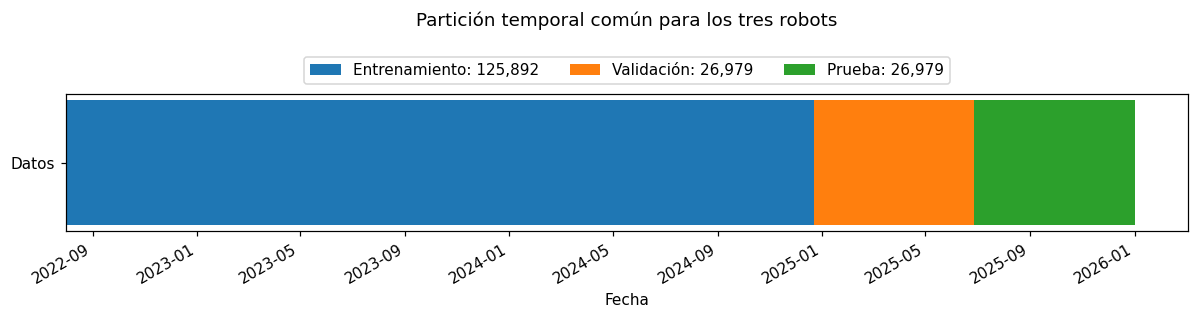

In [ ]:
def graficar_particiones(calendario):
    fig, ax = plt.subplots(figsize=(11, 3))
    for nombre, fila in calendario["resumen_particiones"].iterrows():
        duracion = fila["Fin"] - fila["Inicio"] + pd.Timedelta(FRECUENCIA)
        ax.barh("Datos", duracion, left=fila["Inicio"], label=f"{nombre}: {fila['Registros']:,}")
    ax.set_title("Partición temporal común para los tres robots", pad=45)
    ax.set_xlabel("Fecha")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3)
    fig.autofmt_xdate()
    fig.tight_layout()
    return fig


fig = graficar_particiones(calendario)
plt.show()
plt.close(fig)

Las particiones respetan el tiempo y comparten cortes entre robots. Se conserva este diseño para evaluar con pasado disponible, sin mezclar observaciones futuras.

Define un estado independiente para cada análisis, conservando la misma entrada, fechas y umbral.

In [ ]:
def iniciar_analisis(base, calendario):
    return {
        **calendario,
        "datos": base.copy(),
        "UMBRAL_REAL": UMBRAL_REAL,
        "OBJETIVO": OBJETIVO,
        "FRECUENCIA": FRECUENCIA,
    }

La validación y la prueba ya se han consultado en los análisis anteriores. Su revisión conjunta es retrospectiva.
Los análisis de lactancia y alimento describen asociaciones históricas y no constituyen nuevas evaluaciones predictivas.

## 2. ARIMA y SARIMA

Pronosticamos el indicador del siguiente bloque por robot y comparamos con persistencia, mismo bloque del día anterior y siempre cola.
El umbral real queda unificado en 0.5; los umbrales predictivos se seleccionan con validación.

### 2.1 Configuración y series por robot

Configura el ciclo diario, los cinco cortes de validación, los umbrales candidatos y el horizonte futuro.

In [ ]:
arima = iniciar_analisis(base, calendario)
arima.update(
    {
        "ESTACIONALIDAD": 48,
        "N_CORTES": 5,
        "META_F1": 0.6,
        "UMBRALES": np.linspace(0, 1, 101),
        "PASOS_FUTUROS": 4,
    }
)

Construye una serie regular del indicador y otra de actividad para cada robot, sin inventar bloques anteriores a su inicio.

In [ ]:
def arima_preparar_series(estado):
    """Valida y construye las series regulares de cada robot."""
    FRECUENCIA = estado["FRECUENCIA"]
    OBJETIVO = estado["OBJETIVO"]
    datos = estado["datos"]
    requeridas = estado["requeridas"]
    if datos[requeridas].isna().any().any():
        raise ValueError("Hay faltantes en las columnas utilizadas. Revisa su origen.")
    if datos.duplicated(["bloque_tiempo", "ms"]).any():
        raise ValueError("Hay bloques duplicados por robot.")
    if not datos[OBJETIVO].between(0, 1).all():
        raise ValueError("El indicador debe estar entre 0 y 1.")
    if not datos["hubo_ordenios"].isin([0, 1]).all():
        raise ValueError("hubo_ordenios debe ser binaria.")
    if not datos.loc[datos["hubo_ordenios"].eq(0), OBJETIVO].eq(0).all():
        raise ValueError("Revisa los objetivos de los bloques sin ordeños.")
    series = {}
    actividad = {}
    for robot, grupo in datos.groupby("ms", sort=True):
        grupo = grupo.set_index("bloque_tiempo").sort_index()
        esperado = pd.date_range(grupo.index.min(), grupo.index.max(), freq=FRECUENCIA)
        if not grupo.index.equals(esperado):
            raise ValueError(f"Revisa la malla temporal de {robot}.")
        series[robot] = grupo[OBJETIVO].astype(float).asfreq(FRECUENCIA)
        actividad[robot] = grupo["hubo_ordenios"].asfreq(FRECUENCIA)
    robots = sorted(series)
    inventario = datos.groupby("ms").agg(
        Bloques=(OBJETIVO, "size"),
        Inicio=("bloque_tiempo", "min"),
        Fin=("bloque_tiempo", "max"),
        Sin_ordenios=("hubo_ordenios", lambda s: s.eq(0).sum()),
    )
    return {"series": series, "actividad": actividad, "robots": robots, "inventario": inventario}


arima.update(arima_preparar_series(arima))

Muestra la cobertura temporal y el número de bloques sin ordeños de cada robot.

In [ ]:
display(arima["inventario"])

,Bloques,Inicio,Fin,Sin_ordenios
ms,,,,
VMS 1,59950,2022-08-01 01:00:00,2025-12-31 23:30:00,14975
VMS 2,59948,2022-08-01 02:00:00,2025-12-31 23:30:00,16777
VMS 3,59952,2022-08-01 00:00:00,2025-12-31 23:30:00,16040


Los robots comienzan en horas ligeramente distintas y mantienen bloques sin ordeños. Se modelan por separado y no se agregan ceros antes del inicio de cada serie.

### 2.2 Diagnóstico temporal en entrenamiento

Revisamos cambios mensuales, horarios, estacionariedad y autocorrelación usando solo entrenamiento.
ADF y KPSS contrastan hipótesis distintas; su discrepancia impide decidir la diferenciación con una sola prueba.

Selecciona el entrenamiento para explorar patrones antes de consultar la evaluación de prueba.

In [ ]:
def arima_preparar_perfiles_entrenamiento(estado):
    datos = estado["datos"]
    train = datos.loc[datos["Conjunto"].eq("Entrenamiento")].copy()
    return {"train": train}


arima.update(arima_preparar_perfiles_entrenamiento(arima))

Grafica la evolución mensual y el perfil horario del indicador continuo durante el entrenamiento.

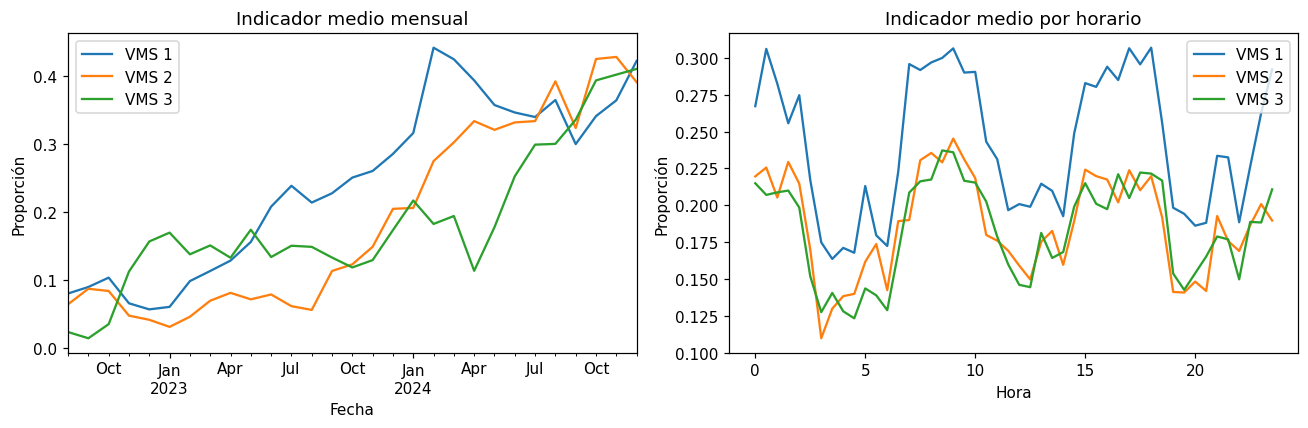

In [ ]:
def arima_graficar_perfiles_entrenamiento(estado):
    INICIO_VAL = estado["INICIO_VAL"]
    robots = estado["robots"]
    series = estado["series"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for robot in robots:
        y = series[robot].loc[lambda s: s.index < INICIO_VAL]
        y.resample("MS").mean().plot(ax=axes[0], label=robot)
        perfil = y.groupby(y.index.hour + y.index.minute / 60).mean()
        axes[1].plot(perfil.index, perfil, label=robot)
    axes[0].set(title="Indicador medio mensual", ylabel="Proporción", xlabel="Fecha")
    axes[1].set(title="Indicador medio por horario", xlabel="Hora", ylabel="Proporción")
    axes[0].legend()
    axes[1].legend()
    plt.tight_layout()
    return fig


fig = arima_graficar_perfiles_entrenamiento(arima)
plt.show()
plt.close(fig)

El indicador aumenta entre meses y presenta perfiles horarios distintos entre robots. Se exploran modelos separados y cambios de nivel, además del ciclo diario.

Calcula ADF, KPSS y autocorrelaciones de corto plazo, diarias y semanales para cada robot.

In [ ]:
def arima_diagnosticar_series(estado):
    INICIO_VAL = estado["INICIO_VAL"]
    robots = estado["robots"]
    series = estado["series"]
    diagnosticos = []
    for robot in robots:
        y = series[robot].loc[lambda s: s.index < INICIO_VAL]
        with warnings.catch_warnings(record=True) as avisos:
            adf = adfuller(y, maxlag=48, autolag="AIC")
            kps = kpss(y, regression="c", nlags="auto")
        correlaciones = acf(y, nlags=336, fft=True)
        diagnosticos.append(
            {
                "Robot": robot,
                "ADF_p": adf[1],
                "KPSS_p": kps[1],
                "ACF_1": correlaciones[1],
                "ACF_48": correlaciones[48],
                "ACF_336": correlaciones[336],
                "ACF_48_diferencia": acf(y.diff().dropna(), nlags=48, fft=True)[48],
                "Avisos": " | ".join((str(a.message) for a in avisos)),
            }
        )
    diagnostico = pd.DataFrame(diagnosticos)
    return {"diagnostico": diagnostico}


arima.update(arima_diagnosticar_series(arima))

Muestra los diagnósticos de estacionariedad y la autocorrelación diaria después de diferenciar.

In [ ]:
display(arima["diagnostico"].drop(columns="Avisos"))

,Robot,ADF_p,KPSS_p,ACF_1,ACF_48,ACF_336,ACF_48_diferencia
0,VMS 1,3.629e-13,0.01,0.1979,0.1885,0.1748,0.03153
1,VMS 2,1.13e-09,0.01,0.2404,0.2216,0.2153,0.01531
2,VMS 3,9.08e-15,0.01,0.1675,0.1551,0.1378,0.02547


ADF rechaza raíz unitaria, pero KPSS rechaza estacionariedad en nivel; la autocorrelación diaria cae al diferenciar. Se prueban d = 0 y d = 1 en lugar de decidir con una sola prueba.

Grafica ACF y PACF para revisar qué dependencia temporal conviene explorar en los modelos.

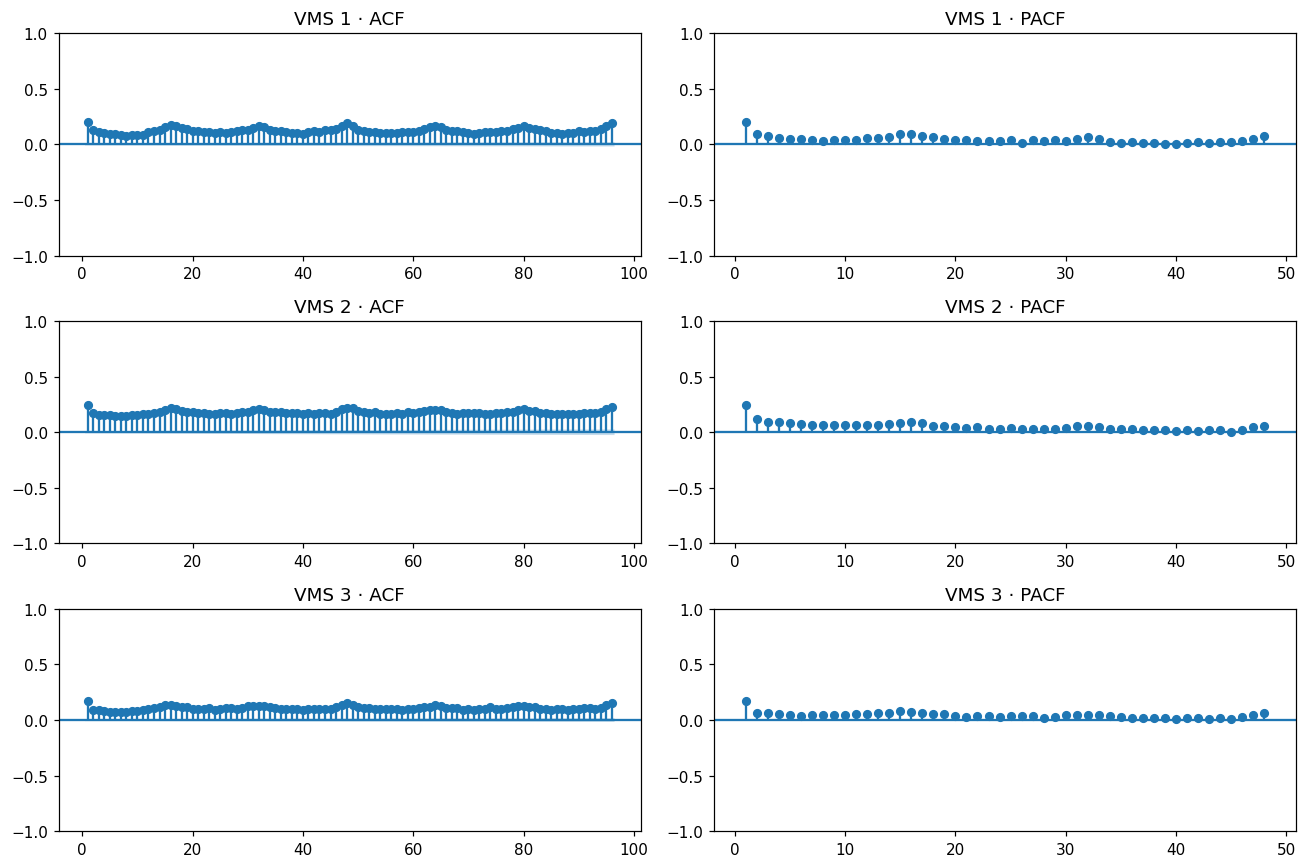

In [ ]:
def arima_graficar_acf_pacf(estado):
    INICIO_VAL = estado["INICIO_VAL"]
    robots = estado["robots"]
    series = estado["series"]
    fig, axes = plt.subplots(len(robots), 2, figsize=(12, 8))
    for fila, robot in enumerate(robots):
        y = series[robot].loc[lambda s: s.index < INICIO_VAL]
        plot_acf(y, lags=96, zero=False, ax=axes[fila, 0], title=f"{robot} · ACF")
        plot_pacf(y, lags=48, zero=False, method="ywm", ax=axes[fila, 1], title=f"{robot} · PACF")
    plt.tight_layout()
    return fig


fig = arima_graficar_acf_pacf(arima)
plt.show()
plt.close(fig)

Hay dependencia de corto plazo y correlación persistente en varios rezagos. Esto justifica explorar ARIMA y un ciclo diario, cuya utilidad debe decidirse en validación.

### 2.3 Normalización y validación temporal

Cada escalador se ajusta solo con el 70% inicial y se mantiene fijo. La validación usa cinco ventanas consecutivas.
Dentro de cada ventana se pronostica un bloque a la vez y se actualiza el estado con el pasado observado.

Define cómo regresar las predicciones normalizadas a las unidades originales del indicador de cada robot.

In [ ]:
def arima_escala_original(estado, valores, robot):
    escaladores = estado["escaladores"]
    return escaladores[robot].inverse_transform(np.asarray(valores).reshape(-1, 1)).ravel()

Ajusta un escalador por robot usando solo entrenamiento y aplica esa transformación fija a toda su serie.

In [ ]:
def arima_normalizar_series(estado):
    FRECUENCIA = estado["FRECUENCIA"]
    INICIO_VAL = estado["INICIO_VAL"]
    OBJETIVO = estado["OBJETIVO"]
    robots = estado["robots"]
    series = estado["series"]
    escaladores = {}
    series_z = {}
    for robot in robots:
        y = series[robot]
        escalador = StandardScaler().fit(y.loc[y.index < INICIO_VAL].to_numpy().reshape(-1, 1))
        escaladores[robot] = escalador
        series_z[robot] = pd.Series(
            escalador.transform(y.to_numpy().reshape(-1, 1)).ravel(), index=y.index, name=OBJETIVO
        ).asfreq(FRECUENCIA)
    return {"escaladores": escaladores, "series_z": series_z}


arima.update(arima_normalizar_series(arima))

Muestra las medias y desviaciones de entrenamiento utilizadas por los tres escaladores.

In [ ]:
display(
    pd.DataFrame(
        [
            {"Robot": r, "Media_train": e.mean_[0], "Desviacion_train": e.scale_[0]}
            for r, e in arima["escaladores"].items()
        ]
    )
)

,Robot,Media_train,Desviacion_train
0,VMS 1,0.2414,0.3491
1,VMS 2,0.1868,0.322
2,VMS 3,0.1831,0.314


Las medias y desviaciones difieren entre robots. Cada serie conserva su propio escalador de entrenamiento para evitar introducir información de validación o prueba.

Divide la validación en cinco ventanas consecutivas y registra el pasado disponible antes de cada una.

In [ ]:
def arima_construir_cortes(estado):
    FRECUENCIA = estado["FRECUENCIA"]
    N_CORTES = estado["N_CORTES"]
    fechas = estado["fechas"]
    fechas_val = estado["fechas_val"]
    ventanas = [pd.DatetimeIndex(v) for v in np.array_split(fechas_val.to_numpy(), N_CORTES)]
    tabla_cortes = pd.DataFrame(
        [
            {
                "Corte": i,
                "Inicio_train": fechas[0],
                "Fin_train": ventana[0] - pd.Timedelta(FRECUENCIA),
                "Inicio_validacion": ventana[0],
                "Fin_validacion": ventana[-1],
                "Instantes_validacion": len(ventana),
            }
            for i, ventana in enumerate(ventanas, start=1)
        ]
    )
    return {"ventanas": ventanas, "tabla_cortes": tabla_cortes}


arima.update(arima_construir_cortes(arima))

Presenta las fechas de entrenamiento y validación de cada corte temporal.

In [ ]:
display(arima["tabla_cortes"])

,Corte,Inicio_train,Fin_train,Inicio_validacion,Fin_validacion,Instantes_validacion
0,1,2022-08-01,2024-12-22 06:30:00,2024-12-22 07:00:00,2025-01-28 18:00:00,1799
1,2,2022-08-01,2025-01-28 18:00:00,2025-01-28 18:30:00,2025-03-07 05:30:00,1799
2,3,2022-08-01,2025-03-07 05:30:00,2025-03-07 06:00:00,2025-04-13 17:00:00,1799
3,4,2022-08-01,2025-04-13 17:00:00,2025-04-13 17:30:00,2025-05-21 04:00:00,1798
4,5,2022-08-01,2025-05-21 04:00:00,2025-05-21 04:30:00,2025-06-27 15:00:00,1798


Cada ventana usa únicamente el pasado anterior a su inicio. Los cinco cortes permiten comparar candidatos bajo cambios temporales sin emitir todo el horizonte de una vez.

El pronóstico supone que el indicador del bloque anterior ya está consolidado. Como depende del siguiente ordeño,
esa disponibilidad debe comprobarse en los registros originales antes de usar el modelo en operación.

### 2.4 Funciones de ajuste, pronóstico y evaluación

Probamos cinco configuraciones ARIMA y cinco SARIMA por robot, con ciclo diario de 48 bloques.
Las predicciones se devuelven a su escala original y se limitan a 0–1 para calcular las métricas.

Define las diez configuraciones ARIMA/SARIMA y sus identificadores para comparar candidatos de forma reproducible.

In [ ]:
def arima_definir_candidatos(estado):
    CANDIDATOS = [
        {"Familia": "ARIMA", "Orden": (1, 0, 0), "Estacional": (0, 0, 0, 0)},
        {"Familia": "ARIMA", "Orden": (1, 0, 1), "Estacional": (0, 0, 0, 0)},
        {"Familia": "ARIMA", "Orden": (2, 0, 0), "Estacional": (0, 0, 0, 0)},
        {"Familia": "ARIMA", "Orden": (0, 1, 1), "Estacional": (0, 0, 0, 0)},
        {"Familia": "ARIMA", "Orden": (1, 1, 1), "Estacional": (0, 0, 0, 0)},
        {"Familia": "SARIMA", "Orden": (1, 0, 0), "Estacional": (1, 0, 0, 48)},
        {"Familia": "SARIMA", "Orden": (1, 0, 1), "Estacional": (1, 0, 0, 48)},
        {"Familia": "SARIMA", "Orden": (1, 0, 0), "Estacional": (0, 0, 1, 48)},
        {"Familia": "SARIMA", "Orden": (0, 1, 1), "Estacional": (1, 0, 0, 48)},
        {"Familia": "SARIMA", "Orden": (1, 1, 1), "Estacional": (1, 0, 0, 48)},
    ]
    for candidato in CANDIDATOS:
        candidato["ID"] = f"{candidato['Familia']}{candidato['Orden']}{candidato['Estacional']}"
    configuraciones = {c["ID"]: c for c in CANDIDATOS}
    return {"CANDIDATOS": CANDIDATOS, "configuraciones": configuraciones}


arima.update(arima_definir_candidatos(arima))

Muestra los órdenes no estacionales y estacionales incluidos en la búsqueda.

In [ ]:
display(pd.DataFrame(arima["CANDIDATOS"]).drop(columns="ID"))

,Familia,Orden,Estacional
0,ARIMA,"(1, 0, 0)","(0, 0, 0, 0)"
1,ARIMA,"(1, 0, 1)","(0, 0, 0, 0)"
2,ARIMA,"(2, 0, 0)","(0, 0, 0, 0)"
3,ARIMA,"(0, 1, 1)","(0, 0, 0, 0)"
4,ARIMA,"(1, 1, 1)","(0, 0, 0, 0)"
5,SARIMA,"(1, 0, 0)","(1, 0, 0, 48)"
6,SARIMA,"(1, 0, 1)","(1, 0, 0, 48)"
7,SARIMA,"(1, 0, 0)","(0, 0, 1, 48)"
8,SARIMA,"(0, 1, 1)","(1, 0, 0, 48)"
9,SARIMA,"(1, 1, 1)","(1, 0, 0, 48)"


La búsqueda incluye diez configuraciones con y sin diferenciación y estacionalidad diaria. La selección será la mejor dentro de este conjunto acotado, no un óptimo exhaustivo.

Define la comprobación de convergencia del optimizador para descartar ajustes numéricamente incompletos.

In [ ]:
def arima_convergio(estado, resultado):
    detalles = resultado.fit_details
    if "arma_results" in detalles:
        return bool(detalles.converged and detalles.arma_results[-1].minimize_results.success)
    return bool(detalles.minimize_results.success)

Define el ajuste de cada candidato y un segundo optimizador de respaldo si el primero no converge.

In [ ]:
def arima_ajustar_modelo(estado, y, configuracion):
    MEMORIA = estado["MEMORIA"]
    inicio = perf_counter()
    mensajes = []
    for metodo, opciones in [
        ("L-BFGS-B", {"maxiter": 200, "ftol": 1e-09}),
        ("BFGS", {"maxiter": 250, "gtol": 0.0001}),
    ]:
        modelo = ARIMA(
            y,
            order=configuracion["Orden"],
            seasonal_order=configuracion["Estacional"],
            trend="c" if configuracion["Orden"][1] == 0 else "n",
            enforce_stationarity=True,
            enforce_invertibility=True,
        )
        modelo.ssm.set_conserve_memory(MEMORIA)
        with warnings.catch_warnings(record=True) as avisos:
            resultado = modelo.fit(
                method="innovations_mle",
                cov_type="none",
                method_kwargs={"minimize_kwargs": {"method": metodo, "options": opciones}},
            )
        mensajes.extend((str(a.message) for a in avisos))
        correcto = arima_convergio(estado, resultado) and np.isfinite(resultado.params).all()
        if correcto:
            break
    informacion = {
        "Convergio": bool(correcto),
        "Optimizador": metodo,
        "Segundos": perf_counter() - inicio,
        "Avisos": " | ".join(sorted(set(mensajes))),
    }
    return (resultado, informacion)

Configura la memoria del filtro para reducir el costo del ajuste sin perder el estado necesario para pronosticar.

In [ ]:
def arima_configurar_memoria(estado):
    MEMORIA = MEMORY_NO_PREDICTED_COV | MEMORY_NO_FILTERED | MEMORY_NO_GAIN | MEMORY_NO_SMOOTHING
    return {"MEMORIA": MEMORIA}


arima.update(arima_configurar_memoria(arima))

Define cómo continuar el filtro con observaciones nuevas y verifica que sigan la serie sin saltos.

In [ ]:
def arima_continuar_filtro(estado, resultado, nuevos):
    FRECUENCIA = estado["FRECUENCIA"]
    MEMORIA = estado["MEMORIA"]
    if nuevos.empty:
        raise ValueError("Agrega al menos un bloque nuevo.")
    esperado = pd.date_range(
        resultado.model.data.row_labels[-1] + pd.Timedelta(FRECUENCIA),
        periods=len(nuevos),
        freq=FRECUENCIA,
    )
    if not nuevos.index.equals(esperado):
        raise ValueError("Los bloques nuevos deben continuar la serie sin saltos ni repeticiones.")
    nuevos = nuevos.asfreq(FRECUENCIA)
    filtro = resultado.filter_results
    modelo = resultado.model.clone(nuevos)
    modelo.ssm.set_conserve_memory(MEMORIA)
    modelo.initialize_known(filtro.predicted_state[:, -1], filtro.predicted_state_cov[:, :, -1])
    return modelo.filter(resultado.params, cov_type="none")

Define predicciones a un paso, recupera la escala original y genera la etiqueta real con umbral 0.5.

In [ ]:
def arima_predecir_tramo(estado, resultado, nuevos, robot):
    UMBRAL_REAL = estado["UMBRAL_REAL"]
    actividad = estado["actividad"]
    series = estado["series"]
    actualizado = arima_continuar_filtro(estado, resultado, nuevos)
    crudas = arima_escala_original(estado, actualizado.fittedvalues, robot)
    tabla = pd.DataFrame(
        {
            "bloque_tiempo": nuevos.index,
            "ms": robot,
            "Real": series[robot].loc[nuevos.index].to_numpy(),
            "Prediccion_sin_limitar": crudas,
            "Prediccion": np.clip(crudas, 0, 1),
            "hubo_ordenios": actividad[robot].loc[nuevos.index].to_numpy(),
        }
    )
    tabla["Cola_real"] = tabla["Real"].gt(UMBRAL_REAL).astype(int)
    return (tabla, actualizado)

Define las métricas binarias y continuas que se aplican a cada tabla de predicciones, global o por robot.

In [ ]:
def arima_evaluar(estado, tabla):
    y, estimado = (tabla["Cola_real"], tabla["Cola_predicha"])
    resultado = {
        "N": len(tabla),
        "Prevalencia": y.mean(),
        "Pred_positivas": estimado.mean(),
        "Precision": precision_score(y, estimado, zero_division=0),
        "Recall": recall_score(y, estimado, zero_division=0),
        "F1": f1_score(y, estimado, zero_division=0),
    }
    if tabla["Prediccion"].notna().all():
        errores = tabla["Real"] - tabla["Prediccion"]
        resultado.update(
            MAE=mean_absolute_error(tabla["Real"], tabla["Prediccion"]),
            RMSE=np.sqrt(np.mean(errores**2)),
            R2=r2_score(tabla["Real"], tabla["Prediccion"]),
        )
    else:
        resultado.update(MAE=np.nan, RMSE=np.nan, R2=np.nan)
    return resultado

Define la selección del umbral predictivo que maximiza F1 en validación, con una regla fija de desempate.

In [ ]:
def arima_elegir_umbral(estado, tabla):
    UMBRALES = estado["UMBRALES"]
    opciones = [
        (f1_score(tabla["Cola_real"], tabla["Prediccion"].ge(u), zero_division=0), u)
        for u in UMBRALES
    ]
    return min(opciones, key=lambda par: (-par[0], abs(par[1] - 0.5), par[1]))[1]

### 2.5 Entrenamiento y selección con validación

Ajusta cada candidato en los cinco cortes y conserva sus predicciones solo si todos los cortes convergen.

In [ ]:
def arima_validar_candidatos(estado):
    """Evalúa los candidatos en los cinco cortes cronológicos."""
    CANDIDATOS = estado["CANDIDATOS"]
    N_CORTES = estado["N_CORTES"]
    robots = estado["robots"]
    series_z = estado["series_z"]
    ventanas = estado["ventanas"]
    predicciones_validacion = {}
    registro_ajustes = []
    for robot in robots:
        y = series_z[robot]
        for candidato in CANDIDATOS:
            partes = []
            for numero, ventana in enumerate(ventanas, start=1):
                historico = y.loc[y.index < ventana[0]]
                try:
                    resultado, info = arima_ajustar_modelo(estado, historico, candidato)
                    registro_ajustes.append(
                        {"Robot": robot, "ID": candidato["ID"], "Corte": numero, **info}
                    )
                    if info["Convergio"]:
                        tabla, _ = arima_predecir_tramo(estado, resultado, y.loc[ventana], robot)
                        tabla["Corte"] = numero
                        partes.append(tabla)
                except (ValueError, np.linalg.LinAlgError) as error:
                    registro_ajustes.append(
                        {
                            "Robot": robot,
                            "ID": candidato["ID"],
                            "Corte": numero,
                            "Convergio": False,
                            "Segundos": np.nan,
                            "Avisos": str(error),
                        }
                    )
            if len(partes) == N_CORTES:
                predicciones_validacion[robot, candidato["ID"]] = pd.concat(
                    partes, ignore_index=True
                )
    log_ajustes = pd.DataFrame(registro_ajustes)
    return {"predicciones_validacion": predicciones_validacion, "log_ajustes": log_ajustes}


arima.update(arima_validar_candidatos(arima))

Resume cuántos ajustes convergieron por robot y cuánto tiempo requirió la búsqueda.

In [ ]:
display(
    arima["log_ajustes"]
    .groupby("Robot")
    .agg(
        Ajustes=("Convergio", "size"),
        Convergentes=("Convergio", "sum"),
        Segundos=("Segundos", "sum"),
    )
    .reset_index()
)

,Robot,Ajustes,Convergentes,Segundos
0,VMS 1,50,49,116
1,VMS 2,50,50,117.7
2,VMS 3,50,50,112.9


Convergieron 149 de 150 ajustes; un candidato de VMS 1 no completó todos los cortes. Se excluye de la selección para no comparar un ajuste incompleto con los demás.

Elige un umbral por candidato y selecciona la mejor configuración de cada familia y robot con validación.

In [ ]:
def arima_seleccionar_configuraciones(estado):
    configuraciones = estado["configuraciones"]
    predicciones_validacion = estado["predicciones_validacion"]
    robots = estado["robots"]
    filas_validacion = []
    for (robot, identificador), tabla in predicciones_validacion.items():
        umbral = arima_elegir_umbral(estado, tabla)
        tabla["Cola_predicha"] = tabla["Prediccion"].ge(umbral).astype(int)
        candidato = configuraciones[identificador]
        filas_validacion.append(
            {
                "Robot": robot,
                "Familia": candidato["Familia"],
                "ID": identificador,
                "Orden": candidato["Orden"],
                "Estacional": candidato["Estacional"],
                "Umbral": umbral,
                **arima_evaluar(estado, tabla),
            }
        )
    comparacion_val = pd.DataFrame(filas_validacion).sort_values(
        ["Robot", "Familia", "F1", "RMSE", "MAE", "ID"],
        ascending=[True, True, False, True, True, True],
    )
    seleccion = (
        comparacion_val.groupby(["Robot", "Familia"], sort=False).head(1).reset_index(drop=True)
    )
    if len(seleccion) != 2 * len(robots):
        raise RuntimeError("Alguna familia no tiene una configuración válida. Revisa log_ajustes.")
    return {"comparacion_val": comparacion_val, "seleccion": seleccion}


arima.update(arima_seleccionar_configuraciones(arima))

Compara todos los candidatos válidos por F1 y errores continuos, sin usar prueba.

In [ ]:
display(
    arima["comparacion_val"][
        ["Robot", "Familia", "Orden", "Estacional", "Umbral", "F1", "MAE", "RMSE"]
    ]
)

,Robot,Familia,Orden,Estacional,Umbral,F1,MAE,RMSE
4,VMS 1,ARIMA,"(1, 1, 1)","(0, 0, 0, 0)",0.35,0.5756,0.3318,0.3805
3,VMS 1,ARIMA,"(0, 1, 1)","(0, 0, 0, 0)",0.37,0.5756,0.3368,0.3843
1,VMS 1,ARIMA,"(1, 0, 1)","(0, 0, 0, 0)",0.37,0.5756,0.337,0.3844
2,VMS 1,ARIMA,"(2, 0, 0)","(0, 0, 0, 0)",0.17,0.5756,0.3526,0.4085
0,VMS 1,ARIMA,"(1, 0, 0)","(0, 0, 0, 0)",0.19,0.5756,0.3561,0.4128
6,VMS 1,SARIMA,"(1, 0, 0)","(0, 0, 1, 48)",0.2,0.5847,0.3494,0.4054
8,VMS 1,SARIMA,"(1, 1, 1)","(1, 0, 0, 48)",0.38,0.5815,0.3288,0.3776
7,VMS 1,SARIMA,"(0, 1, 1)","(1, 0, 0, 48)",0.37,0.5765,0.3328,0.3806
5,VMS 1,SARIMA,"(1, 0, 1)","(1, 0, 0, 48)",0.37,0.5758,0.3329,0.3806
13,VMS 2,ARIMA,"(1, 1, 1)","(0, 0, 0, 0)",0.38,0.6305,0.3265,0.3778


Varios candidatos tienen F1 similares y errores continuos distintos. El desempate por RMSE y MAE evita elegir solo por la complejidad del modelo.

Muestra los seis modelos seleccionados y los umbrales predictivos que quedarán fijados.

In [ ]:
display(arima["seleccion"][["Robot", "Familia", "Orden", "Estacional", "Umbral", "F1", "RMSE"]])

,Robot,Familia,Orden,Estacional,Umbral,F1,RMSE
0,VMS 1,ARIMA,"(1, 1, 1)","(0, 0, 0, 0)",0.35,0.5756,0.3805
1,VMS 1,SARIMA,"(1, 0, 0)","(0, 0, 1, 48)",0.2,0.5847,0.4054
2,VMS 2,ARIMA,"(1, 1, 1)","(0, 0, 0, 0)",0.38,0.6305,0.3778
3,VMS 2,SARIMA,"(1, 0, 0)","(1, 0, 0, 48)",0.15,0.645,0.4147
4,VMS 3,ARIMA,"(1, 1, 1)","(0, 0, 0, 0)",0.37,0.587,0.3849
5,VMS 3,SARIMA,"(1, 0, 0)","(1, 0, 0, 48)",0.18,0.601,0.4219


ARIMA selecciona (1,1,1) en los tres robots; SARIMA y los umbrales varían. Se fijan estas seis configuraciones antes de evaluar prueba.

Reúne las predicciones de validación por familia, calcula métricas globales y elige la familia por F1.

In [ ]:
def arima_comparar_familias_validacion(estado):
    predicciones_validacion = estado["predicciones_validacion"]
    seleccion = estado["seleccion"]
    pred_val_finales = []
    metricas_cortes = []
    for fila in seleccion.to_dict("records"):
        tabla = predicciones_validacion[fila["Robot"], fila["ID"]].copy()
        tabla["Modelo"] = fila["Familia"]
        pred_val_finales.append(tabla)
        for corte, grupo in tabla.groupby("Corte"):
            metricas_cortes.append(
                {
                    "Robot": fila["Robot"],
                    "Modelo": fila["Familia"],
                    "Corte": corte,
                    **arima_evaluar(estado, grupo),
                }
            )
    val_elegidos = pd.concat(pred_val_finales, ignore_index=True)
    resumen_val = pd.DataFrame(
        [
            {"Modelo": nombre, **arima_evaluar(estado, grupo)}
            for nombre, grupo in val_elegidos.groupby("Modelo")
        ]
    )
    FAMILIA_ELEGIDA = resumen_val.sort_values(
        ["F1", "RMSE", "Modelo"], ascending=[False, True, True]
    ).iloc[0]["Modelo"]
    return {
        "metricas_cortes": metricas_cortes,
        "resumen_val": resumen_val,
        "FAMILIA_ELEGIDA": FAMILIA_ELEGIDA,
    }


arima.update(arima_comparar_familias_validacion(arima))

Muestra la comparación global de ARIMA y SARIMA en validación usando los bloques de los tres robots.

In [ ]:
display(arima["resumen_val"])

,Modelo,N,Prevalencia,Pred_positivas,Precision,Recall,F1,MAE,RMSE,R2
0,ARIMA,26979,0.4254,0.9701,0.4297,0.98,0.5975,0.3308,0.3811,0.0386
1,SARIMA,26979,0.4254,0.8441,0.4594,0.9116,0.6109,0.3536,0.414,-0.135


SARIMA obtiene F1 global de validación 0.6109 frente a 0.5975 de ARIMA, pero tiene mayor error continuo. Se elige SARIMA conforme al criterio F1, conservando esa limitación.

Desglosa la evaluación de validación por robot y corte para revisar estabilidad temporal.

In [ ]:
display(pd.DataFrame(arima["metricas_cortes"])[["Robot", "Modelo", "Corte", "F1", "MAE", "RMSE"]])

,Robot,Modelo,Corte,F1,MAE,RMSE
0,VMS 1,ARIMA,1,0.5314,0.3455,0.3902
1,VMS 1,ARIMA,2,0.5302,0.3368,0.3818
2,VMS 1,ARIMA,3,0.5212,0.329,0.3754
3,VMS 1,ARIMA,4,0.6094,0.3285,0.3803
4,VMS 1,ARIMA,5,0.6731,0.3193,0.3747
5,VMS 1,SARIMA,1,0.5316,0.354,0.4112
6,VMS 1,SARIMA,2,0.5318,0.3464,0.4015
7,VMS 1,SARIMA,3,0.5326,0.3351,0.3912
8,VMS 1,SARIMA,4,0.6226,0.3523,0.4073
9,VMS 1,SARIMA,5,0.682,0.3592,0.4153


El F1 cambia entre cortes y robots, con aumentos hacia varios cortes finales. Se mantiene el desglose para evitar tratar el promedio del periodo como desempeño constante.

### 2.6 Ajuste final y verificación del filtro

Reajustamos las seis configuraciones elegidas con entrenamiento y validación.
Comprobamos que el filtro coincide con el pronóstico secuencial y que cambiar datos posteriores no altera predicciones anteriores.

Reajusta las seis configuraciones seleccionadas con entrenamiento y validación, manteniendo los escaladores originales.

In [ ]:
def arima_ajustar_modelos_finales(estado):
    INICIO_TEST = estado["INICIO_TEST"]
    configuraciones = estado["configuraciones"]
    seleccion = estado["seleccion"]
    series_z = estado["series_z"]
    modelos_finales = {}
    ajustes_finales = []
    for fila in seleccion.to_dict("records"):
        robot, familia = (fila["Robot"], fila["Familia"])
        y = series_z[robot].loc[lambda s: s.index < INICIO_TEST]
        resultado, info = arima_ajustar_modelo(estado, y, configuraciones[fila["ID"]])
        if not info["Convergio"]:
            raise RuntimeError(f"No convergió el ajuste final de {familia} en {robot}.")
        modelos_finales[familia, robot] = {
            "resultado": resultado,
            "umbral": float(fila["Umbral"]),
            "configuracion": configuraciones[fila["ID"]],
        }
        ajustes_finales.append({"Robot": robot, "Modelo": familia, **info})
    return {"modelos_finales": modelos_finales, "ajustes_finales": ajustes_finales}


arima.update(arima_ajustar_modelos_finales(arima))

Muestra convergencia, optimizador y duración de los ajustes finales anteriores a prueba.

In [ ]:
display(pd.DataFrame(arima["ajustes_finales"]).drop(columns="Avisos"))

,Robot,Modelo,Convergio,Optimizador,Segundos
0,VMS 1,ARIMA,True,L-BFGS-B,0.2904
1,VMS 1,SARIMA,True,L-BFGS-B,8.026
2,VMS 2,ARIMA,True,L-BFGS-B,0.3766
3,VMS 2,SARIMA,True,L-BFGS-B,1.423
4,VMS 3,ARIMA,True,L-BFGS-B,0.3434
5,VMS 3,SARIMA,True,L-BFGS-B,1.437


Los seis ajustes finales convergen. Se puede continuar con prueba usando estas configuraciones y umbrales sin volver a seleccionarlos con sus resultados.

Verifica que el filtro reproduzca el pronóstico secuencial y que datos posteriores no alteren predicciones anteriores.

In [ ]:
def arima_verificar_filtro(estado):
    INICIO_TEST = estado["INICIO_TEST"]
    MEMORIA = estado["MEMORIA"]
    modelos_finales = estado["modelos_finales"]
    series_z = estado["series_z"]
    verificaciones = []
    for (familia, robot), paquete in modelos_finales.items():
        y = series_z[robot].loc[lambda s: s.index < INICIO_TEST]
        configuracion = paquete["configuracion"]
        referencia = ARIMA(
            y.iloc[:-96],
            order=configuracion["Orden"],
            seasonal_order=configuracion["Estacional"],
            trend="c" if configuracion["Orden"][1] == 0 else "n",
        )
        referencia.ssm.set_conserve_memory(MEMORIA)
        referencia = referencia.filter(paquete["resultado"].params, cov_type="none")
        ventana = y.iloc[-96:]
        normal = arima_continuar_filtro(estado, referencia, ventana)
        alterada = ventana.copy()
        alterada.iloc[48:] += 10
        perturbada = arima_continuar_filtro(estado, referencia, alterada)
        np.testing.assert_allclose(
            normal.fittedvalues.iloc[0], referencia.forecast(1).iloc[0], atol=1e-07
        )
        np.testing.assert_allclose(
            normal.fittedvalues.iloc[:48], perturbada.fittedvalues.iloc[:48], atol=1e-07
        )
        estado_filtro = referencia
        secuencial = []
        for i in range(8):
            secuencial.append(estado_filtro.forecast(1).iloc[0])
            estado_filtro = arima_continuar_filtro(estado, estado_filtro, ventana.iloc[i : i + 1])
        np.testing.assert_allclose(normal.fittedvalues.iloc[:8], secuencial, atol=1e-07)
        verificaciones.append({"Modelo": familia, "Robot": robot, "Filtro_causal": True})
    return {"verificaciones": verificaciones}


arima.update(arima_verificar_filtro(arima))

Muestra si las comprobaciones del filtro se cumplieron en cada familia y robot.

In [ ]:
display(pd.DataFrame(arima["verificaciones"]))

,Modelo,Robot,Filtro_causal
0,ARIMA,VMS 1,True
1,SARIMA,VMS 1,True
2,ARIMA,VMS 2,True
3,SARIMA,VMS 2,True
4,ARIMA,VMS 3,True
5,SARIMA,VMS 3,True


Las seis comprobaciones del filtro pasan. Esto respalda la implementación a un paso, aunque todavía supone disponible el indicador del bloque anterior.

### 2.7 Evaluación en prueba y referencias

Los parámetros y umbrales quedan fijos. Actualizamos únicamente el estado con cada observación ya disponible.
El criterio F1 > 0.60 se acompaña de la comparación con las tres referencias.

Genera las predicciones de prueba a un paso y actualiza el estado con observaciones ya disponibles.

In [ ]:
def arima_predecir_prueba(estado):
    fechas_test = estado["fechas_test"]
    modelos_finales = estado["modelos_finales"]
    series_z = estado["series_z"]
    partes_test = []
    estados_actualizados = {}
    for (familia, robot), paquete in modelos_finales.items():
        tabla, actualizado = arima_predecir_tramo(
            estado, paquete["resultado"], series_z[robot].loc[fechas_test], robot
        )
        tabla["Modelo"] = familia
        tabla["Umbral"] = paquete["umbral"]
        tabla["Cola_predicha"] = tabla["Prediccion"].ge(paquete["umbral"]).astype(int)
        partes_test.append(tabla)
        estados_actualizados[familia, robot] = {**paquete, "resultado": actualizado}
    pred_test = pd.concat(partes_test, ignore_index=True)
    return {"pred_test": pred_test, "estados_actualizados": estados_actualizados}


arima.update(arima_predecir_prueba(arima))

#### Cómo se obtiene la métrica global por familia

Cada robot tiene su propio modelo y umbral. Se reúnen sus 8,993 bloques de prueba por robot y se evalúan juntos los 26,979 bloques.
Se obtiene un resultado para ARIMA y otro para SARIMA; no se calcula el promedio simple de los tres F1.

| Métrica global | Cómo se calcula |
|---|---|
| Precisión, recall y F1 | Se reúnen los aciertos y errores de los tres robots y se aplica la fórmula a esos totales, para la clase positiva. |
| MAE | Se promedian los errores absolutos de todos los bloques. Equivale a ponderar cada MAE por su número de bloques. |
| RMSE | Se promedian los errores al cuadrado y después se toma la raíz; no se promedian los RMSE individuales. |
| R² | Se recalcula con todos los valores observados y predichos y la media global del indicador; no se promedian los R² por robot. |

Para F1, la agregación suma verdaderos positivos (VP), falsas alarmas (FP) y omisiones (FN) de las tres máquinas:

$$F1_{\mathrm{global}}=\frac{2\sum_r VP_r}{2\sum_r VP_r+\sum_r FP_r+\sum_r FN_r}.$$

SARIMA suma 14,883 VP, 9,756 FP y 639 FN: su F1 global es 0.7412.
El promedio simple de sus F1 por robot sería aproximadamente 0.7400; son resúmenes distintos.

Como aquí los tres robots aportan igual número de bloques de prueba, el MAE global sí coincide con la media de sus MAE.
Para F1, precisión, recall, RMSE y R² no se aplica esa equivalencia; por eso se conserva también la tabla por robot.

En validación se aplica el mismo criterio al reunir las predicciones de los cinco cortes de cada configuración seleccionada por robot.
Las métricas por corte sirven para diagnosticar estabilidad; su promedio simple no se utiliza como F1 global.

Construye las tres referencias y recalcula las métricas de cada aproximación sobre todos sus bloques de prueba.

In [ ]:
def arima_evaluar_prueba(estado):
    FAMILIA_ELEGIDA = estado["FAMILIA_ELEGIDA"]
    META_F1 = estado["META_F1"]
    UMBRAL_REAL = estado["UMBRAL_REAL"]
    actividad = estado["actividad"]
    fechas_test = estado["fechas_test"]
    pred_test = estado["pred_test"]
    robots = estado["robots"]
    series = estado["series"]
    referencias = []
    for robot in robots:
        y = series[robot]
        real = y.loc[fechas_test]
        for nombre, rezago in [
            ("Persistencia", 1),
            ("Mismo bloque ayer", 48),
            ("Siempre cola", None),
        ]:
            tabla = pd.DataFrame(
                {
                    "bloque_tiempo": fechas_test,
                    "ms": robot,
                    "Modelo": nombre,
                    "Real": real.to_numpy(),
                    "Cola_real": real.gt(UMBRAL_REAL).astype(int).to_numpy(),
                    "hubo_ordenios": actividad[robot].loc[fechas_test].to_numpy(),
                }
            )
            tabla["Prediccion"] = y.shift(rezago).loc[fechas_test].to_numpy() if rezago else np.nan
            tabla["Cola_predicha"] = (
                tabla["Prediccion"].gt(UMBRAL_REAL).astype(int) if rezago else 1
            )
            referencias.append(tabla)
    referencias_test = pd.concat(referencias, ignore_index=True)
    evaluacion_test = pd.concat([pred_test, referencias_test], ignore_index=True)
    resultados_globales = pd.DataFrame(
        [
            {"Modelo": nombre, **arima_evaluar(estado, grupo)}
            for nombre, grupo in evaluacion_test.groupby("Modelo")
        ]
    )
    f1_base = resultados_globales.set_index("Modelo").loc["Persistencia", "F1"]
    f1_siempre = resultados_globales.set_index("Modelo").loc["Siempre cola", "F1"]
    resultados_globales["Delta_F1_base"] = resultados_globales["F1"] - f1_base
    resultados_globales["Supera_0_60"] = resultados_globales["F1"].gt(META_F1)
    resultados_globales["Supera_siempre_cola"] = resultados_globales["F1"].gt(f1_siempre)
    resultados_globales["Elegido_en_validacion"] = resultados_globales["Modelo"].eq(FAMILIA_ELEGIDA)
    return {"evaluacion_test": evaluacion_test, "resultados_globales": resultados_globales}


arima.update(arima_evaluar_prueba(arima))

Presenta la comparación global de precisión, recall, F1, MAE, RMSE y R² para las cinco aproximaciones.

In [ ]:
metricas = (
    arima["resultados_globales"]
    .set_index("Modelo")
    .loc[
        ["Persistencia", "ARIMA", "SARIMA", "Mismo bloque ayer", "Siempre cola"],
        ["Precision", "Recall", "F1", "MAE", "RMSE", "R2"],
    ]
    .rename(columns={"Precision": "Precisión", "R2": "R²"})
)
display(metricas.fillna("—"))

,Precisión,Recall,F1,MAE,RMSE,R²
Modelo,,,,,,
Persistencia,0.6674,0.6674,0.6674,0.3383,0.462,-0.42
ARIMA,0.5753,1,0.7304,0.3179,0.3733,0.07297
SARIMA,0.604,0.9588,0.7412,0.3728,0.4283,-0.2208
Mismo bloque ayer,0.6503,0.6488,0.6496,0.3397,0.4723,-0.4841
Siempre cola,0.5753,1,0.7304,—,—,—


SARIMA alcanza F1 = 0.7412, solo 0.0107 por encima de siempre cola; ARIMA iguala esa referencia. Superar 0.60 por sí solo no demuestra suficiente utilidad clasificatoria.

Recalcula métricas por robot y por actividad para identificar diferencias que el resumen global puede ocultar.

In [ ]:
def arima_desglosar_resultados(estado):
    META_F1 = estado["META_F1"]
    evaluacion_test = estado["evaluacion_test"]
    resultados_robot = pd.DataFrame(
        [
            {"Modelo": modelo, "Robot": robot, **arima_evaluar(estado, grupo)}
            for (modelo, robot), grupo in evaluacion_test.groupby(["Modelo", "ms"])
        ]
    )
    resultados_actividad = pd.DataFrame(
        [
            {
                "Modelo": modelo,
                "Actividad": "Con ordeños" if hubo else "Sin ordeños",
                **arima_evaluar(estado, grupo),
            }
            for (modelo, hubo), grupo in evaluacion_test.groupby(["Modelo", "hubo_ordenios"])
        ]
    )
    resultados_robot["Supera_0_60"] = resultados_robot["F1"].gt(META_F1)
    return {"resultados_robot": resultados_robot, "resultados_actividad": resultados_actividad}


arima.update(arima_desglosar_resultados(arima))

Muestra el desempeño individual de los tres robots y su número de bloques evaluados.

In [ ]:
display(arima["resultados_robot"])

,Modelo,Robot,N,Prevalencia,Pred_positivas,Precision,Recall,F1,MAE,RMSE,R2,Supera_0_60
0,ARIMA,VMS 1,8993,0.6307,1,0.6307,1,0.7735,0.312,0.3683,0.07626,True
1,ARIMA,VMS 2,8993,0.5674,1,0.5674,1,0.724,0.3196,0.3742,0.06693,True
2,ARIMA,VMS 3,8993,0.5279,1,0.5279,1,0.691,0.322,0.3772,0.04863,True
3,Mismo bloque ayer,VMS 1,8993,0.6307,0.6284,0.7016,0.699,0.7003,0.3184,0.4583,-0.4308,True
4,Mismo bloque ayer,VMS 2,8993,0.5674,0.5667,0.6407,0.6398,0.6403,0.345,0.4746,-0.5012,True
5,Mismo bloque ayer,VMS 3,8993,0.5279,0.527,0.5995,0.5985,0.599,0.3558,0.4835,-0.5629,False
6,Persistencia,VMS 1,8993,0.6307,0.6307,0.7086,0.7086,0.7086,0.3255,0.4564,-0.419,True
7,Persistencia,VMS 2,8993,0.5674,0.5674,0.6725,0.6725,0.6725,0.3337,0.4547,-0.378,True
8,Persistencia,VMS 3,8993,0.5279,0.528,0.6127,0.6128,0.6127,0.3557,0.4745,-0.5048,True
9,SARIMA,VMS 1,8993,0.6307,0.9392,0.6492,0.9667,0.7767,0.3926,0.4439,-0.3421,True


VMS 1 presenta mayor F1 que VMS 3; el global oculta parte de esa diferencia. Se conserva el reporte por robot para valorar la utilidad en cada máquina.

Compara el desempeño en bloques con y sin ordeños, conservando la evaluación principal completa.

In [ ]:
display(arima["resultados_actividad"])

,Modelo,Actividad,N,Prevalencia,Pred_positivas,Precision,Recall,F1,MAE,RMSE,R2
0,ARIMA,Sin ordeños,3061,0,1,0,0,0,0.5494,0.5542,0
1,ARIMA,Con ordeños,23918,0.649,1,0.649,1,0.7871,0.2883,0.3433,0.009892
2,Mismo bloque ayer,Sin ordeños,3061,0,0.2506,0,0,0,0.2603,0.4729,0
3,Mismo bloque ayer,Con ordeños,23918,0.649,0.6154,0.6842,0.6488,0.666,0.3499,0.4722,-0.8732
4,Persistencia,Sin ordeños,3061,0,0.2431,0,0,0,0.2658,0.4023,0
5,Persistencia,Con ordeños,23918,0.649,0.6179,0.701,0.6674,0.6838,0.3476,0.469,-0.8484
6,SARIMA,Sin ordeños,3061,0,0.7109,0,0,0,0.2507,0.2633,0
7,SARIMA,Con ordeños,23918,0.649,0.9392,0.6626,0.9588,0.7836,0.3885,0.4451,-0.6642
8,Siempre cola,Sin ordeños,3061,0,1,0,0,0,NaN,NaN,NaN
9,Siempre cola,Con ordeños,23918,0.649,1,0.649,1,0.7871,NaN,NaN,NaN


El subconjunto con ordeños tiene mayor prevalencia y cambia el F1. Es una revisión retrospectiva: no se puede mejorar la evaluación suponiendo conocida la actividad futura.

Grafica los aciertos y errores de persistencia, ARIMA y SARIMA mediante matrices de confusión globales.

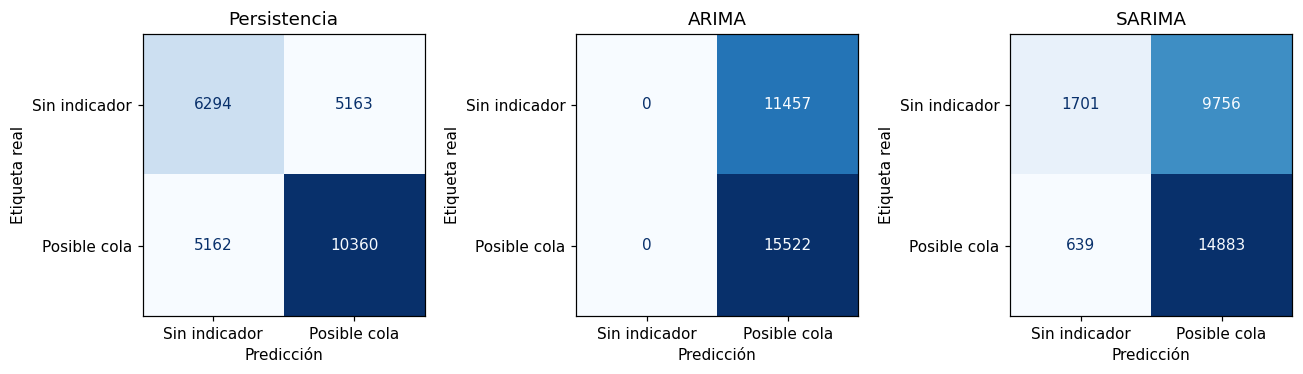

In [ ]:
def arima_graficar_matrices_confusion(estado):
    evaluacion_test = estado["evaluacion_test"]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
    for ax, nombre in zip(axes, ["Persistencia", "ARIMA", "SARIMA"]):
        grupo = evaluacion_test.loc[evaluacion_test["Modelo"].eq(nombre)]
        matriz = confusion_matrix(grupo["Cola_real"], grupo["Cola_predicha"], labels=[0, 1])
        ConfusionMatrixDisplay(matriz, display_labels=["Sin indicador", "Posible cola"]).plot(
            ax=ax, colorbar=False, cmap="Blues", values_format="d"
        )
        ax.set_title(nombre)
        ax.set_xlabel("Predicción")
        ax.set_ylabel("Etiqueta real")
    plt.tight_layout()
    return fig


fig = arima_graficar_matrices_confusion(arima)
plt.show()
plt.close(fig)

SARIMA omite 639 positivos, pero genera 9,756 falsas alarmas; persistencia tiene menos falsas alarmas y más omisiones. La utilidad depende del costo de ambos errores.

### 2.8 Estabilidad mensual, errores continuos y residuos

Calcula métricas mensuales y compara el error de los pronósticos antes y después de limitarlos a 0–1.

In [ ]:
def arima_evaluar_estabilidad_y_recorte(estado):
    evaluacion_test = estado["evaluacion_test"]
    pred_test = estado["pred_test"]
    resultados_mes = pd.DataFrame(
        [
            {"Modelo": modelo, "Mes": str(mes), **arima_evaluar(estado, grupo)}
            for (modelo, mes), grupo in evaluacion_test.groupby(
                ["Modelo", evaluacion_test["bloque_tiempo"].dt.to_period("M")]
            )
        ]
    )
    recorte = pd.DataFrame(
        [
            {
                "Modelo": modelo,
                "Fraccion_fuera_0_1": (~grupo["Prediccion_sin_limitar"].between(0, 1)).mean(),
                "MAE_sin_limitar": mean_absolute_error(
                    grupo["Real"], grupo["Prediccion_sin_limitar"]
                ),
                "MAE_limitado": mean_absolute_error(grupo["Real"], grupo["Prediccion"]),
            }
            for modelo, grupo in pred_test.groupby("Modelo")
        ]
    )
    return {"resultados_mes": resultados_mes, "recorte": recorte}


arima.update(arima_evaluar_estabilidad_y_recorte(arima))

Muestra cómo cambian F1, prevalencia y errores continuos entre los meses de prueba.

In [ ]:
display(arima["resultados_mes"][["Modelo", "Mes", "N", "Prevalencia", "F1", "MAE", "RMSE"]])

,Modelo,Mes,N,Prevalencia,F1,MAE,RMSE
0,ARIMA,2025-06,483,0.4617,0.6317,0.3223,0.3776
1,ARIMA,2025-07,4464,0.4917,0.6593,0.3313,0.3834
2,ARIMA,2025-08,4464,0.5334,0.6957,0.3292,0.3819
3,ARIMA,2025-09,4320,0.5581,0.7164,0.3138,0.3702
4,ARIMA,2025-10,4464,0.5603,0.7182,0.3201,0.3751
5,ARIMA,2025-11,4320,0.6444,0.7838,0.3069,0.3639
6,ARIMA,2025-12,4464,0.6781,0.8082,0.3051,0.3636
7,Mismo bloque ayer,2025-06,483,0.4617,0.5091,0.3672,0.4939
8,Mismo bloque ayer,2025-07,4464,0.4917,0.5555,0.3614,0.4895
9,Mismo bloque ayer,2025-08,4464,0.5334,0.6029,0.354,0.4847


El F1 aumenta junto con la prevalencia positiva y siempre cola también mejora. Por ello, el aumento mensual no se atribuye automáticamente a mejores patrones aprendidos.

Muestra cuántos pronósticos quedaron fuera de 0–1 y cuánto cambió el MAE al limitarlos.

In [ ]:
display(arima["recorte"])

,Modelo,Fraccion_fuera_0_1,MAE_sin_limitar,MAE_limitado
0,ARIMA,0,0.3179,0.3179
1,SARIMA,0,0.3728,0.3728


Ningún pronóstico de esta prueba quedó fuera de 0–1 y el MAE no cambió. Limitar el rango no explica la diferencia entre ARIMA y SARIMA.

Selecciona F1, MAE y RMSE de ambas familias para comparar objetivos de clasificación y pronóstico continuo.

In [ ]:
def arima_comparar_errores_continuos(estado):
    resultados_globales = estado["resultados_globales"]
    comparacion_familias = resultados_globales.set_index("Modelo").loc[
        ["ARIMA", "SARIMA"], ["F1", "MAE", "RMSE"]
    ]
    return {"comparacion_familias": comparacion_familias}


arima.update(arima_comparar_errores_continuos(arima))

Muestra los errores continuos y F1 globales de ARIMA y SARIMA.

In [ ]:
display(arima["comparacion_familias"])

,F1,MAE,RMSE
Modelo,,,
ARIMA,0.7304,0.3179,0.3733
SARIMA,0.7412,0.3728,0.4283


ARIMA tiene menor MAE y RMSE; SARIMA mejora F1, pero su R² negativo indica más error cuadrático que la referencia descriptiva de la media de prueba. La elección depende del objetivo.

Calcula la diferencia SARIMA menos ARIMA para cuantificar el intercambio entre métricas.

In [ ]:
display(
    pd.DataFrame(
        {
            "Cambio_SARIMA_menos_ARIMA": arima["comparacion_familias"].loc["SARIMA"]
            - arima["comparacion_familias"].loc["ARIMA"]
        }
    )
)

,Cambio_SARIMA_menos_ARIMA
F1,0.01074
MAE,0.05496
RMSE,0.05508


SARIMA gana 0.01074 de F1, pero aumenta el MAE y RMSE en aproximadamente 0.055. La mejora clasificatoria tiene un costo claro en precisión continua.

Aplica Ljung–Box a los residuos anteriores a prueba para detectar dependencia temporal no capturada.

In [ ]:
def arima_diagnosticar_residuos(estado):
    ESTACIONALIDAD = estado["ESTACIONALIDAD"]
    modelos_finales = estado["modelos_finales"]
    residuos_modelos = []
    for (familia, robot), paquete in modelos_finales.items():
        configuracion = paquete["configuracion"]
        resultado = paquete["resultado"]
        inicio = max(2 * ESTACIONALIDAD, resultado.loglikelihood_burn)
        residuos = np.asarray(resultado.resid)[inicio:]
        grados = sum(configuracion["Orden"][::2]) + sum(configuracion["Estacional"][::2])
        pruebas = acorr_ljungbox(residuos, lags=[48, 96], model_df=grados, return_df=True)
        residuos_modelos.append(
            {
                "Modelo": familia,
                "Robot": robot,
                "N_residuos": len(residuos),
                "Ljung_Box_p_48": pruebas.loc[48, "lb_pvalue"],
                "Ljung_Box_p_96": pruebas.loc[96, "lb_pvalue"],
            }
        )
    return {"residuos_modelos": residuos_modelos}


arima.update(arima_diagnosticar_residuos(arima))

Muestra los valores p de Ljung–Box a 48 y 96 bloques para los seis modelos.

In [ ]:
display(pd.DataFrame(arima["residuos_modelos"]))

,Modelo,Robot,N_residuos,Ljung_Box_p_48,Ljung_Box_p_96
0,ARIMA,VMS 1,50861,0,0
1,SARIMA,VMS 1,50861,0,0
2,ARIMA,VMS 2,50859,0,0
3,SARIMA,VMS 2,50859,0,0
4,ARIMA,VMS 3,50863,0,0
5,SARIMA,VMS 3,50863,0,0


Los valores p mostrados como cero son numéricamente muy pequeños y señalan dependencia residual. La estacionalidad diaria no captura toda la estructura temporal del indicador.

Superpone observaciones y predicciones a un paso durante siete días de prueba, separadas por robot.

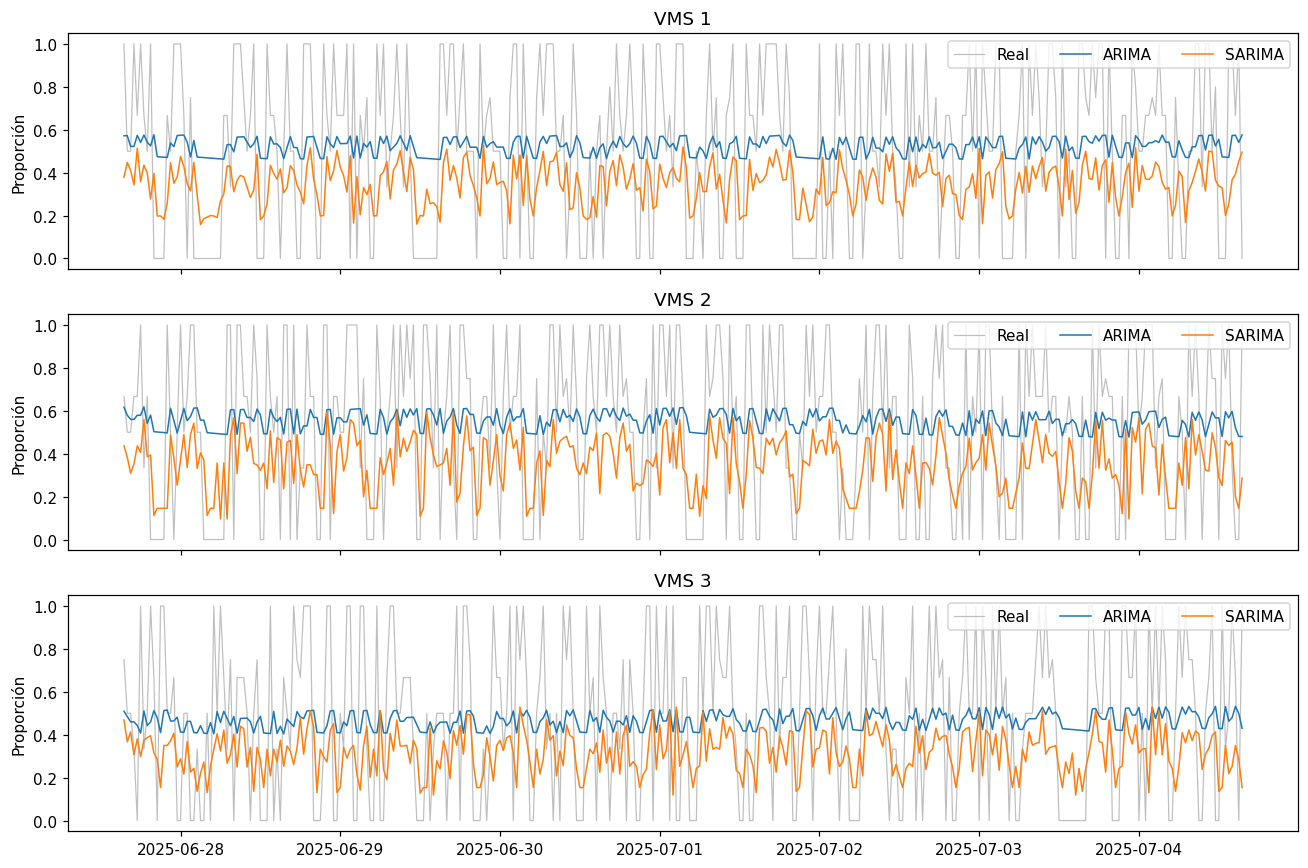

In [ ]:
def arima_graficar_pronostico_siete_dias(estado):
    INICIO_TEST = estado["INICIO_TEST"]
    pred_test = estado["pred_test"]
    robots = estado["robots"]
    series = estado["series"]
    fig, axes = plt.subplots(len(robots), 1, figsize=(12, 8), sharex=True)
    fin_grafica = INICIO_TEST + pd.Timedelta(days=7)
    for ax, robot in zip(axes, robots):
        real = series[robot].loc[INICIO_TEST:fin_grafica]
        ax.plot(real.index, real, color="0.75", linewidth=0.8, label="Real")
        for familia in ["ARIMA", "SARIMA"]:
            grupo = pred_test.loc[
                pred_test["ms"].eq(robot)
                & pred_test["Modelo"].eq(familia)
                & pred_test["bloque_tiempo"].le(fin_grafica)
            ]
            ax.plot(grupo["bloque_tiempo"], grupo["Prediccion"], linewidth=1, label=familia)
        ax.set(title=robot, ylabel="Proporción", ylim=(-0.05, 1.05))
        ax.legend(loc="upper right", ncol=3)
    plt.tight_layout()
    return fig


fig = arima_graficar_pronostico_siete_dias(arima)
plt.show()
plt.close(fig)

Ambos pronósticos suavizan los cambios bruscos; SARIMA oscila más que ARIMA. Esto ayuda a explicar sus errores y limita la interpretación de una predicción puntual.

Muestra ejemplos individuales de predicción continua y de su conversión a una etiqueta binaria.

In [ ]:
display(
    arima["pred_test"][
        ["Modelo", "ms", "bloque_tiempo", "Real", "Prediccion", "Cola_real", "Cola_predicha"]
    ]
    .groupby(["Modelo", "ms"], sort=False)
    .head(3)
)

,Modelo,ms,bloque_tiempo,Real,Prediccion,Cola_real,Cola_predicha
0,ARIMA,VMS 1,2025-06-27 15:30:00,1,0.5717,1,1
1,ARIMA,VMS 1,2025-06-27 16:00:00,0.5,0.5728,0,1
2,ARIMA,VMS 1,2025-06-27 16:30:00,0.5,0.5222,0,1
8993,SARIMA,VMS 1,2025-06-27 15:30:00,1,0.3789,1,1
8994,SARIMA,VMS 1,2025-06-27 16:00:00,0.5,0.448,0,1
8995,SARIMA,VMS 1,2025-06-27 16:30:00,0.5,0.4108,0,1
17986,ARIMA,VMS 2,2025-06-27 15:30:00,0.6667,0.6168,1,1
17987,ARIMA,VMS 2,2025-06-27 16:00:00,0.5,0.5791,0,1
17988,ARIMA,VMS 2,2025-06-27 16:30:00,0.5,0.56,0,1
26979,SARIMA,VMS 2,2025-06-27 15:30:00,0.6667,0.437,1,1


La etiqueta depende del umbral predictivo de cada robot, no de aplicar 0.5 al pronóstico. Se distinguen ambos umbrales para evitar confundir estimación y verdad observada.

### 2.9 Pronósticos futuros

Pronosticamos cuatro bloques desde el final del archivo.
Este horizonte de varios pasos es distinto de la prueba a un paso actualizada con observaciones.

Define el pronóstico de varios pasos desde un estado conocido, usando el escalador y umbral de cada robot.

In [ ]:
def arima_predecir_futuro(estado, paquetes, escaladores_guardados, familia, robot, pasos=4):
    if not isinstance(pasos, int) or not 1 <= pasos <= 48:
        raise ValueError("Usa entre 1 y 48 bloques futuros.")
    paquete = paquetes[familia, robot]
    pronostico = paquete["resultado"].forecast(steps=pasos)
    crudas = (
        escaladores_guardados[robot].inverse_transform(pronostico.to_numpy().reshape(-1, 1)).ravel()
    )
    estimaciones = np.clip(crudas, 0, 1)
    return pd.DataFrame(
        {
            "Modelo": familia,
            "ms": robot,
            "bloque_tiempo": pronostico.index,
            "Horizonte_min": 30 * np.arange(1, pasos + 1),
            "Prediccion": estimaciones,
            "Umbral": paquete["umbral"],
            "Posible_cola": (estimaciones >= paquete["umbral"]).astype(int),
        }
    )

Pronostica cuatro bloques desde el final del archivo con los estados actualizados hasta la última observación.

In [ ]:
def arima_pronosticar_futuro(estado):
    PASOS_FUTUROS = estado["PASOS_FUTUROS"]
    escaladores = estado["escaladores"]
    estados_actualizados = estado["estados_actualizados"]
    robots = estado["robots"]
    predicciones_futuras = pd.concat(
        [
            arima_predecir_futuro(
                estado, estados_actualizados, escaladores, familia, robot, PASOS_FUTUROS
            )
            for familia in ["ARIMA", "SARIMA"]
            for robot in robots
        ],
        ignore_index=True,
    )
    return {"predicciones_futuras": predicciones_futuras}


arima.update(arima_pronosticar_futuro(arima))

Muestra las predicciones de los próximos 30, 60, 90 y 120 minutos respecto al final del dataset.

In [ ]:
display(arima["predicciones_futuras"])

,Modelo,ms,bloque_tiempo,Horizonte_min,Prediccion,Umbral,Posible_cola
0,ARIMA,VMS 1,2026-01-01 00:00:00,30,0.7237,0.35,1
1,ARIMA,VMS 1,2026-01-01 00:30:00,60,0.7295,0.35,1
2,ARIMA,VMS 1,2026-01-01 01:00:00,90,0.7301,0.35,1
3,ARIMA,VMS 1,2026-01-01 01:30:00,120,0.7301,0.35,1
4,ARIMA,VMS 2,2026-01-01 00:00:00,30,0.6884,0.38,1
5,ARIMA,VMS 2,2026-01-01 00:30:00,60,0.653,0.38,1
6,ARIMA,VMS 2,2026-01-01 01:00:00,90,0.649,0.38,1
7,ARIMA,VMS 2,2026-01-01 01:30:00,120,0.6486,0.38,1
8,ARIMA,VMS 3,2026-01-01 00:00:00,30,0.5456,0.37,1
9,ARIMA,VMS 3,2026-01-01 00:30:00,60,0.6009,0.37,1


Los cuatro bloques pronosticados quedan etiquetados como positivos. Son ejemplos desde el final del archivo sin observaciones futuras para comprobar su exactitud.

### 2.10 Conclusión

ARIMA obtiene F1 = 0.7304 y SARIMA = 0.7412; siempre cola también alcanza 0.7304.
El MAE es 0.3179 para ARIMA y 0.3728 para SARIMA. La ventaja clasificatoria de SARIMA es pequeña.

## 3. Patrones temporales y errores de los modelos

Evaluamos las 48 franjas de cada robot, su recurrencia mensual y los errores de las predicciones de la sección anterior.
Las franjas se seleccionan en entrenamiento y se contrastan en validación; prueba se usa para diagnosticar errores.

### 3.1 Configuración e integración con ARIMA/SARIMA

Fija los mínimos de soporte y recurrencia para estudiar las 48 franjas de cada robot.

In [ ]:
temporal = iniciar_analisis(base, calendario)
temporal.update(
    {
        "MIN_BLOQUES_CELDA": 30,
        "MIN_BLOQUES_MES": 20,
        "MIN_MESES_TRAIN": 6,
        "MIN_PROP_MESES_TRAIN": 0.5,
        "MIN_PROP_MESES_VAL": 2 / 3,
        "MIN_MESES_VAL": 3,
        "DIAS": ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"],
        "MODELOS": ["ARIMA", "SARIMA", "Persistencia", "Mismo bloque ayer", "Siempre cola"],
    }
)

Conecta los patrones temporales con las predicciones ya calculadas y conserva los mismos cortes cronológicos.

In [ ]:
def temporal_integrar_predicciones(estado, modelos):
    estado["predicciones"] = modelos["evaluacion_test"].copy()
    estado["metricas_originales"] = modelos["resultados_globales"].copy()
    estado["seleccion"] = modelos["seleccion"].copy()
    estado["configuracion"] = {
        "umbral_real": UMBRAL_REAL,
        "inicio_validacion": str(calendario["INICIO_VAL"]),
        "inicio_prueba": str(calendario["INICIO_TEST"]),
    }
    datos = estado["datos"]
    estado["train"] = datos.loc[datos["Conjunto"].eq("Entrenamiento")].copy()
    estado["val"] = datos.loc[datos["Conjunto"].eq("Validación")].copy()
    estado["test"] = datos.loc[datos["Conjunto"].eq("Prueba")].copy()
    estado["particiones"] = calendario["resumen_particiones"].rename(
        columns={"Registros": "Bloques"}
    )


temporal_integrar_predicciones(temporal, arima)

### 3.2 Frecuencia por día, horario y robot

Cada porcentaje utiliza bloques como denominador. Mostramos ejemplos de los grupos con mayor frecuencia;
la evaluación posterior revisa todas las franjas, sin limitarse a los cinco ejemplos.

Define la frecuencia de posible cola como porcentaje de bloques positivos dentro de cada grupo.

In [ ]:
def temporal_resumir_frecuencia(estado, tabla, grupos):
    resumen = (
        tabla.groupby(grupos, observed=True)
        .agg(Bloques=("cola", "size"), Bloques_cola=("cola", "sum"))
        .reset_index()
    )
    resumen["Frecuencia_cola_pct"] = 100 * resumen["Bloques_cola"] / resumen["Bloques"]
    return resumen

Calcula frecuencias por robot, día de la semana y franja usando solo entrenamiento.

In [ ]:
def temporal_calcular_frecuencias(estado):
    DIAS = estado["DIAS"]
    MIN_BLOQUES_CELDA = estado["MIN_BLOQUES_CELDA"]
    horarios = estado["horarios"]
    train = estado["train"]
    frecuencia_horarios = temporal_resumir_frecuencia(estado, train, ["ms", "dia_semana", "franja"])
    frecuencia_horarios["Dia"] = frecuencia_horarios["dia_semana"].map(dict(enumerate(DIAS)))
    frecuencia_horarios["Horario"] = frecuencia_horarios["franja"].map(horarios)
    frecuencia_horarios["Soporte_suficiente"] = frecuencia_horarios["Bloques"].ge(MIN_BLOQUES_CELDA)
    return {"frecuencia_horarios": frecuencia_horarios}


temporal.update(temporal_calcular_frecuencias(temporal))

Muestra una muestra de las frecuencias y conteos para comprobar la unidad de análisis.

In [ ]:
display(
    temporal["frecuencia_horarios"][
        ["ms", "Dia", "Horario", "Bloques", "Bloques_cola", "Frecuencia_cola_pct"]
    ].head(12)
)

,ms,Dia,Horario,Bloques,Bloques_cola,Frecuencia_cola_pct
0,VMS 1,Lun,00:00,124,28,22.58
1,VMS 1,Lun,00:30,124,29,23.39
2,VMS 1,Lun,01:00,125,29,23.2
3,VMS 1,Lun,01:30,125,20,16
4,VMS 1,Lun,02:00,125,27,21.6
5,VMS 1,Lun,02:30,125,16,12.8
6,VMS 1,Lun,03:00,125,21,16.8
7,VMS 1,Lun,03:30,125,19,15.2
8,VMS 1,Lun,04:00,125,12,9.6
9,VMS 1,Lun,04:30,125,13,10.4


Cada porcentaje conserva su número de bloques y positivos. Se usa esa frecuencia, no el conteo bruto, para comparar grupos de tamaño diferente.

Identifica los cinco grupos de día y horario con mayor frecuencia por robot y soporte suficiente.

In [ ]:
def temporal_resumir_horarios_destacados(estado):
    frecuencia_horarios = estado["frecuencia_horarios"]
    horarios_mayor_frecuencia = (
        frecuencia_horarios.loc[frecuencia_horarios["Soporte_suficiente"]]
        .sort_values(
            ["ms", "Frecuencia_cola_pct", "Bloques", "dia_semana", "franja"],
            ascending=[True, False, False, True, True],
        )
        .groupby("ms", sort=False)
        .head(5)
    )
    return {"horarios_mayor_frecuencia": horarios_mayor_frecuencia}


temporal.update(temporal_resumir_horarios_destacados(temporal))

Muestra ejemplos de horarios destacados antes de revisar todas las franjas por recurrencia mensual.

In [ ]:
display(
    temporal["horarios_mayor_frecuencia"][
        ["ms", "Dia", "Horario", "Bloques", "Bloques_cola", "Frecuencia_cola_pct"]
    ]
)

,ms,Dia,Horario,Bloques,Bloques_cola,Frecuencia_cola_pct
226,VMS 1,Vie,17:00,125,40,32
112,VMS 1,Mié,08:00,125,39,31.2
128,VMS 1,Mié,16:00,125,39,31.2
66,VMS 1,Mar,09:00,125,38,30.4
306,VMS 1,Dom,09:00,124,37,29.84
531,VMS 2,Vie,01:30,125,29,23.2
548,VMS 2,Vie,10:00,125,29,23.2
625,VMS 2,Dom,00:30,125,29,23.2
481,VMS 2,Jue,00:30,125,28,22.4
402,VMS 2,Mar,09:00,125,27,21.6


VMS 1 destaca el viernes a las 17:00 con 32%, pero los ejemplos cambian por robot. Se revisan todos los horarios mensualmente antes de declarar recurrencia.

Resume la frecuencia horaria de entrenamiento sin separar días de la semana.

In [ ]:
def temporal_preparar_perfil_horario(estado):
    train = estado["train"]
    perfil_train = temporal_resumir_frecuencia(estado, train, ["ms", "franja"])
    return {"perfil_train": perfil_train}


temporal.update(temporal_preparar_perfil_horario(temporal))

Grafica el perfil diario de frecuencia para comparar horarios y niveles entre robots.

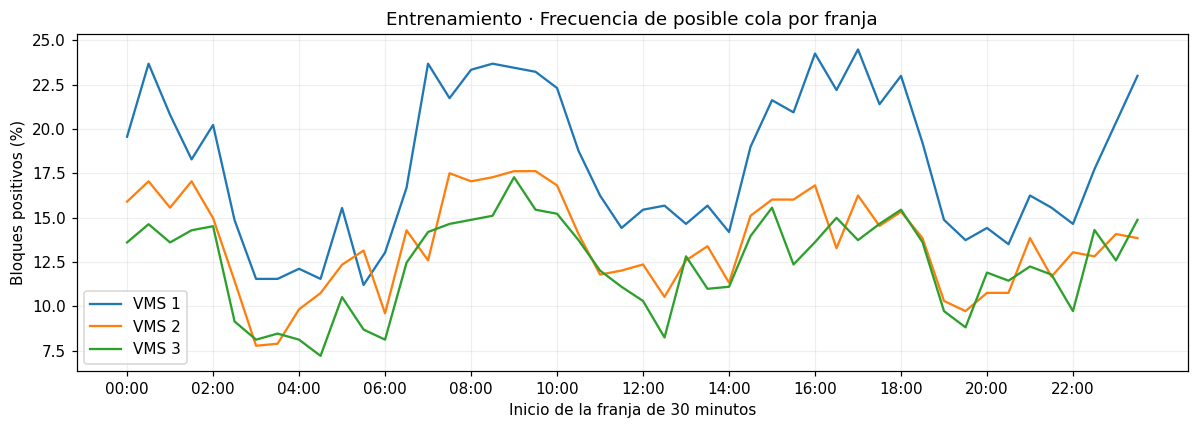

In [ ]:
def temporal_graficar_perfil_horario(estado):
    horarios = estado["horarios"]
    perfil_train = estado["perfil_train"]
    robots = estado["robots"]
    fig, ax = plt.subplots(figsize=(11, 4))
    for robot in robots:
        grupo = perfil_train.loc[perfil_train["ms"].eq(robot)].sort_values("franja")
        ax.plot(grupo["franja"], grupo["Frecuencia_cola_pct"], label=robot)
    ax.set_xticks(range(0, 48, 4), [horarios[f] for f in range(0, 48, 4)])
    ax.set(
        title="Entrenamiento · Frecuencia de posible cola por franja",
        xlabel="Inicio de la franja de 30 minutos",
        ylabel="Bloques positivos (%)",
    )
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    return fig


fig = temporal_graficar_perfil_horario(temporal)
plt.show()
plt.close(fig)

La frecuencia aumenta en franjas matutinas, vespertinas y algunas nocturnas, con niveles distintos por robot. Se buscan patrones específicos de máquina, no un único horario general.

### 3.3 Mapas de calor y soporte

Los tres robots comparten la misma escala. Las celdas con soporte insuficiente se muestran en gris.
Los colores describen diferencias; por sí solos no prueban significancia estadística.

Calcula el soporte de las combinaciones de día y franja para interpretar los mapas de calor.

In [ ]:
def temporal_preparar_mapas_dia_horario(estado):
    frecuencia_horarios = estado["frecuencia_horarios"]
    soporte_mapas = frecuencia_horarios.groupby("ms").agg(
        Celdas=("Bloques", "size"),
        Min_bloques=("Bloques", "min"),
        Max_bloques=("Bloques", "max"),
        Celdas_con_soporte=("Soporte_suficiente", "sum"),
    )
    return {"soporte_mapas": soporte_mapas}


temporal.update(temporal_preparar_mapas_dia_horario(temporal))

Grafica las frecuencias por día y horario con la misma escala de color para los tres robots.

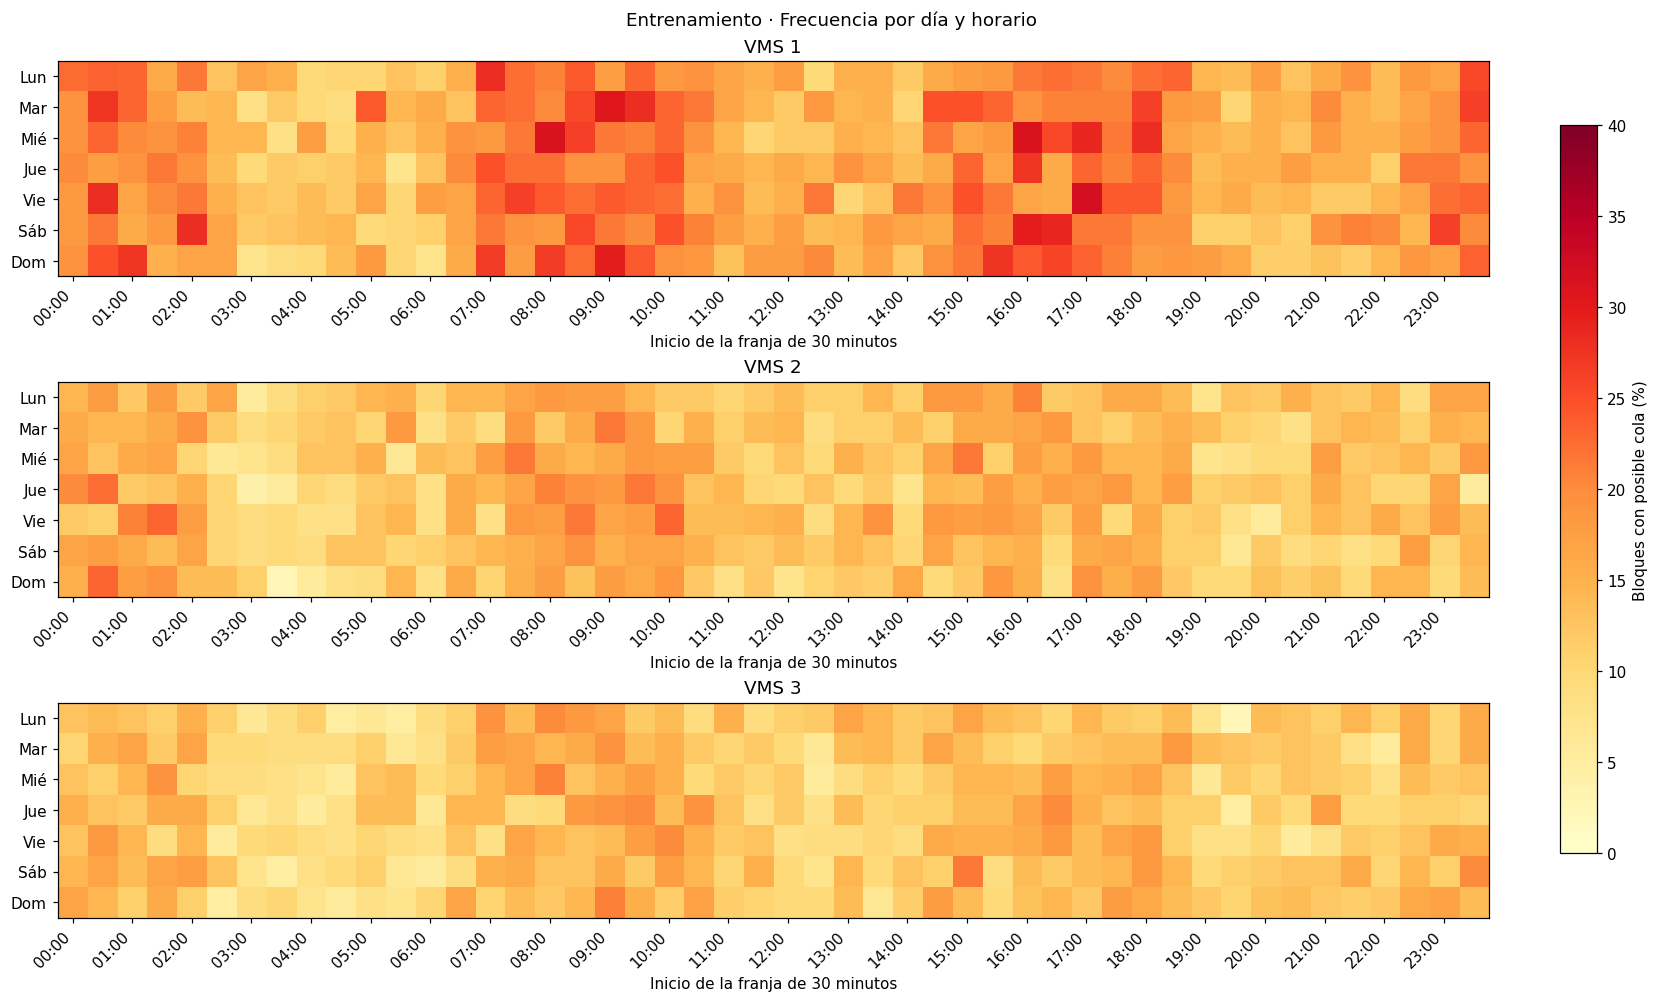

In [ ]:
def temporal_graficar_mapas_dia_horario(estado):
    DIAS = estado["DIAS"]
    frecuencia_horarios = estado["frecuencia_horarios"]
    horarios = estado["horarios"]
    robots = estado["robots"]
    maximo = frecuencia_horarios.loc[
        frecuencia_horarios["Soporte_suficiente"], "Frecuencia_cola_pct"
    ].max()
    vmax = max(10, 10 * np.ceil(maximo / 10)) if np.isfinite(maximo) else 100
    paleta = plt.colormaps["YlOrRd"].copy()
    paleta.set_bad("#dddddd")
    fig, axes = plt.subplots(len(robots), 1, figsize=(15, 9), constrained_layout=True)
    for ax, robot in zip(np.atleast_1d(axes), robots):
        grupo = frecuencia_horarios.loc[frecuencia_horarios["ms"].eq(robot)].copy()
        grupo.loc[~grupo["Soporte_suficiente"], "Frecuencia_cola_pct"] = np.nan
        matriz = grupo.pivot(
            index="dia_semana", columns="franja", values="Frecuencia_cola_pct"
        ).reindex(index=range(7), columns=range(48))
        imagen = ax.imshow(matriz, aspect="auto", cmap=paleta, vmin=0, vmax=vmax)
        ax.set_yticks(range(7), DIAS)
        ax.set_xticks(
            range(0, 48, 2), [horarios[f] for f in range(0, 48, 2)], rotation=45, ha="right"
        )
        ax.set_title(robot)
        ax.set_xlabel("Inicio de la franja de 30 minutos")
    fig.colorbar(
        imagen, ax=np.atleast_1d(axes).tolist(), label="Bloques con posible cola (%)", shrink=0.85
    )
    fig.suptitle("Entrenamiento · Frecuencia por día y horario")
    return fig


fig = temporal_graficar_mapas_dia_horario(temporal)
plt.show()
plt.close(fig)

Los colores muestran diferencias entre días y horarios, pero no prueban repetición mensual. Se utilizan para explorar candidatos y después contrastarlos con soporte y recurrencia.

Muestra cuántas celdas de cada robot cumplen el mínimo de bloques requerido.

In [ ]:
display(temporal["soporte_mapas"].reset_index())

,ms,Celdas,Min_bloques,Max_bloques,Celdas_con_soporte
0,VMS 1,336,124,125,336
1,VMS 2,336,124,125,336
2,VMS 3,336,124,125,336


Las 336 celdas de cada robot tienen entre 124 y 125 bloques y cumplen el soporte. La comparación por día y horario no se sostiene aquí en grupos pequeños.

### 3.4 Recurrencia mensual en las 144 combinaciones

Exigimos al menos 20 bloques por mes y franja. Una candidata supera la base mensual en más de la mitad de al menos seis meses de entrenamiento.
En validación debe superar la base en al menos dos tercios de los meses elegibles, con razón mediana mayor a 1.

Define la comparación de cada franja contra la base del mismo robot y mes.

In [ ]:
def temporal_frecuencia_mensual(estado, tabla):
    MIN_BLOQUES_MES = estado["MIN_BLOQUES_MES"]
    franjas = temporal_resumir_frecuencia(estado, tabla, ["ms", "mes", "franja"])
    referencia = temporal_resumir_frecuencia(estado, tabla, ["ms", "mes"])[
        ["ms", "mes", "Frecuencia_cola_pct"]
    ]
    referencia = referencia.rename(columns={"Frecuencia_cola_pct": "Base_mes_pct"})
    franjas = franjas.merge(referencia, on=["ms", "mes"], validate="many_to_one")
    franjas["Lift_mensual"] = franjas["Frecuencia_cola_pct"].div(
        franjas["Base_mes_pct"].replace(0, np.nan)
    )
    franjas["Exceso_pp"] = franjas["Frecuencia_cola_pct"] - franjas["Base_mes_pct"]
    franjas["Mes_evaluable"] = franjas["Bloques"].ge(MIN_BLOQUES_MES) & franjas["Base_mes_pct"].gt(
        0
    )
    return franjas

Calcula las frecuencias mensuales en entrenamiento y validación para revisar repetición.

In [ ]:
def temporal_calcular_frecuencias_mensuales(estado):
    train = estado["train"]
    val = estado["val"]
    mensual_train = temporal_frecuencia_mensual(estado, train)
    mensual_val = temporal_frecuencia_mensual(estado, val)
    return {"mensual_train": mensual_train, "mensual_val": mensual_val}


temporal.update(temporal_calcular_frecuencias_mensuales(temporal))

Muestra ejemplos de frecuencia, referencia mensual y soporte utilizado para evaluar cada franja.

In [ ]:
display(temporal["mensual_train"].head(8))

,ms,mes,franja,Bloques,Bloques_cola,Frecuencia_cola_pct,Base_mes_pct,Lift_mensual,Exceso_pp,Mes_evaluable
0,VMS 1,2022-08,0,30,0,0,4.845,0,-4.845,True
1,VMS 1,2022-08,1,30,1,3.333,4.845,0.688,-1.512,True
2,VMS 1,2022-08,2,31,3,9.677,4.845,1.997,4.832,True
3,VMS 1,2022-08,3,31,2,6.452,4.845,1.332,1.606,True
4,VMS 1,2022-08,4,31,3,9.677,4.845,1.997,4.832,True
5,VMS 1,2022-08,5,31,4,12.9,4.845,2.663,8.058,True
6,VMS 1,2022-08,6,31,1,3.226,4.845,0.6658,-1.619,True
7,VMS 1,2022-08,7,31,0,0,4.845,0,-4.845,True


La referencia cambia por robot y mes, en lugar de usar una sola tasa histórica. Así se reduce la confusión entre una franja alta y un aumento general del indicador.

Define cómo resumir meses evaluables, meses sobre la base y magnitud mediana de elevación.

In [ ]:
def temporal_resumir_estabilidad(estado, mensual):
    validos = mensual.loc[mensual["Mes_evaluable"]].copy()
    validos["Sobre_base"] = validos["Exceso_pp"].gt(0)
    resumen = (
        validos.groupby(["ms", "franja"])
        .agg(
            Meses_evaluables=("mes", "nunique"),
            Meses_sobre_base=("Sobre_base", "sum"),
            Lift_mediano=("Lift_mensual", "median"),
            Exceso_mediano_pp=("Exceso_pp", "median"),
            Bloques=("Bloques", "sum"),
            Bloques_cola=("Bloques_cola", "sum"),
        )
        .reset_index()
    )
    resumen["Meses_sobre_base_pct"] = (
        100 * resumen["Meses_sobre_base"] / resumen["Meses_evaluables"]
    )
    resumen["Frecuencia_cola_pct"] = 100 * resumen["Bloques_cola"] / resumen["Bloques"]
    return resumen

Evalúa las 144 combinaciones y marca candidatas usando únicamente los meses de entrenamiento.

In [ ]:
def temporal_seleccionar_candidatas(estado):
    MIN_MESES_TRAIN = estado["MIN_MESES_TRAIN"]
    MIN_PROP_MESES_TRAIN = estado["MIN_PROP_MESES_TRAIN"]
    horarios = estado["horarios"]
    mensual_train = estado["mensual_train"]
    robots = estado["robots"]
    claves_franjas = pd.MultiIndex.from_product(
        [robots, range(48)], names=["ms", "franja"]
    ).to_frame(index=False)
    estabilidad_train = claves_franjas.merge(
        temporal_resumir_estabilidad(estado, mensual_train),
        on=["ms", "franja"],
        how="left",
        validate="one_to_one",
    )
    estabilidad_train["Candidata_train"] = (
        estabilidad_train["Meses_evaluables"].ge(MIN_MESES_TRAIN)
        & estabilidad_train["Meses_sobre_base_pct"].gt(100 * MIN_PROP_MESES_TRAIN)
        & estabilidad_train["Lift_mediano"].gt(1)
    )
    candidatos = (
        estabilidad_train.loc[estabilidad_train["Candidata_train"]]
        .sort_values(
            ["ms", "Meses_sobre_base_pct", "Lift_mediano", "franja"],
            ascending=[True, False, False, True],
        )
        .copy()
    )
    candidatos["Horario"] = candidatos["franja"].map(horarios)
    return {"estabilidad_train": estabilidad_train, "candidatos": candidatos}


temporal.update(temporal_seleccionar_candidatas(temporal))

Muestra todas las candidatas de entrenamiento con su recurrencia y elevación relativa.

In [ ]:
display(
    temporal["candidatos"][
        [
            "ms",
            "Horario",
            "Meses_evaluables",
            "Meses_sobre_base",
            "Meses_sobre_base_pct",
            "Lift_mediano",
        ]
    ]
)

,ms,Horario,Meses_evaluables,Meses_sobre_base,Meses_sobre_base_pct,Lift_mediano
34,VMS 1,17:00,29,25,86.21,1.297
18,VMS 1,09:00,29,25,86.21,1.288
1,VMS 1,00:30,29,24,82.76,1.297
32,VMS 1,16:00,29,22,75.86,1.348
17,VMS 1,08:30,29,22,75.86,1.241
15,VMS 1,07:30,29,21,72.41,1.241
47,VMS 1,23:30,29,21,72.41,1.231
14,VMS 1,07:00,29,21,72.41,1.213
2,VMS 1,01:00,29,21,72.41,1.171
16,VMS 1,08:00,29,20,68.97,1.253


Sesenta y cuatro franjas cumplen el criterio en entrenamiento. Se conserva esa selección antes de revisar validación para distinguir recurrencia previa de elevaciones recientes.

Define una vista compacta de meses sobre la base, magnitud y tipo de repetición de cada franja.

In [ ]:
def temporal_vista_reporte(estado, tabla):
    vista = tabla[["ms", "Horario", "Repeticion"]].copy()
    for conjunto in ["train", "val"]:
        vista[f"Meses_sobre_base_{conjunto}"] = (
            tabla[f"Meses_sobre_base_{conjunto}"].astype("Int64").astype(str)
            + "/"
            + tabla[f"Meses_evaluables_{conjunto}"].astype("Int64").astype(str)
        )
    vista["Lift_mediano_val"] = tabla["Lift_mediano_val"]
    vista["Exceso_val_pp"] = tabla["Exceso_mediano_pp_val"]
    return vista.round(2)

Contrasta todas las franjas con validación y separa las recurrentes de las elevaciones recientes.

In [ ]:
def temporal_contrastar_todas_las_franjas(estado):
    MIN_MESES_TRAIN = estado["MIN_MESES_TRAIN"]
    MIN_MESES_VAL = estado["MIN_MESES_VAL"]
    MIN_PROP_MESES_VAL = estado["MIN_PROP_MESES_VAL"]
    estabilidad_train = estado["estabilidad_train"]
    horarios = estado["horarios"]
    mensual_val = estado["mensual_val"]
    robots = estado["robots"]
    estabilidad_val = temporal_resumir_estabilidad(estado, mensual_val)
    columnas_comparacion = [
        "ms",
        "franja",
        "Meses_evaluables",
        "Meses_sobre_base",
        "Meses_sobre_base_pct",
        "Lift_mediano",
        "Exceso_mediano_pp",
    ]
    contraste = estabilidad_train[columnas_comparacion + ["Candidata_train"]].merge(
        estabilidad_val[columnas_comparacion],
        on=["ms", "franja"],
        how="left",
        suffixes=("_train", "_val"),
        validate="one_to_one",
    )
    contraste.insert(2, "Horario", contraste["franja"].map(horarios))
    soporte_val = contraste["Meses_evaluables_val"].ge(MIN_MESES_VAL)
    proporcion_val = contraste["Meses_sobre_base_val"] / contraste["Meses_evaluables_val"]
    contraste["Elevacion_val"] = (
        soporte_val & proporcion_val.ge(MIN_PROP_MESES_VAL) & contraste["Lift_mediano_val"].gt(1)
    )
    contraste["Interesante"] = contraste["Candidata_train"] & contraste["Elevacion_val"]
    contraste["Elevacion_reciente"] = (
        ~contraste["Candidata_train"]
        & contraste["Elevacion_val"]
        & contraste["Meses_evaluables_train"].ge(MIN_MESES_TRAIN)
    )
    contraste["Repeticion"] = np.select(
        [
            contraste["Interesante"] & proporcion_val.eq(1),
            contraste["Interesante"] & proporcion_val.ge(0.8),
            contraste["Interesante"],
            contraste["Elevacion_reciente"],
            ~soporte_val | contraste["Meses_evaluables_train"].lt(MIN_MESES_TRAIN),
            contraste["Candidata_train"],
        ],
        [
            "Completa",
            "Alta",
            "Moderada",
            "Elevación reciente",
            "Soporte insuficiente",
            "No se mantiene",
        ],
        default="Sin elevación recurrente",
    )
    orden = [
        "ms",
        "Meses_sobre_base_pct_val",
        "Lift_mediano_val",
        "Meses_sobre_base_pct_train",
        "franja",
    ]
    ascendente = [True, False, False, False, True]
    franjas_interesantes = (
        contraste.loc[contraste["Interesante"]].sort_values(orden, ascending=ascendente).copy()
    )
    elevaciones_recientes = (
        contraste.loc[contraste["Elevacion_reciente"]]
        .sort_values(orden, ascending=ascendente)
        .copy()
    )
    resumen_franjas = contraste.groupby("ms").agg(
        Evaluadas=("franja", "size"),
        Candidatas_train=("Candidata_train", "sum"),
        Interesantes=("Interesante", "sum"),
        Elevaciones_recientes=("Elevacion_reciente", "sum"),
    )
    resumen_repeticion = pd.crosstab(
        franjas_interesantes["ms"], franjas_interesantes["Repeticion"]
    ).reindex(index=robots, columns=["Completa", "Alta", "Moderada"], fill_value=0)
    meses_val_elegibles = mensual_val.groupby("mes").agg(
        Celdas=("franja", "size"),
        Celdas_evaluables=("Mes_evaluable", "sum"),
        Min_bloques_franja=("Bloques", "min"),
        Max_bloques_franja=("Bloques", "max"),
    )
    return {
        "contraste": contraste,
        "franjas_interesantes": franjas_interesantes,
        "elevaciones_recientes": elevaciones_recientes,
        "resumen_franjas": resumen_franjas,
        "resumen_repeticion": resumen_repeticion,
        "meses_val_elegibles": meses_val_elegibles,
    }


temporal.update(temporal_contrastar_todas_las_franjas(temporal))

Resume por robot las combinaciones evaluadas, candidatas, recurrentes y recientes.

In [ ]:
display(temporal["resumen_franjas"].reset_index())

,ms,Evaluadas,Candidatas_train,Interesantes,Elevaciones_recientes
0,VMS 1,48,23,20,7
1,VMS 2,48,19,18,13
2,VMS 3,48,22,18,9


Se mantienen 56 franjas: 20 de VMS 1 y 18 en cada uno de los otros dos. Son hallazgos de recurrencia descriptiva, no 56 pruebas de significancia superadas.

Desglosa las franjas recurrentes según cuántos meses de validación superaron su referencia.

In [ ]:
display(temporal["resumen_repeticion"].reset_index())

Repeticion,ms,Completa,Alta,Moderada
0,VMS 1,7,10,3
1,VMS 2,8,5,5
2,VMS 3,9,5,4


Veinticuatro franjas superan su base en los seis meses evaluables; las restantes lo hacen en cuatro o cinco. El reporte distingue patrones más constantes de otros menos estables.

Muestra todas las franjas que cumplieron recurrencia en entrenamiento y validación.

In [ ]:
display(temporal_vista_reporte(temporal, temporal["franjas_interesantes"]))

,ms,Horario,Repeticion,Meses_sobre_base_train,Meses_sobre_base_val,Lift_mediano_val,Exceso_val_pp
15,VMS 1,07:30,Completa,21/29,6/6,1.39,14.45
1,VMS 1,00:30,Completa,24/29,6/6,1.36,13.45
31,VMS 1,15:30,Completa,19/29,6/6,1.29,11.93
17,VMS 1,08:30,Completa,22/29,6/6,1.27,10.65
16,VMS 1,08:00,Completa,20/29,6/6,1.26,11.54
2,VMS 1,01:00,Completa,21/29,6/6,1.26,9.32
4,VMS 1,02:00,Completa,15/29,6/6,1.25,10.26
18,VMS 1,09:00,Alta,25/29,5/6,1.26,10.8
47,VMS 1,23:30,Alta,21/29,5/6,1.18,6.52
46,VMS 1,23:00,Alta,17/29,5/6,1.17,7.41


La lista incluye todas las franjas recurrentes y su magnitud frente a la base. Permite priorizar observaciones por robot sin limitar el informe a tres horarios.

Muestra las elevaciones recientes que todavía no reúnen la misma recurrencia histórica.

In [ ]:
display(temporal_vista_reporte(temporal, temporal["elevaciones_recientes"]))

,ms,Horario,Repeticion,Meses_sobre_base_train,Meses_sobre_base_val,Lift_mediano_val,Exceso_val_pp
38,VMS 1,19:00,Elevación reciente,13/29,6/6,1.29,11.84
13,VMS 1,06:30,Elevación reciente,12/29,5/6,1.22,7.96
43,VMS 1,21:30,Elevación reciente,10/29,5/6,1.15,5.57
5,VMS 1,02:30,Elevación reciente,13/29,5/6,1.12,5.02
45,VMS 1,22:30,Elevación reciente,14/29,5/6,1.05,1.82
44,VMS 1,22:00,Elevación reciente,10/29,4/6,1.24,10.52
22,VMS 1,11:00,Elevación reciente,13/29,4/6,1.13,5.28
92,VMS 2,22:00,Elevación reciente,11/29,6/6,1.33,14.78
53,VMS 2,02:30,Elevación reciente,9/29,6/6,1.23,11.39
83,VMS 2,17:30,Elevación reciente,14/29,5/6,1.34,16.3


Hay 29 elevaciones recientes sin la misma recurrencia previa. Se reportan por separado como cambios que requieren seguimiento, no como patrones históricos ya consolidados.

Revisa cuántos meses y franjas de validación tienen soporte suficiente para comparar.

In [ ]:
display(temporal["meses_val_elegibles"].reset_index())

,mes,Celdas,Celdas_evaluables,Min_bloques_franja,Max_bloques_franja
0,2024-12,144,0,9,10
1,2025-01,144,144,31,31
2,2025-02,144,144,28,28
3,2025-03,144,144,31,31
4,2025-04,144,144,30,30
5,2025-05,144,144,31,31
6,2025-06,144,144,26,27


Diciembre de 2024 no tiene soporte suficiente; enero–junio aportan los seis meses evaluables. Se evita que un fragmento corto determine la recurrencia.

Grafica la diferencia mensual de cada franja frente a la base de su robot durante validación.

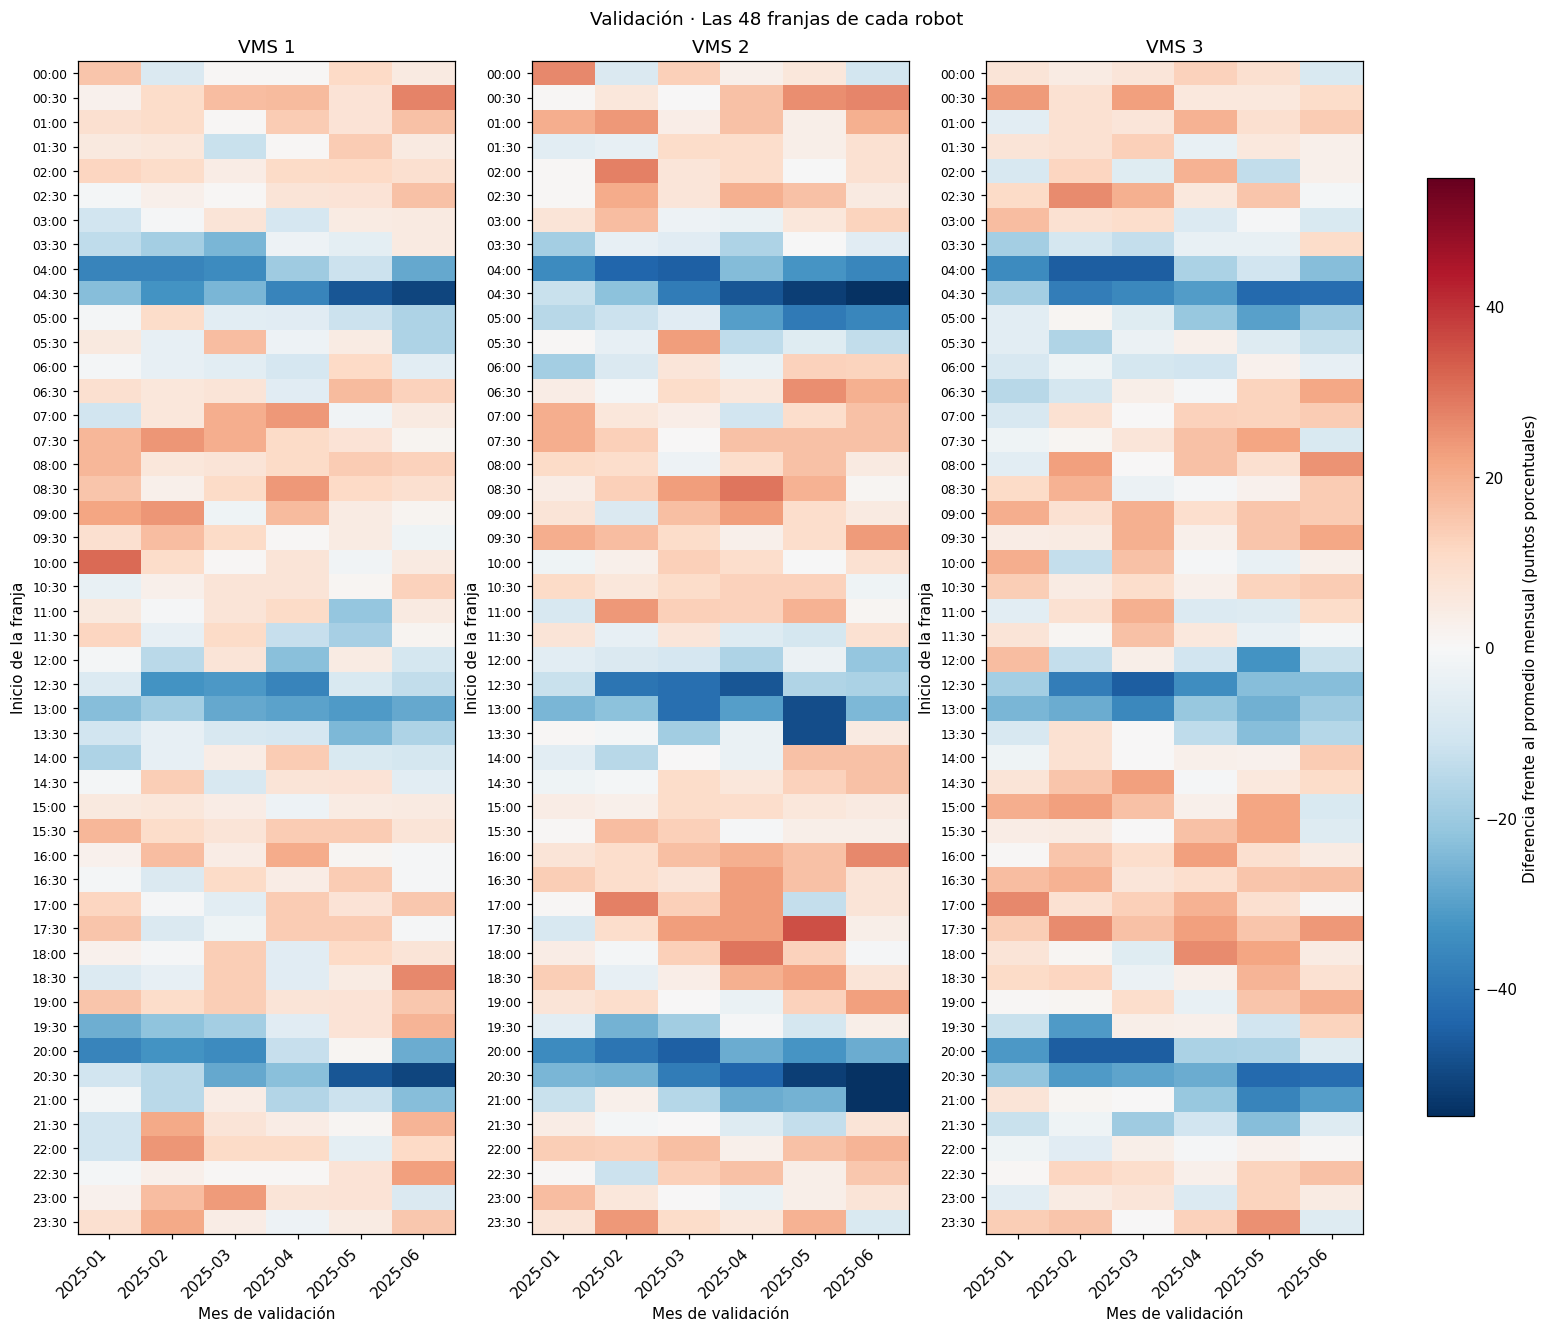

In [ ]:
def temporal_graficar_recurrencia_validacion(estado):
    horarios = estado["horarios"]
    mensual_val = estado["mensual_val"]
    robots = estado["robots"]
    meses_mapa = sorted(mensual_val.loc[mensual_val["Mes_evaluable"], "mes"].unique())
    limite = np.ceil(mensual_val.loc[mensual_val["Mes_evaluable"], "Exceso_pp"].abs().max() / 5) * 5
    limite = max(5, limite) if np.isfinite(limite) else 5
    paleta_mes = plt.colormaps["RdBu_r"].copy()
    paleta_mes.set_bad("#dddddd")
    fig, axes = plt.subplots(1, len(robots), figsize=(14, 12), constrained_layout=True)
    for ax, robot in zip(np.atleast_1d(axes), robots):
        grupo = mensual_val.loc[mensual_val["ms"].eq(robot)].copy()
        grupo.loc[~grupo["Mes_evaluable"], "Exceso_pp"] = np.nan
        matriz = grupo.pivot(index="franja", columns="mes", values="Exceso_pp").reindex(
            index=range(48), columns=meses_mapa
        )
        imagen = ax.imshow(matriz, aspect="auto", cmap=paleta_mes, vmin=-limite, vmax=limite)
        ax.set_yticks(range(48), [horarios[f] for f in range(48)], fontsize=8)
        ax.set_xticks(range(len(meses_mapa)), meses_mapa, rotation=45, ha="right")
        ax.set(title=robot, xlabel="Mes de validación", ylabel="Inicio de la franja")
    fig.colorbar(
        imagen,
        ax=np.atleast_1d(axes).tolist(),
        label="Diferencia frente al promedio mensual (puntos porcentuales)",
        shrink=0.8,
    )
    fig.suptitle("Validación · Las 48 franjas de cada robot")
    return fig


fig = temporal_graficar_recurrencia_validacion(temporal)
plt.show()
plt.close(fig)

Varias franjas permanecen sobre su base y otras cambian de signo entre meses. Esto respalda exigir repetición y evita elegir horarios por un único pico.

### 3.5 Franjas consecutivas para el reporte

Agrupamos únicamente franjas interesantes consecutivas. El inicio se incluye y el final se excluye.
Los tramos cercanos a medianoche se presentan según el calendario diario, sin afirmar una duración física de cola.

Define cómo agrupar franjas consecutivas en tramos horarios sin atribuirles duración de cola.

In [ ]:
def temporal_agrupar_tramos(estado, tabla):
    horarios = estado["horarios"]
    filas = []
    for robot, grupo in tabla.groupby("ms"):
        grupo = grupo.sort_values("franja").copy()
        grupo["Tramo"] = grupo["franja"].diff().ne(1).cumsum()
        for _, tramo in grupo.groupby("Tramo"):
            inicio = int(tramo["franja"].min())
            fin = int(tramo["franja"].max()) + 1
            filas.append(
                {
                    "ms": robot,
                    "Inicio": horarios[inicio],
                    "Fin_excluido": "24:00" if fin == 48 else horarios[fin],
                    "Franjas": len(tramo),
                    "Min_meses_sobre_base_val": int(tramo["Meses_sobre_base_val"].min()),
                    "Max_meses_sobre_base_val": int(tramo["Meses_sobre_base_val"].max()),
                }
            )
    return pd.DataFrame(
        filas,
        columns=[
            "ms",
            "Inicio",
            "Fin_excluido",
            "Franjas",
            "Min_meses_sobre_base_val",
            "Max_meses_sobre_base_val",
        ],
    )

Agrupa las franjas recurrentes de cada robot para facilitar su comunicación.

In [ ]:
def temporal_preparar_franjas_interesantes(estado):
    franjas_interesantes = estado["franjas_interesantes"]
    tramos_interesantes = temporal_agrupar_tramos(estado, franjas_interesantes)
    return {"tramos_interesantes": tramos_interesantes}


temporal.update(temporal_preparar_franjas_interesantes(temporal))

Grafica todas las franjas recurrentes, su elevación mediana y los meses sobre su referencia.

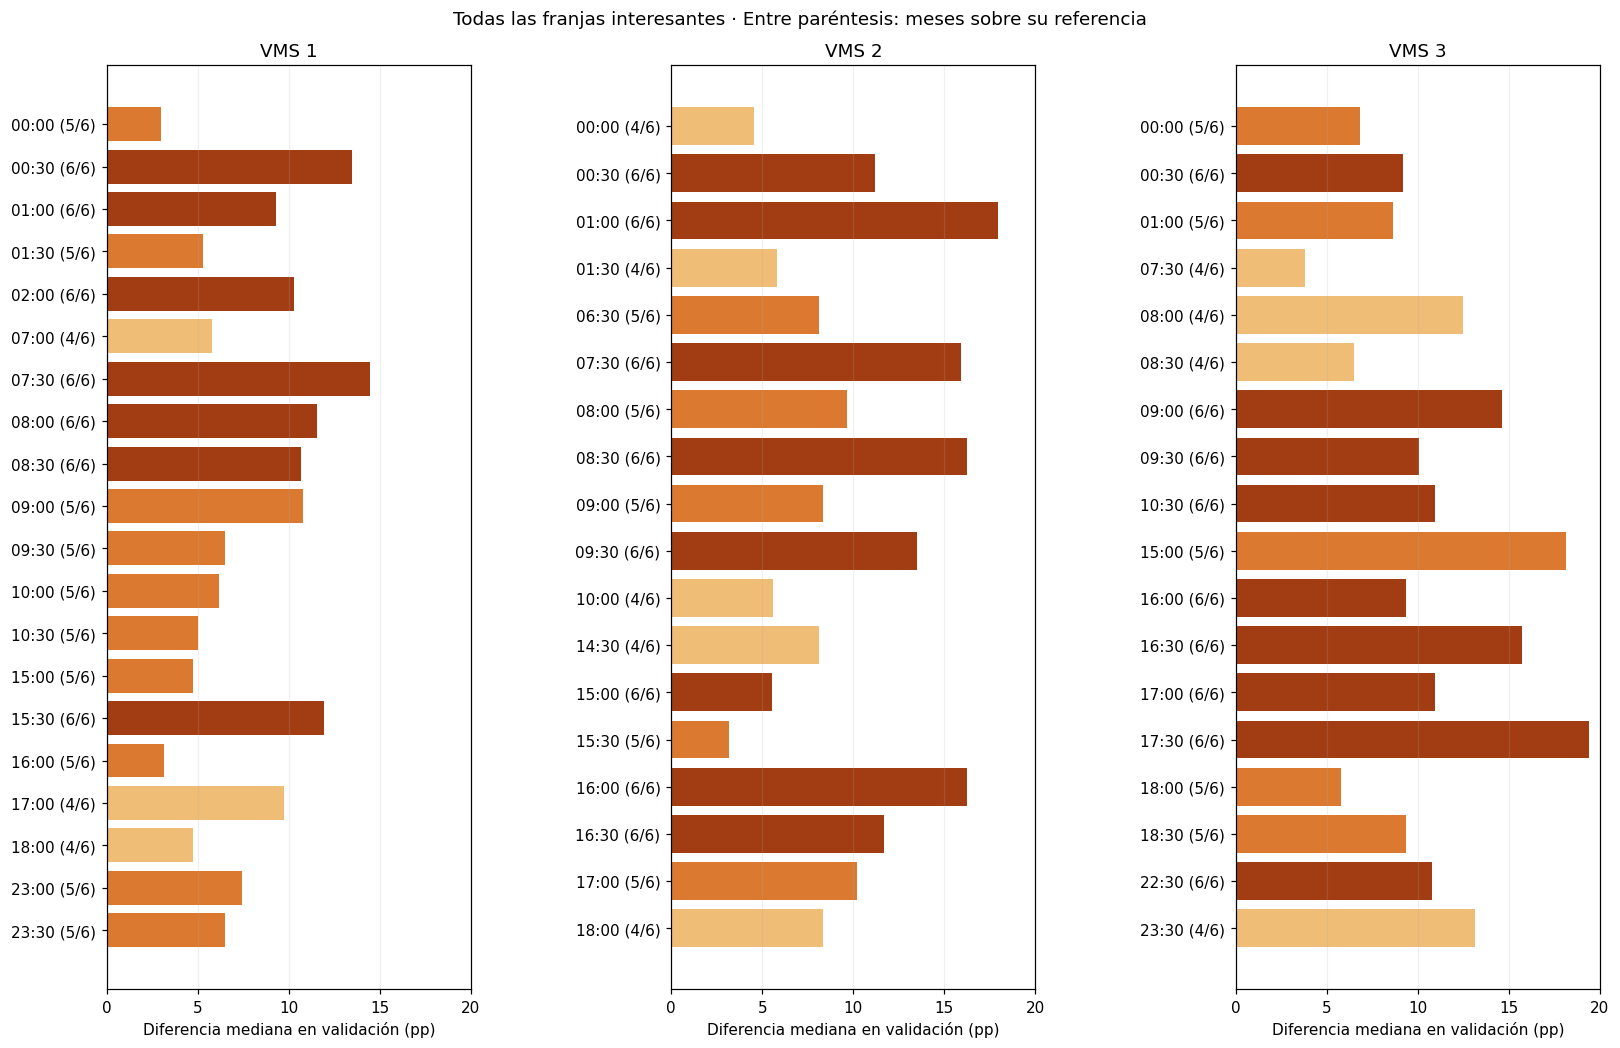

In [ ]:
def temporal_graficar_franjas_interesantes(estado):
    franjas_interesantes = estado["franjas_interesantes"]
    robots = estado["robots"]
    fig, axes = plt.subplots(1, len(robots), figsize=(15, 10))
    colores_repeticion = {"Completa": "#a23d13", "Alta": "#db7930", "Moderada": "#efbd75"}
    limite_barras = franjas_interesantes["Exceso_mediano_pp_val"].max()
    limite_barras = max(5, 5 * np.ceil(limite_barras / 5)) if np.isfinite(limite_barras) else 5
    for ax, robot in zip(np.atleast_1d(axes), robots):
        grupo = franjas_interesantes.loc[franjas_interesantes["ms"].eq(robot)].sort_values("franja")
        etiquetas = (
            grupo["Horario"]
            + " ("
            + grupo["Meses_sobre_base_val"].astype(int).astype(str)
            + "/"
            + grupo["Meses_evaluables_val"].astype(int).astype(str)
            + ")"
        )
        ax.barh(
            etiquetas,
            grupo["Exceso_mediano_pp_val"],
            color=grupo["Repeticion"].map(colores_repeticion),
        )
        ax.invert_yaxis()
        ax.set(title=robot, xlabel="Diferencia mediana en validación (pp)", xlim=(0, limite_barras))
        ax.grid(axis="x", alpha=0.2)
    fig.suptitle("Todas las franjas interesantes · Entre paréntesis: meses sobre su referencia")
    fig.subplots_adjust(left=0.08, right=0.985, bottom=0.09, top=0.93, wspace=0.55)
    return fig


fig = temporal_graficar_franjas_interesantes(temporal)
plt.show()
plt.close(fig)

Las 56 franjas muestran distinta elevación y estabilidad. Se pueden priorizar las más repetidas para observar la operación, sin asumir causalidad ni duración física de cola.

Muestra los tramos consecutivos con sus extremos y nivel de recurrencia.

In [ ]:
display(temporal["tramos_interesantes"])

,ms,Inicio,Fin_excluido,Franjas,Min_meses_sobre_base_val,Max_meses_sobre_base_val
0,VMS 1,00:00,02:30,5,5,6
1,VMS 1,07:00,11:00,8,4,6
2,VMS 1,15:00,16:30,3,5,6
3,VMS 1,17:00,17:30,1,4,4
4,VMS 1,18:00,18:30,1,4,4
5,VMS 1,23:00,24:00,2,5,5
6,VMS 2,00:00,02:00,4,4,6
7,VMS 2,06:30,07:00,1,5,5
8,VMS 2,07:30,10:30,6,4,6
9,VMS 2,14:30,17:30,6,4,6


Las franjas consecutivas facilitan comunicar periodos de observación. Un tramo de varias horas indica horarios recurrentes, no que una misma cola dure todo ese tiempo.

### 3.6 Errores de ARIMA y SARIMA

Usamos exactamente las predicciones recién calculadas con umbral real 0.5.
Las falsas alarmas se dividen entre negativos reales y las colas no detectadas entre positivos reales.

Comprueba cobertura, etiquetas y umbrales de las predicciones antes de unirlas con el calendario de prueba.

In [ ]:
def temporal_validar_predicciones(estado):
    MODELOS = estado["MODELOS"]
    predicciones = estado["predicciones"]
    seleccion = estado["seleccion"]
    test = estado["test"]
    requeridas_pred = [
        "Modelo",
        "ms",
        "bloque_tiempo",
        "Real",
        "Prediccion",
        "Cola_real",
        "Cola_predicha",
        "Umbral",
    ]
    if not set(requeridas_pred).issubset(predicciones.columns):
        raise ValueError("Faltan columnas en las predicciones.")
    predicciones = predicciones.loc[predicciones["Modelo"].isin(MODELOS)].copy()
    predicciones["bloque_tiempo"] = pd.to_datetime(predicciones["bloque_tiempo"])
    if set(predicciones["Modelo"].unique()) != set(MODELOS):
        raise ValueError("Deben estar los dos modelos y las tres referencias.")
    if predicciones.duplicated(["Modelo", "ms", "bloque_tiempo"]).any():
        raise ValueError("Hay predicciones duplicadas.")
    if not predicciones.groupby("Modelo").size().eq(len(test)).all():
        raise ValueError("Los modelos deben tener la misma cobertura de prueba.")
    verdad = test[
        [
            "ms",
            "bloque_tiempo",
            "cola",
            "pct_posible_cola",
            "franja",
            "Horario",
            "mes",
            "dia_semana",
        ]
    ]
    errores = predicciones.merge(
        verdad, on=["ms", "bloque_tiempo"], how="left", validate="many_to_one", indicator=True
    )
    if not errores["_merge"].eq("both").all():
        raise ValueError("Hay predicciones fuera de la partición de prueba.")
    np.testing.assert_allclose(errores["Real"], errores["pct_posible_cola"], atol=1e-12)
    if not errores["Cola_real"].eq(errores["cola"]).all():
        raise ValueError("La etiqueta guardada no corresponde a pct_posible_cola > 0.5.")
    if not errores["Cola_predicha"].isin([0, 1]).all():
        raise ValueError("Las etiquetas predictivas deben ser binarias.")
    umbrales_modelos = seleccion[["Robot", "Familia", "Umbral"]].rename(
        columns={"Robot": "ms", "Familia": "Modelo", "Umbral": "Umbral_validacion"}
    )
    revision = errores.loc[errores["Modelo"].isin(["ARIMA", "SARIMA"])].merge(
        umbrales_modelos, on=["Modelo", "ms"], validate="many_to_one"
    )
    np.testing.assert_allclose(revision["Umbral"], revision["Umbral_validacion"])
    assert (
        revision["Cola_predicha"]
        .eq(revision["Prediccion"].ge(revision["Umbral_validacion"]).astype(int))
        .all()
    )
    return {"predicciones": predicciones, "errores": errores}


temporal.update(temporal_validar_predicciones(temporal))

Define conteos y tasas de errores; cada tasa utiliza el conjunto de casos al que corresponde.

In [ ]:
def temporal_resumir_errores(estado, tabla, grupos):
    resultado = (
        tabla.groupby(grupos, observed=True)
        .agg(
            Bloques=("Cola_real", "size"),
            VP=("VP", "sum"),
            FP=("FP", "sum"),
            FN=("FN", "sum"),
            VN=("VN", "sum"),
            MAE=("Error_absoluto", "mean"),
            MSE=("Error_cuadrado", "mean"),
        )
        .reset_index()
    )
    resultado["Positivos"] = resultado["VP"] + resultado["FN"]
    resultado["Negativos"] = resultado["FP"] + resultado["VN"]
    resultado["Precision"] = resultado["VP"].div(
        (resultado["VP"] + resultado["FP"]).replace(0, np.nan)
    )
    resultado["Recall"] = resultado["VP"].div(resultado["Positivos"].replace(0, np.nan))
    denominador_f1 = 2 * resultado["VP"] + resultado["FP"] + resultado["FN"]
    resultado["F1"] = (2 * resultado["VP"]).div(denominador_f1.replace(0, np.nan))
    resultado["Falsas_alarmas_pct"] = 100 * resultado["FP"].div(
        resultado["Negativos"].replace(0, np.nan)
    )
    resultado["Colas_no_detectadas_pct"] = 100 * resultado["FN"].div(
        resultado["Positivos"].replace(0, np.nan)
    )
    resultado["Pred_positivas_pct"] = (
        100 * (resultado["VP"] + resultado["FP"]) / resultado["Bloques"]
    )
    resultado["Prevalencia_pct"] = 100 * resultado["Positivos"] / resultado["Bloques"]
    resultado["RMSE"] = np.sqrt(resultado.pop("MSE"))
    assert resultado[["VP", "FP", "FN", "VN"]].sum(axis=1).eq(resultado["Bloques"]).all()
    return resultado

Clasifica cada bloque como acierto, falsa alarma u omisión y calcula las métricas globales.

In [ ]:
def temporal_calcular_errores(estado):
    errores = estado["errores"]
    metricas_originales = estado["metricas_originales"]
    real = errores["Cola_real"].eq(1)
    pred = errores["Cola_predicha"].eq(1)
    errores["VP"] = (real & pred).astype(int)
    errores["FP"] = (~real & pred).astype(int)
    errores["FN"] = (real & ~pred).astype(int)
    errores["VN"] = (~real & ~pred).astype(int)
    errores["Error_absoluto"] = (errores["Real"] - errores["Prediccion"]).abs()
    errores["Error_cuadrado"] = (errores["Real"] - errores["Prediccion"]) ** 2
    metricas_globales = temporal_resumir_errores(estado, errores, ["Modelo"])
    referencia = metricas_originales.set_index("Modelo").loc[metricas_globales["Modelo"]]
    np.testing.assert_allclose(metricas_globales["F1"], referencia["F1"], atol=1e-10)
    return {"errores": errores, "metricas_globales": metricas_globales}


temporal.update(temporal_calcular_errores(temporal))

Muestra los conteos de la matriz de confusión y las tasas globales de cada aproximación.

In [ ]:
display(temporal["metricas_globales"])

,Modelo,Bloques,VP,FP,FN,VN,MAE,Positivos,Negativos,Precision,Recall,F1,Falsas_alarmas_pct,Colas_no_detectadas_pct,Pred_positivas_pct,Prevalencia_pct,RMSE
0,ARIMA,26979,15522,11457,0,0,0.3179,15522,11457,0.5753,1,0.7304,100,0,100,57.53,0.3733
1,Mismo bloque ayer,26979,10071,5415,5451,6042,0.3397,15522,11457,0.6503,0.6488,0.6496,47.26,35.12,57.4,57.53,0.4723
2,Persistencia,26979,10360,5163,5162,6294,0.3383,15522,11457,0.6674,0.6674,0.6674,45.06,33.26,57.54,57.53,0.462
3,SARIMA,26979,14883,9756,639,1701,0.3728,15522,11457,0.604,0.9588,0.7412,85.15,4.117,91.33,57.53,0.4283
4,Siempre cola,26979,15522,11457,0,0,NaN,15522,11457,0.5753,1,0.7304,100,0,100,57.53,NaN


SARIMA tiene 85.15% de falsas alarmas entre negativos reales y ARIMA 100%. Los conteos complementan F1 y muestran por qué se necesitan referencias y criterios operativos.

Desglosa los errores por robot, franja, día y mes, conservando sus denominadores.

In [ ]:
def temporal_desglosar_errores(estado):
    MIN_BLOQUES_CELDA = estado["MIN_BLOQUES_CELDA"]
    errores = estado["errores"]
    horarios = estado["horarios"]
    errores_robot = temporal_resumir_errores(estado, errores, ["Modelo", "ms"])
    errores_franja = temporal_resumir_errores(estado, errores, ["Modelo", "ms", "franja"])
    errores_dia_franja = temporal_resumir_errores(
        estado, errores, ["Modelo", "ms", "dia_semana", "franja"]
    )
    errores_mes = temporal_resumir_errores(estado, errores, ["Modelo", "mes"])
    errores_robot_mes = temporal_resumir_errores(estado, errores, ["Modelo", "ms", "mes"])
    for tabla in [errores_franja, errores_dia_franja]:
        tabla["Horario"] = tabla["franja"].map(horarios)
        tabla["Soporte_suficiente"] = tabla["Bloques"].ge(MIN_BLOQUES_CELDA)
    return {
        "errores_robot": errores_robot,
        "errores_franja": errores_franja,
        "errores_mes": errores_mes,
    }


temporal.update(temporal_desglosar_errores(temporal))

Compara falsas alarmas y omisiones por robot para revisar diferencias operativas.

In [ ]:
display(
    temporal["errores_robot"][
        [
            "Modelo",
            "ms",
            "Bloques",
            "FP",
            "FN",
            "Falsas_alarmas_pct",
            "Colas_no_detectadas_pct",
            "F1",
        ]
    ]
)

,Modelo,ms,Bloques,FP,FN,Falsas_alarmas_pct,Colas_no_detectadas_pct,F1
0,ARIMA,VMS 1,8993,3321,0,100,0,0.7735
1,ARIMA,VMS 2,8993,3890,0,100,0,0.724
2,ARIMA,VMS 3,8993,4246,0,100,0,0.691
3,Mismo bloque ayer,VMS 1,8993,1686,1707,50.77,30.1,0.7003
4,Mismo bloque ayer,VMS 2,8993,1831,1838,47.07,36.02,0.6403
5,Mismo bloque ayer,VMS 3,8993,1898,1906,44.7,40.15,0.599
6,Persistencia,VMS 1,8993,1653,1653,49.77,29.14,0.7086
7,Persistencia,VMS 2,8993,1671,1671,42.96,32.75,0.6725
8,Persistencia,VMS 3,8993,1839,1838,43.31,38.72,0.6127
9,SARIMA,VMS 1,8993,2963,189,89.22,3.332,0.7767


Las falsas alarmas de SARIMA siguen siendo elevadas en los tres robots. Un F1 global favorable no basta para asumir que todas las máquinas reciben alertas útiles.

Identifica las tres franjas de menor F1 por modelo y robot, exigiendo soporte de ambas clases.

In [ ]:
def temporal_identificar_franjas_con_mas_errores(estado):
    errores_franja = estado["errores_franja"]
    peores_franjas = (
        errores_franja.loc[
            errores_franja["Modelo"].isin(["ARIMA", "SARIMA"])
            & errores_franja["Soporte_suficiente"]
            & errores_franja["Positivos"].ge(10)
            & errores_franja["Negativos"].ge(10)
        ]
        .sort_values(["Modelo", "ms", "F1", "franja"])
        .groupby(["Modelo", "ms"], sort=False)
        .head(3)
    )
    return {"peores_franjas": peores_franjas}


temporal.update(temporal_identificar_franjas_con_mas_errores(temporal))

Muestra los horarios de menor F1 junto con prevalencia, conteos y tipos de error.

In [ ]:
display(
    temporal["peores_franjas"][
        [
            "Modelo",
            "ms",
            "Horario",
            "Bloques",
            "Positivos",
            "Negativos",
            "FP",
            "FN",
            "Falsas_alarmas_pct",
            "Colas_no_detectadas_pct",
            "F1",
        ]
    ]
)

,Modelo,ms,Horario,Bloques,Positivos,Negativos,FP,FN,Falsas_alarmas_pct,Colas_no_detectadas_pct,F1
8,ARIMA,VMS 1,04:00,187,13,174,174,0,100,0,0.13
40,ARIMA,VMS 1,20:00,188,21,167,167,0,100,0,0.201
41,ARIMA,VMS 1,20:30,188,56,132,132,0,100,0,0.459
88,ARIMA,VMS 2,20:00,188,16,172,172,0,100,0,0.1569
57,ARIMA,VMS 2,04:30,187,28,159,159,0,100,0,0.2605
89,ARIMA,VMS 2,20:30,188,35,153,153,0,100,0,0.3139
104,ARIMA,VMS 3,04:00,187,15,172,172,0,100,0,0.1485
136,ARIMA,VMS 3,20:00,188,23,165,165,0,100,0,0.218
105,ARIMA,VMS 3,04:30,187,26,161,161,0,100,0,0.2441
440,SARIMA,VMS 1,04:00,187,13,174,148,1,85.06,7.692,0.1387


Entre las franjas de menor F1 aparecen horarios como 04:00 y 20:00, con pocos positivos. Predecir casi siempre cola resulta especialmente poco útil en esas franjas.

Grafica falsas alarmas y omisiones por franja para visualizar el intercambio entre ambos errores.

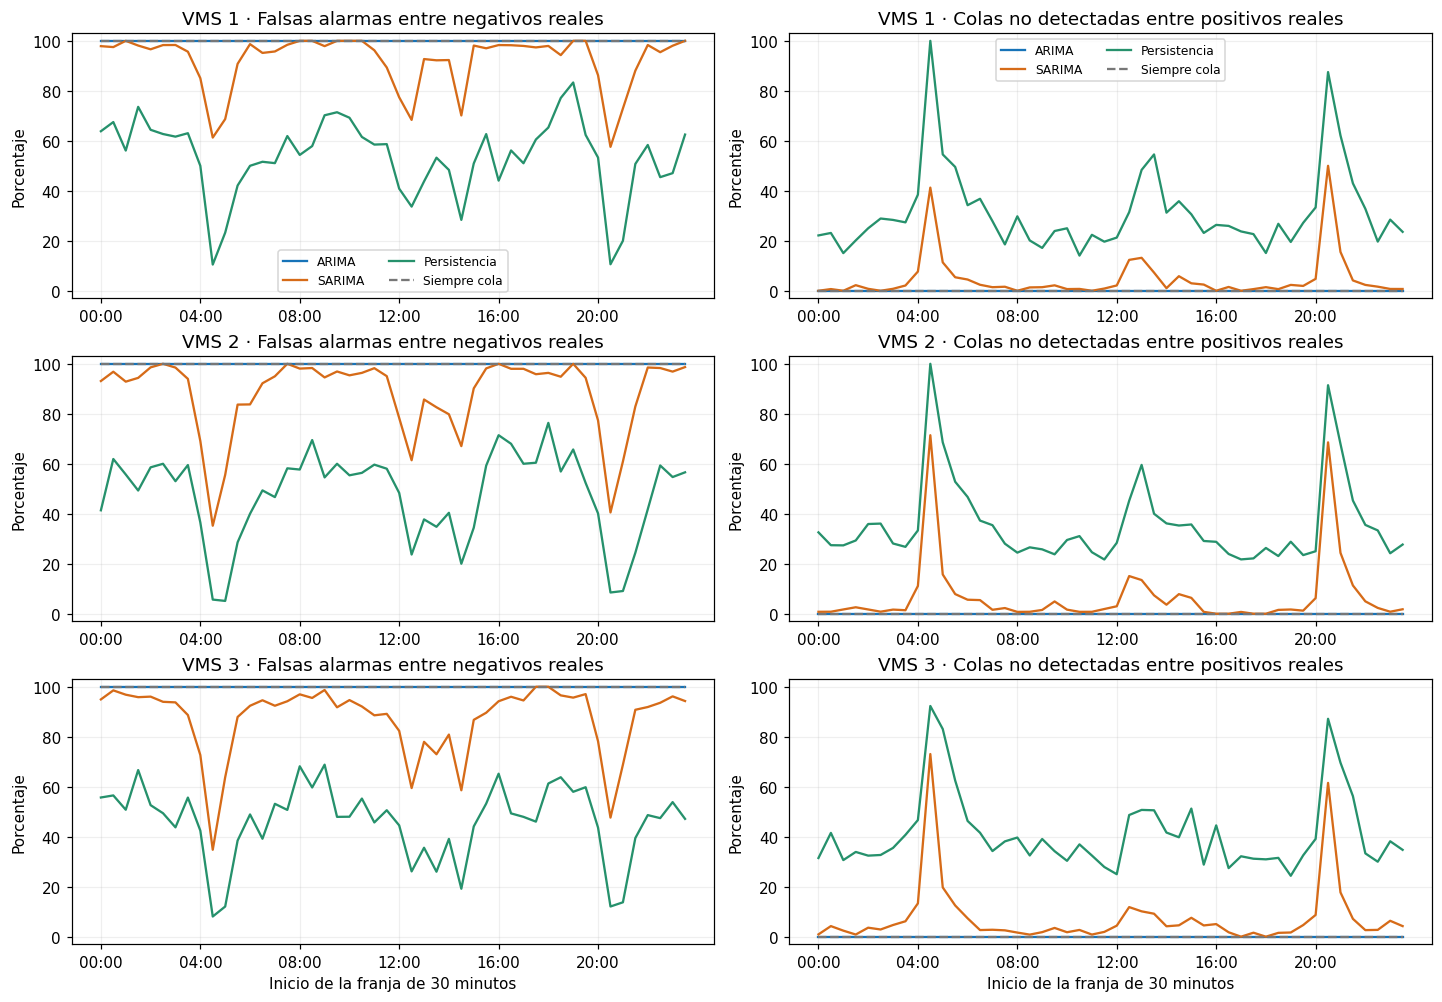

In [ ]:
def temporal_graficar_errores_por_horario(estado):
    errores_franja = estado["errores_franja"]
    horarios = estado["horarios"]
    robots = estado["robots"]
    fig, axes = plt.subplots(len(robots), 2, figsize=(13, 9), constrained_layout=True)
    colores = {
        "ARIMA": "#1673b8",
        "SARIMA": "#d66b18",
        "Persistencia": "#26916c",
        "Siempre cola": "#777777",
    }
    for fila, robot in enumerate(robots):
        for modelo, color in colores.items():
            grupo = errores_franja.loc[
                errores_franja["ms"].eq(robot) & errores_franja["Modelo"].eq(modelo)
            ].sort_values("franja")
            estilo = "--" if modelo == "Siempre cola" else "-"
            for columna, metrica in enumerate(["Falsas_alarmas_pct", "Colas_no_detectadas_pct"]):
                axes[fila, columna].plot(
                    grupo["franja"], grupo[metrica], label=modelo, color=color, linestyle=estilo
                )
        for columna, titulo in enumerate(
            ["Falsas alarmas entre negativos reales", "Colas no detectadas entre positivos reales"]
        ):
            ax = axes[fila, columna]
            ax.set(title=f"{robot} · {titulo}", ylabel="Porcentaje", ylim=(-3, 103))
            ax.set_xticks(range(0, 48, 8), [horarios[f] for f in range(0, 48, 8)])
            ax.grid(alpha=0.2)
            if fila == 0:
                ax.legend(fontsize=8, ncol=2)
    for ax in axes[-1]:
        ax.set_xlabel("Inicio de la franja de 30 minutos")
    return fig


fig = temporal_graficar_errores_por_horario(temporal)
plt.show()
plt.close(fig)

Reducir omisiones viene acompañado de muchas falsas alarmas; persistencia presenta el intercambio contrario. La decisión no puede basarse únicamente en detectar la mayor cantidad de positivos.

### 3.7 Comparación con persistencia y evolución mensual

Compara cada franja de ARIMA/SARIMA con persistencia y calcula la diferencia de F1.

In [ ]:
def temporal_preparar_f1_mensual(estado):
    errores_franja = estado["errores_franja"]
    base_franja = errores_franja.loc[
        errores_franja["Modelo"].eq("Persistencia"), ["ms", "franja", "F1"]
    ].rename(columns={"F1": "F1_persistencia"})
    comparacion_franjas = errores_franja.loc[
        errores_franja["Modelo"].isin(["ARIMA", "SARIMA"])
    ].merge(base_franja, on=["ms", "franja"], validate="many_to_one")
    comparacion_franjas["Delta_F1_vs_persistencia"] = (
        comparacion_franjas["F1"] - comparacion_franjas["F1_persistencia"]
    )
    return {"comparacion_franjas": comparacion_franjas}


temporal.update(temporal_preparar_f1_mensual(temporal))

Grafica la evolución mensual del F1 de los modelos y sus referencias en prueba.

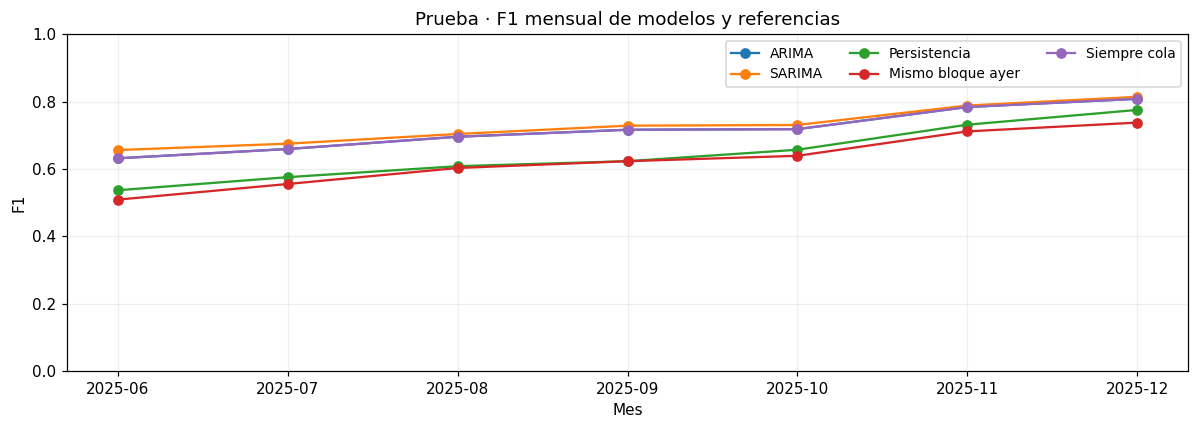

In [ ]:
def temporal_graficar_f1_mensual(estado):
    MODELOS = estado["MODELOS"]
    errores_mes = estado["errores_mes"]
    fig, ax = plt.subplots(figsize=(11, 4))
    for modelo in MODELOS:
        grupo = errores_mes.loc[errores_mes["Modelo"].eq(modelo)].sort_values("mes")
        ax.plot(grupo["mes"], grupo["F1"], marker="o", label=modelo)
    ax.set(
        title="Prueba · F1 mensual de modelos y referencias", xlabel="Mes", ylabel="F1", ylim=(0, 1)
    )
    ax.legend(ncol=3, fontsize=9)
    ax.grid(alpha=0.2)
    fig.tight_layout()
    return fig


fig = temporal_graficar_f1_mensual(temporal)
plt.show()
plt.close(fig)

ARIMA coincide con siempre cola y SARIMA queda cerca de esa línea. La subida del F1 mensual debe leerse con la prevalencia, no como prueba de un aprendizaje cada vez mejor.

Muestra los valores mensuales de F1, prevalencia y tasas de error que explican la gráfica.

In [ ]:
display(
    temporal["errores_mes"][
        [
            "Modelo",
            "mes",
            "Bloques",
            "Prevalencia_pct",
            "F1",
            "Falsas_alarmas_pct",
            "Colas_no_detectadas_pct",
        ]
    ]
)

,Modelo,mes,Bloques,Prevalencia_pct,F1,Falsas_alarmas_pct,Colas_no_detectadas_pct
0,ARIMA,2025-06,483,46.17,0.6317,100,0
1,ARIMA,2025-07,4464,49.17,0.6593,100,0
2,ARIMA,2025-08,4464,53.34,0.6957,100,0
3,ARIMA,2025-09,4320,55.81,0.7164,100,0
4,ARIMA,2025-10,4464,56.03,0.7182,100,0
5,ARIMA,2025-11,4320,64.44,0.7838,100,0
6,ARIMA,2025-12,4464,67.81,0.8082,100,0
7,Mismo bloque ayer,2025-06,483,46.17,0.5091,40.38,49.78
8,Mismo bloque ayer,2025-07,4464,49.17,0.5555,42.62,44.6
9,Mismo bloque ayer,2025-08,4464,53.34,0.6029,45.32,39.73


La prevalencia pasa de 46.17% en el fragmento de junio a 67.81% en diciembre. Cambia la dificultad de la clasificación y junio no equivale a un mes completo.

Muestra la ganancia o pérdida de F1 frente a persistencia en cada robot y horario.

In [ ]:
display(
    temporal["comparacion_franjas"][
        ["Modelo", "ms", "Horario", "F1", "F1_persistencia", "Delta_F1_vs_persistencia"]
    ]
)

,Modelo,ms,Horario,F1,F1_persistencia,Delta_F1_vs_persistencia
0,ARIMA,VMS 1,00:00,0.8563,0.7814,0.07491
1,ARIMA,VMS 1,00:30,0.8802,0.7875,0.09278
2,ARIMA,VMS 1,01:00,0.8769,0.8464,0.03046
3,ARIMA,VMS 1,01:30,0.8349,0.7643,0.07061
4,ARIMA,VMS 1,02:00,0.8127,0.7328,0.07987
5,ARIMA,VMS 1,02:30,0.8127,0.7109,0.1018
6,ARIMA,VMS 1,03:00,0.8089,0.7137,0.09519
7,ARIMA,VMS 1,03:30,0.6738,0.6216,0.05214
8,ARIMA,VMS 1,04:00,0.13,0.1481,-0.01815
9,ARIMA,VMS 1,04:30,0.504,0,0.504


La ventaja frente a persistencia no es uniforme y existen franjas donde se pierde F1. Se evalúa la mejora por horario antes de trasladar el resultado global a la operación.

Compara errores dentro y fuera de las franjas candidatas elegidas en entrenamiento.

In [ ]:
def temporal_comparar_errores_en_candidatas(estado):
    candidatos = estado["candidatos"]
    errores = estado["errores"]
    claves_candidatos = candidatos[["ms", "franja"]].assign(Franja_candidata=True)
    errores = errores.drop(columns="_merge").merge(
        claves_candidatos, on=["ms", "franja"], how="left", validate="many_to_one"
    )
    errores["Franja_candidata"] = errores["Franja_candidata"].eq(True)
    errores_candidatos = temporal_resumir_errores(
        estado, errores, ["Modelo", "ms", "Franja_candidata"]
    )
    return {"errores": errores, "errores_candidatos": errores_candidatos}


temporal.update(temporal_comparar_errores_en_candidatas(temporal))

Muestra cómo cambian prevalencia y errores en las franjas candidatas sin reajustar modelos.

In [ ]:
display(
    temporal["errores_candidatos"].loc[
        temporal["errores_candidatos"]["Modelo"].isin(["ARIMA", "SARIMA"]),
        ["Modelo", "ms", "Franja_candidata", "Bloques", "Prevalencia_pct", "FP", "FN", "F1"],
    ]
)

,Modelo,ms,Franja_candidata,Bloques,Prevalencia_pct,FP,FN,F1
0,ARIMA,VMS 1,False,4684,53.84,2162,0,0.7
1,ARIMA,VMS 1,True,4309,73.1,1159,0,0.8446
2,ARIMA,VMS 2,False,5435,50.36,2698,0,0.6698
3,ARIMA,VMS 2,True,3558,66.5,1192,0,0.7988
4,ARIMA,VMS 3,False,4870,47.49,2557,0,0.644
5,ARIMA,VMS 3,True,4123,59.03,1689,0,0.7424
18,SARIMA,VMS 1,False,4684,53.84,1842,150,0.7043
19,SARIMA,VMS 1,True,4309,73.1,1121,39,0.8429
20,SARIMA,VMS 2,False,5435,50.36,2130,153,0.6936
21,SARIMA,VMS 2,True,3558,66.5,1108,58,0.7983


Las franjas candidatas tienen mayor prevalencia, lo que también eleva su F1. El desglose relaciona recurrencia y errores, pero no demuestra que el modelo mejore por estar en esa franja.

### 3.8 Conclusión

De 144 combinaciones, 64 fueron candidatas en entrenamiento y 56 mantuvieron recurrencia en validación.
Otras 29 muestran elevaciones recientes. La repetición mensual no equivale a significancia estadística por franja.

## 4. Lactancia y posible cola

Estudiamos la composición por etapas dentro de los bloques con ordeños y etapa conocida.
El archivo contiene proporciones agregadas, no trayectorias individuales de vacas ni días exactos en leche.

### 4.1 Configuración, disponibilidad y muestra

Configura las etapas, los contrastes de diez puntos porcentuales y el nivel de significancia de lactancia.

In [ ]:
lactancia = iniciar_analisis(base, calendario)
lactancia.update(
    {
        "ALFA": 0.05,
        "ETAPAS": ["pct_fresca", "pct_alta", "pct_baja", "pct_extendida"],
        "VARIABLES": {
            "alta_10pp": "Alta frente a fresca",
            "baja_10pp": "Baja frente a fresca",
            "extendida_10pp": "Extendida frente a fresca",
            "primer_parto_10pp": "Primer parto",
        },
        "PERIODOS": ["Entrenamiento", "Validación", "Prueba"],
    }
)

Selecciona bloques con ordeños y etapa conocida, y comprueba que las proporciones de etapas sumen uno.

In [ ]:
def lactancia_preparar_muestra(estado):
    ETAPAS = estado["ETAPAS"]
    UMBRAL_REAL = estado["UMBRAL_REAL"]
    datos = estado["datos"]
    necesarias = [
        "ms",
        "bloque_tiempo",
        "pct_posible_cola",
        "hubo_ordenios",
        "sin_etapa",
        "total_ordenios",
        "pct_primer_parto",
        *ETAPAS,
    ]
    if not set(necesarias).issubset(datos.columns):
        raise ValueError("Faltan columnas para analizar lactancia.")
    datos = datos[necesarias].copy()
    datos["bloque_tiempo"] = pd.to_datetime(datos["bloque_tiempo"])
    datos = datos.sort_values(["bloque_tiempo", "ms"]).reset_index(drop=True)
    if datos[necesarias].isna().any().any() or datos.duplicated(["ms", "bloque_tiempo"]).any():
        raise ValueError("Revisa faltantes o bloques duplicados.")
    for columna in ["pct_posible_cola", "pct_primer_parto", *ETAPAS]:
        if not datos[columna].between(0, 1).all():
            raise ValueError(f"Valores fuera de 0 a 1: {columna}")
    datos["cola"] = datos["pct_posible_cola"].gt(UMBRAL_REAL).astype(int)
    datos["Estado"] = np.select(
        [datos["hubo_ordenios"].eq(0), datos["hubo_ordenios"].eq(1) & datos["sin_etapa"].eq(1)],
        ["Sin ordeños", "Con ordeños, etapa desconocida"],
        default="Con ordeños y etapa disponible",
    )
    disponibilidad = datos.groupby("Estado").agg(
        Bloques=("cola", "size"), Bloques_positivos=("cola", "sum")
    )
    disponibilidad["Porcentaje_dataset"] = 100 * disponibilidad["Bloques"] / len(datos)
    muestra = datos.loc[datos["hubo_ordenios"].eq(1) & datos["sin_etapa"].eq(0)].copy()
    np.testing.assert_allclose(muestra[ETAPAS].sum(axis=1), 1, atol=1e-10)
    if not muestra["total_ordenios"].ge(1).all():
        raise ValueError("Los bloques seleccionados deben tener ordeños.")
    return {"datos": datos, "disponibilidad": disponibilidad, "muestra": muestra}


lactancia.update(lactancia_preparar_muestra(lactancia))

Muestra los bloques utilizables y los excluidos por ausencia de ordeños o etapa desconocida.

In [ ]:
display(lactancia["disponibilidad"].reset_index())

,Estado,Bloques,Bloques_positivos,Porcentaje_dataset
0,Con ordeños y etapa disponible,123040,44830,68.41
1,"Con ordeños, etapa desconocida",9018,624,5.014
2,Sin ordeños,47792,0,26.57


Solo 123,040 bloques tienen ordeños y etapa conocida; 9,018 tienen etapa desconocida y 47,792 no tienen ordeños. No se interpretan como etapas biológicas los registros sin composición disponible.

Asigna los mismos periodos al subconjunto de lactancia y calcula su cobertura temporal.

In [ ]:
def lactancia_resumir_periodos(estado):
    INICIO_TEST = estado["INICIO_TEST"]
    INICIO_VAL = estado["INICIO_VAL"]
    PERIODOS = estado["PERIODOS"]
    datos = estado["datos"]
    muestra = estado["muestra"]
    for tabla in [datos, muestra]:
        tabla["Periodo"] = np.where(
            tabla["bloque_tiempo"] < INICIO_VAL,
            "Entrenamiento",
            np.where(tabla["bloque_tiempo"] < INICIO_TEST, "Validación", "Prueba"),
        )
        tabla["mes"] = tabla["bloque_tiempo"].dt.to_period("M").astype(str)
    cobertura = datos.groupby(["Periodo", "Estado"]).size().rename("Bloques").reset_index()
    resumen_muestra = (
        muestra.groupby("Periodo")
        .agg(
            Bloques=("cola", "size"),
            Fechas=("bloque_tiempo", lambda s: s.dt.date.nunique()),
            Inicio=("bloque_tiempo", "min"),
            Fin=("bloque_tiempo", "max"),
            Frecuencia_cola=("cola", "mean"),
            Indicador_medio=("pct_posible_cola", "mean"),
        )
        .reindex(PERIODOS)
    )
    resumen_muestra["Frecuencia_cola_pct"] = 100 * resumen_muestra.pop("Frecuencia_cola")
    return {"cobertura": cobertura, "resumen_muestra": resumen_muestra}


lactancia.update(lactancia_resumir_periodos(lactancia))

Muestra tamaño y frecuencia de posible cola del subconjunto de lactancia en cada periodo.

In [ ]:
display(lactancia["resumen_muestra"].reset_index())

,Periodo,Bloques,Fechas,Inicio,Fin,Indicador_medio,Frecuencia_cola_pct
0,Entrenamiento,76014,861,2022-08-15 07:30:00,2024-12-22 06:30:00,0.3239,23.47
1,Validación,23140,188,2024-12-22 07:00:00,2025-06-27 15:00:00,0.551,49.59
2,Prueba,23886,188,2025-06-27 15:30:00,2025-12-31 23:30:00,0.6677,64.96


La muestra de lactancia y su prevalencia difieren de la serie completa. Se comparan asociaciones entre periodos, sin trasladar directamente sus tasas a la evaluación de ARIMA/SARIMA.

Desglosa exclusiones por periodo para revisar cambios de cobertura y disponibilidad de etapas.

In [ ]:
display(lactancia["cobertura"])

,Periodo,Estado,Bloques
0,Entrenamiento,Con ordeños y etapa disponible,76014
1,Entrenamiento,"Con ordeños, etapa desconocida",8953
2,Entrenamiento,Sin ordeños,40925
3,Prueba,Con ordeños y etapa disponible,23886
4,Prueba,"Con ordeños, etapa desconocida",32
5,Prueba,Sin ordeños,3061
6,Validación,Con ordeños y etapa disponible,23140
7,Validación,"Con ordeños, etapa desconocida",33
8,Validación,Sin ordeños,3806


Las exclusiones por etapa desconocida se concentran en entrenamiento. El cambio de cobertura obliga a considerar el calendario al analizar lactancia.

### 4.2 Comparaciones descriptivas por etapa mayoritaria

Una etapa es mayoritaria si representa más del 50% de los ordeños del bloque; los demás bloques son mixtos.
Las tasas sin ajuste pueden reflejar diferencias de calendario y actividad.

Asigna una etapa mayoritaria cuando supera 50% y resume las tasas descriptivas de cada grupo.

In [ ]:
def lactancia_preparar_frecuencia_etapa_mayoritaria(estado):
    muestra = estado["muestra"]
    nombres_etapas = {
        "pct_fresca": "Fresca",
        "pct_alta": "Alta",
        "pct_baja": "Baja",
        "pct_extendida": "Extendida",
    }
    muestra["Etapa_mayoritaria"] = "Mixto: ninguna supera 50%"
    for columna, nombre in nombres_etapas.items():
        muestra.loc[muestra[columna].gt(0.5), "Etapa_mayoritaria"] = nombre
    descriptivo = (
        muestra.groupby("Etapa_mayoritaria")
        .agg(
            Bloques=("cola", "size"),
            Positivos=("cola", "sum"),
            Frecuencia_cola=("cola", "mean"),
            Indicador_medio=("pct_posible_cola", "mean"),
            Ordenios_promedio=("total_ordenios", "mean"),
        )
        .reset_index()
    )
    descriptivo["Frecuencia_cola_pct"] = 100 * descriptivo.pop("Frecuencia_cola")
    descriptivo_robot_periodo = (
        muestra.groupby(["ms", "Periodo", "Etapa_mayoritaria"])
        .agg(Bloques=("cola", "size"), Positivos=("cola", "sum"), Frecuencia_cola=("cola", "mean"))
        .reset_index()
    )
    descriptivo_robot_periodo["Frecuencia_cola_pct"] = 100 * descriptivo_robot_periodo.pop(
        "Frecuencia_cola"
    )
    return {
        "nombres_etapas": nombres_etapas,
        "muestra": muestra,
        "descriptivo": descriptivo,
        "descriptivo_robot_periodo": descriptivo_robot_periodo,
    }


lactancia.update(lactancia_preparar_frecuencia_etapa_mayoritaria(lactancia))

Grafica la frecuencia sin ajustar por etapa mayoritaria, mostrando el tamaño de cada grupo.

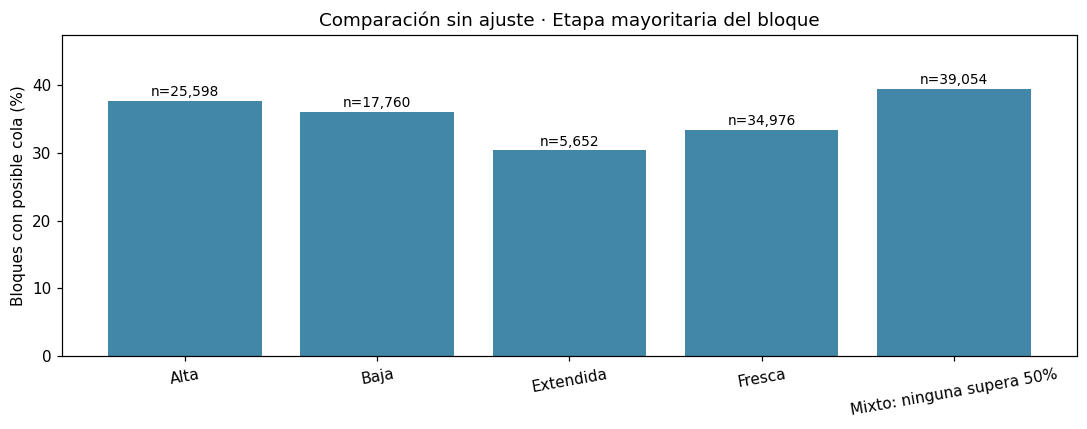

In [ ]:
def lactancia_graficar_frecuencia_etapa_mayoritaria(estado):
    descriptivo = estado["descriptivo"]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(descriptivo["Etapa_mayoritaria"], descriptivo["Frecuencia_cola_pct"], color="#4286a8")
    for i, fila in descriptivo.iterrows():
        ax.text(
            i, fila["Frecuencia_cola_pct"] + 0.7, f"n={fila['Bloques']:,}", ha="center", fontsize=9
        )
    ax.set(
        title="Comparación sin ajuste · Etapa mayoritaria del bloque",
        ylabel="Bloques con posible cola (%)",
    )
    ax.set_ylim(0, descriptivo["Frecuencia_cola_pct"].max() + 8)
    ax.tick_params(axis="x", labelrotation=10)
    fig.tight_layout()
    return fig


fig = lactancia_graficar_frecuencia_etapa_mayoritaria(lactancia)
plt.show()
plt.close(fig)

Los bloques mixtos muestran la mayor frecuencia descriptiva y los de extendida una menor. La diferencia puede reflejar composición y actividad, por lo que requiere ajuste.

Muestra los porcentajes descriptivos junto con actividad media y tamaño de muestra.

In [ ]:
display(lactancia["descriptivo"])

,Etapa_mayoritaria,Bloques,Positivos,Indicador_medio,Ordenios_promedio,Frecuencia_cola_pct
0,Alta,25598,9647,0.3997,1.926,37.69
1,Baja,17760,6392,0.3764,1.891,35.99
2,Extendida,5652,1716,0.3186,1.663,30.36
3,Fresca,34976,11678,0.3719,1.87,33.39
4,Mixto: ninguna supera 50%,39054,15397,0.5529,2.515,39.42


Los bloques mixtos tienen también más ordeños en promedio. Se añade actividad como sensibilidad para no atribuir esa diferencia directamente a una etapa.

Desglosa la comparación descriptiva por robot y periodo para identificar posibles mezclas de contextos.

In [ ]:
display(lactancia["descriptivo_robot_periodo"])

,ms,Periodo,Etapa_mayoritaria,Bloques,Positivos,Frecuencia_cola_pct
0,VMS 1,Entrenamiento,Alta,6340,1840,29.02
1,VMS 1,Entrenamiento,Baja,4294,1194,27.81
2,VMS 1,Entrenamiento,Extendida,1081,289,26.73
3,VMS 1,Entrenamiento,Fresca,6219,1608,25.86
4,VMS 1,Entrenamiento,Mixto: ninguna supera 50%,8305,2377,28.62
5,VMS 1,Prueba,Alta,1982,1435,72.4
6,VMS 1,Prueba,Baja,944,728,77.12
7,VMS 1,Prueba,Extendida,71,31,43.66
8,VMS 1,Prueba,Fresca,1762,1313,74.52
9,VMS 1,Prueba,Mixto: ninguna supera 50%,3166,2163,68.32


Las tasas se comparan dentro de robot y periodo, en lugar de mezclar todos los contextos. Este desglose motiva controles de calendario y evaluaciones específicas por máquina.

Calcula la composición media de etapas y la frecuencia del indicador por robot y mes.

In [ ]:
def lactancia_preparar_composicion_mensual(estado):
    ETAPAS = estado["ETAPAS"]
    muestra = estado["muestra"]
    mensual = muestra.groupby(["ms", "mes"])[ETAPAS + ["cola"]].mean().reset_index()
    robots = sorted(muestra["ms"].unique())
    return {"mensual": mensual, "robots": robots}


lactancia.update(lactancia_preparar_composicion_mensual(lactancia))

Grafica cambios de composición y de frecuencia a lo largo del calendario.

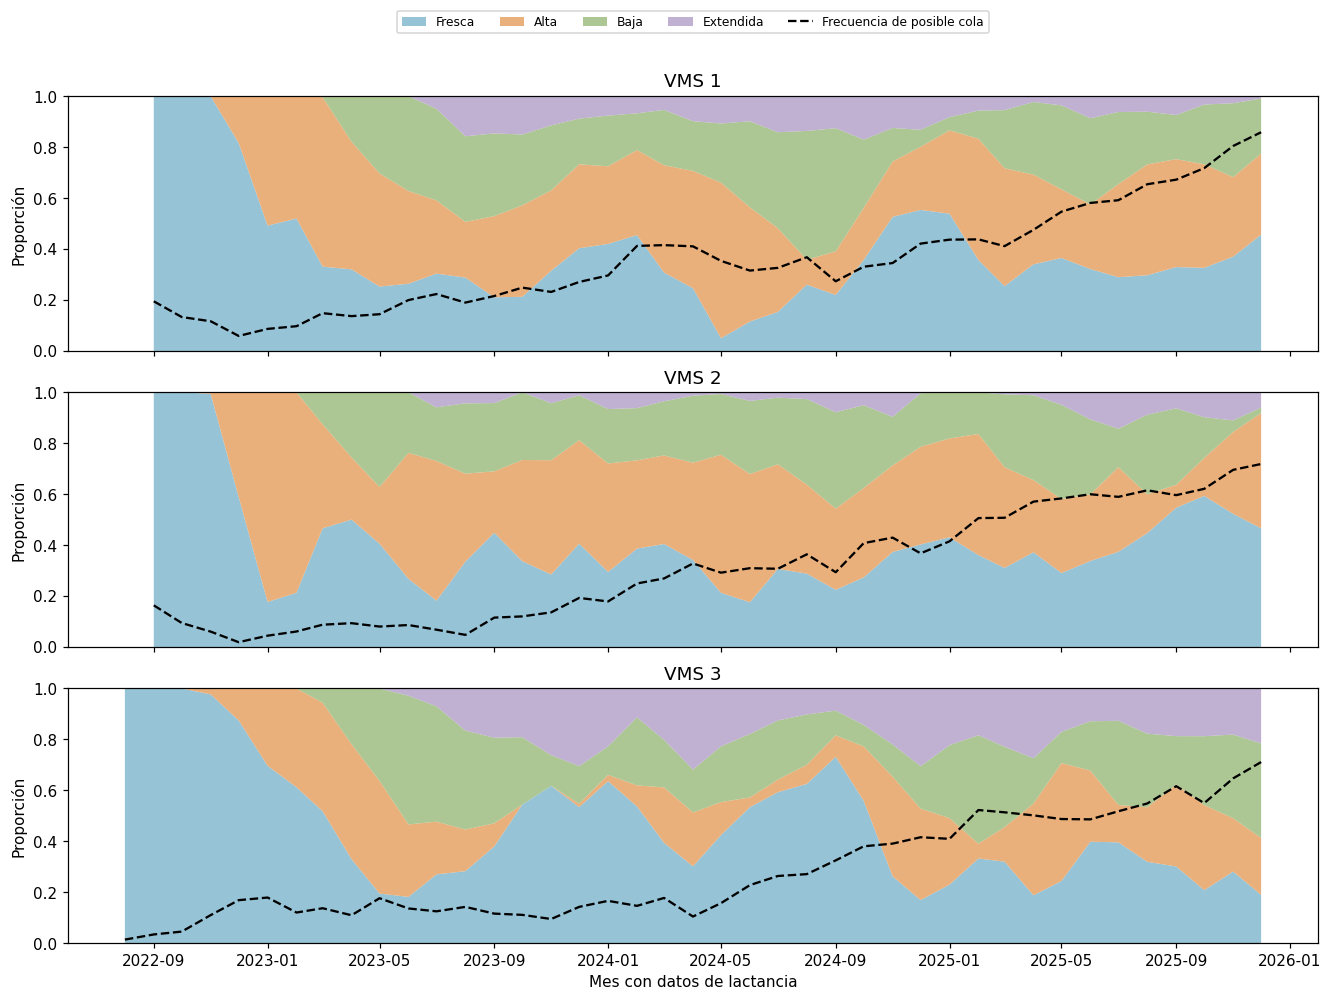

In [ ]:
def lactancia_graficar_composicion_mensual(estado):
    ETAPAS = estado["ETAPAS"]
    mensual = estado["mensual"]
    nombres_etapas = estado["nombres_etapas"]
    robots = estado["robots"]
    fig, axes = plt.subplots(len(robots), 1, figsize=(12, 9), sharex=True, constrained_layout=True)
    colores = ["#85b9cf", "#e7a265", "#9ebd81", "#b5a2c9"]
    for ax, robot in zip(np.atleast_1d(axes), robots):
        grupo = mensual.loc[mensual["ms"].eq(robot)].sort_values("mes")
        tiempo = pd.to_datetime(grupo["mes"])
        ax.stackplot(
            tiempo,
            *[grupo[c].to_numpy() for c in ETAPAS],
            colors=colores,
            labels=[nombres_etapas[c] for c in ETAPAS],
            alpha=0.85
        )
        ax.plot(
            tiempo, grupo["cola"], color="black", linestyle="--", label="Frecuencia de posible cola"
        )
        ax.set(title=robot, ylabel="Proporción", ylim=(0, 1))
    axes[0].legend(ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 1.36))
    axes[-1].set_xlabel("Mes con datos de lactancia")
    return fig


fig = lactancia_graficar_composicion_mensual(lactancia)
plt.show()
plt.close(fig)

Cambian simultáneamente la composición y la frecuencia de posible cola a lo largo del tiempo. Su coincidencia visual no identifica una causa, por eso se controla robot y mes.

### 4.3 Funciones de regresión y controles

La logística incluye etapa, primer parto, robot por mes, horario propio de cada robot y día de la semana.
Fresca es la referencia; cada coeficiente representa diez puntos porcentuales de composición.

Construye las variables de composición y los controles de calendario y actividad de las regresiones.

In [ ]:
def lactancia_construir_controles(estado):
    VARIABLES = estado["VARIABLES"]
    muestra = estado["muestra"]
    robots = estado["robots"]
    muestra["franja"] = (
        muestra["bloque_tiempo"].dt.hour * 2 + muestra["bloque_tiempo"].dt.minute // 30
    )
    muestra["dia_semana"] = muestra["bloque_tiempo"].dt.dayofweek
    muestra["semana"] = muestra["bloque_tiempo"].dt.to_period("W-SUN").astype(str)
    muestra["robot_mes"] = muestra["ms"] + "|" + muestra["mes"]
    muestra["ordenios_grupo"] = muestra["total_ordenios"].clip(upper=4).astype(str)
    for origen, destino in [
        ("pct_alta", "alta_10pp"),
        ("pct_baja", "baja_10pp"),
        ("pct_extendida", "extendida_10pp"),
        ("pct_primer_parto", "primer_parto_10pp"),
    ]:
        muestra[destino] = 10 * muestra[origen]
    reloj = []
    for i, robot in enumerate(robots):
        columna = f"franja_robot_{i}"
        muestra[columna] = np.where(muestra["ms"].eq(robot), muestra["franja"], 0)
        reloj.append(f"C({columna})")
    PREDICTORES = " + ".join(VARIABLES)
    CONTROLES = "C(robot_mes) + C(dia_semana) + " + " + ".join(reloj)
    FORMULA_BASE = PREDICTORES + " + " + CONTROLES
    return {"muestra": muestra, "FORMULA_BASE": FORMULA_BASE}


lactancia.update(lactancia_construir_controles(lactancia))

Agrupamos los errores por semana calendario y corregimos con Holm las cuatro variables de interés de cada ajuste.
Los intervalos son individuales. La sensibilidad añade el número de ordeños; los ajustes son exploratorios y no causales.

Define ajustes logísticos y lineales, errores agrupados por semana y corrección de Holm para las variables de interés.

In [ ]:
def lactancia_ajustar(estado, tabla, nombre, respuesta="cola", actividad=False):
    ALFA = estado["ALFA"]
    FORMULA_BASE = estado["FORMULA_BASE"]
    VARIABLES = estado["VARIABLES"]
    coeficientes_completos = estado["coeficientes_completos"]
    registro = estado["registro"]
    formula = respuesta + " ~ " + FORMULA_BASE + (" + C(ordenios_grupo)" if actividad else "")
    grupos = pd.factorize(tabla["semana"])[0]
    if tabla["semana"].nunique() < 20:
        raise ValueError("Se necesitan al menos 20 semanas para esta comparación.")
    inicio = perf_counter()
    with warnings.catch_warnings(record=True) as avisos:
        if respuesta == "cola":
            resultado = smf.glm(formula, data=tabla, family=sm.families.Binomial()).fit(
                maxiter=100,
                tol=1e-08,
                cov_type="cluster",
                cov_kwds={"groups": grupos, "use_correction": True},
                use_t=True,
            )
            converge = bool(resultado.converged)
        else:
            resultado = smf.ols(formula, data=tabla).fit(
                cov_type="cluster", cov_kwds={"groups": grupos, "use_correction": True}, use_t=True
            )
            converge = True
    rango = int(resultado.df_model + 1)
    if not converge or rango != len(resultado.params) or (not np.isfinite(resultado.params).all()):
        raise RuntimeError(f"Revisa convergencia o rango de {nombre}.")
    registro.append(
        {
            "Modelo": nombre,
            "Respuesta": respuesta,
            "Ajuste_actividad": actividad,
            "Bloques": len(tabla),
            "Semanas": tabla["semana"].nunique(),
            "Parametros": len(resultado.params),
            "Rango": rango,
            "Convergio": converge,
            "Segundos": perf_counter() - inicio,
            "Formula": formula,
            "Avisos": " | ".join((str(a.message) for a in avisos)),
        }
    )
    intervalos = resultado.conf_int()
    completo = pd.DataFrame(
        {
            "Variable": resultado.params.index,
            "Coeficiente": resultado.params.to_numpy(),
            "IC_inferior": intervalos.iloc[:, 0].to_numpy(),
            "IC_superior": intervalos.iloc[:, 1].to_numpy(),
            "p": resultado.pvalues.to_numpy(),
            "Modelo": nombre,
        }
    )
    coeficientes_completos.append(completo)
    tabla_coef = completo.loc[completo["Variable"].isin(VARIABLES)].copy()
    tabla_coef["Comparacion"] = tabla_coef["Variable"].map(VARIABLES)
    tabla_coef["p_Holm"] = multipletests(tabla_coef["p"], alpha=ALFA, method="holm")[1]
    tabla_coef["Respaldo_Holm"] = tabla_coef["p_Holm"].lt(ALFA)
    if respuesta == "cola":
        tabla_coef["OR_10pp"] = np.exp(tabla_coef["Coeficiente"])
        tabla_coef["OR_IC_inf"] = np.exp(tabla_coef["IC_inferior"])
        tabla_coef["OR_IC_sup"] = np.exp(tabla_coef["IC_superior"])
    else:
        tabla_coef["Cambio_indicador_pp"] = 100 * tabla_coef["Coeficiente"]
        tabla_coef["Cambio_IC_inf_pp"] = 100 * tabla_coef["IC_inferior"]
        tabla_coef["Cambio_IC_sup_pp"] = 100 * tabla_coef["IC_superior"]
    return (resultado, tabla_coef)

Inicializa el registro de ajustes y coeficientes para comprobar convergencia y revisar los resultados.

In [ ]:
def lactancia_iniciar_registro(estado):
    registro = []
    coeficientes_completos = []
    return {"registro": registro, "coeficientes_completos": coeficientes_completos}


lactancia.update(lactancia_iniciar_registro(lactancia))

Define un ejercicio ajustado de diez puntos de composición y su intervalo, expresado en puntos porcentuales de frecuencia.

In [ ]:
def lactancia_cambios_ajustados(estado, resultado, tabla, nombre):
    VARIABLES = estado["VARIABLES"]
    matriz = np.asarray(resultado.model.exog)
    parametros = np.asarray(resultado.params)
    covarianza = np.asarray(resultado.cov_params())
    lineal = matriz @ parametros
    critico = t_student.ppf(0.975, tabla["semana"].nunique() - 1)
    filas = []
    for variable in VARIABLES:
        mascara = (
            tabla["pct_primer_parto"].le(0.9)
            if variable == "primer_parto_10pp"
            else tabla["pct_fresca"].ge(0.1)
        ).to_numpy()
        j = resultado.model.exog_names.index(variable)
        p0 = expit(lineal[mascara])
        p1 = expit(lineal[mascara] + parametros[j])
        w0, w1 = (p0 * (1 - p0), p1 * (1 - p1))
        gradiente = matriz[mascara].T @ (w1 - w0) / mascara.sum()
        gradiente[j] += w1.mean()
        error = np.sqrt(max(0, float(gradiente @ covarianza @ gradiente)))
        diferencia = (p1 - p0).mean()
        filas.append(
            {
                "Modelo": nombre,
                "Variable": variable,
                "Comparacion": VARIABLES[variable],
                "Bloques_ejercicio": int(mascara.sum()),
                "Frecuencia_base_pct": 100 * p0.mean(),
                "Frecuencia_comparada_pct": 100 * p1.mean(),
                "Cambio_frecuencia_pp": 100 * diferencia,
                "IC_inferior_pp": 100 * (diferencia - critico * error),
                "IC_superior_pp": 100 * (diferencia + critico * error),
            }
        )
    return pd.DataFrame(filas)

### 4.4 Asociación ajustada y sensibilidad a la actividad

Comparamos calendario frente a calendario y actividad. El ejercicio ajustado sustituye diez puntos de fresca por otra etapa.
Es una interpolación del modelo; no representa un cambio observado en una misma vaca.

Ajusta el histórico con calendario y repite incluyendo actividad para revisar sensibilidad de las asociaciones.

In [ ]:
def lactancia_ajustar_modelos_completos(estado):
    muestra = estado["muestra"]
    coef_logisticos = []
    ejercicios = []
    for nombre, actividad in [
        ("Completo · calendario", False),
        ("Completo · calendario y actividad", True),
    ]:
        resultado, coef = lactancia_ajustar(estado, muestra, nombre, actividad=actividad)
        coef_logisticos.append(coef)
        ejercicios.append(lactancia_cambios_ajustados(estado, resultado, muestra, nombre))
        del resultado
        gc.collect()
    asociaciones_completas = pd.concat(coef_logisticos, ignore_index=True)
    cambios_completos = pd.concat(ejercicios, ignore_index=True)
    return {
        "asociaciones_completas": asociaciones_completas,
        "cambios_completos": cambios_completos,
    }


lactancia.update(lactancia_ajustar_modelos_completos(lactancia))

Muestra las asociaciones logísticas y sus valores p corregidos, antes y después de incluir actividad.

In [ ]:
display(
    lactancia["asociaciones_completas"][
        ["Modelo", "Comparacion", "OR_10pp", "OR_IC_inf", "OR_IC_sup", "p_Holm", "Respaldo_Holm"]
    ]
)

,Modelo,Comparacion,OR_10pp,OR_IC_inf,OR_IC_sup,p_Holm,Respaldo_Holm
0,Completo · calendario,Alta frente a fresca,1.013,1.008,1.019,3.696e-06,True
1,Completo · calendario,Baja frente a fresca,1.007,1.001,1.012,0.0322,True
2,Completo · calendario,Extendida frente a fresca,1.008,1.002,1.015,0.0322,True
3,Completo · calendario,Primer parto,1.006,1.001,1.011,0.0322,True
4,Completo · calendario y actividad,Alta frente a fresca,1.005,0.9984,1.011,0.1597,False
5,Completo · calendario y actividad,Baja frente a fresca,0.9927,0.9868,0.9987,0.05168,False
6,Completo · calendario y actividad,Extendida frente a fresca,0.9921,0.9833,1.001,0.1597,False
7,Completo · calendario y actividad,Primer parto,1.01,1.004,1.015,0.003726,True


Tras añadir actividad, ninguna etapa tiene p de Holm < 0.05 en el resumen conjunto; primer parto sí lo conserva. No se declara una etapa universal a partir del ajuste agrupado.

Traduce los ajustes a diferencias de frecuencia para valorar su magnitud práctica.

In [ ]:
display(
    lactancia["cambios_completos"][
        [
            "Modelo",
            "Comparacion",
            "Bloques_ejercicio",
            "Cambio_frecuencia_pp",
            "IC_inferior_pp",
            "IC_superior_pp",
        ]
    ]
)

,Modelo,Comparacion,Bloques_ejercicio,Cambio_frecuencia_pp,IC_inferior_pp,IC_superior_pp
0,Completo · calendario,Alta frente a fresca,68351,0.2544,0.1564,0.3524
1,Completo · calendario,Baja frente a fresca,68351,0.1232,0.02223,0.2242
2,Completo · calendario,Extendida frente a fresca,68351,0.1546,0.03188,0.2772
3,Completo · calendario,Primer parto,95105,0.1227,0.02898,0.2165
4,Completo · calendario y actividad,Alta frente a fresca,68351,0.05636,-0.01872,0.1314
5,Completo · calendario y actividad,Baja frente a fresca,68351,-0.08928,-0.1628,-0.01578
6,Completo · calendario y actividad,Extendida frente a fresca,68351,-0.09699,-0.206,0.01204
7,Completo · calendario y actividad,Primer parto,95105,0.1186,0.04956,0.1877


Los cambios ajustados son menores a un punto porcentual; alta pasa de 0.254 a 0.056 puntos al añadir actividad. El intervalo de alta con actividad incluye cero y la magnitud práctica es pequeña.

Grafica los cambios ajustados y su incertidumbre para comparar ambas especificaciones.

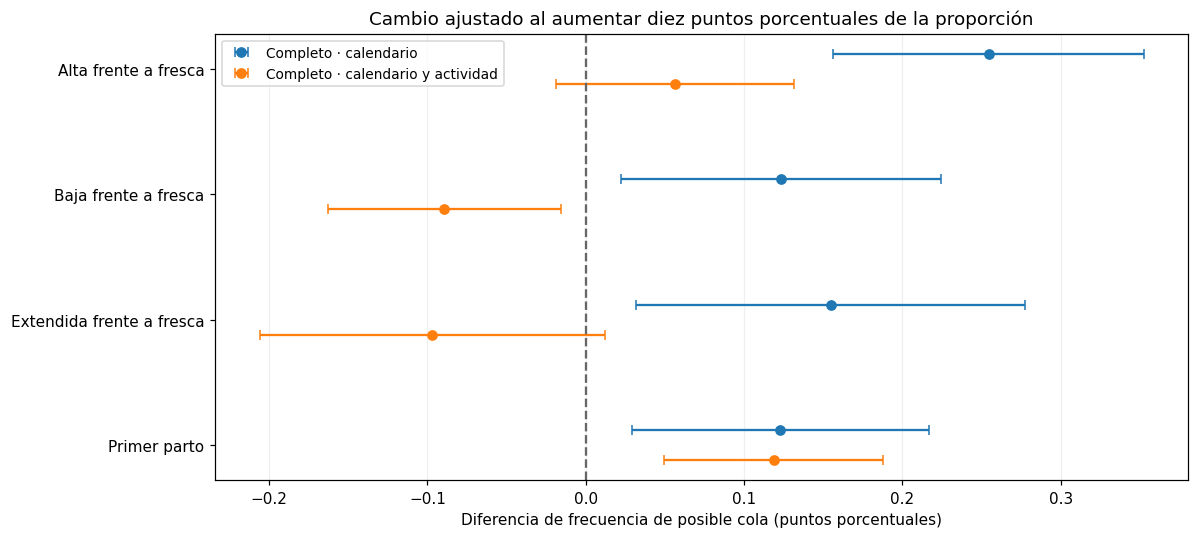

In [ ]:
def lactancia_graficar_cambios_ajustados(estado):
    VARIABLES = estado["VARIABLES"]
    cambios_completos = estado["cambios_completos"]
    fig, ax = plt.subplots(figsize=(11, 5))
    for desplazamiento, (nombre, grupo) in zip(
        [-0.12, 0.12], cambios_completos.groupby("Modelo", sort=False)
    ):
        grupo = grupo.set_index("Variable").loc[list(VARIABLES)].reset_index()
        y = np.arange(len(grupo)) + desplazamiento
        centro = grupo["Cambio_frecuencia_pp"].to_numpy()
        intervalos = np.vstack([centro - grupo["IC_inferior_pp"], grupo["IC_superior_pp"] - centro])
        ax.errorbar(centro, y, xerr=intervalos, fmt="o", capsize=3, label=nombre)
    ax.axvline(0, color="0.4", linestyle="--")
    ax.set_yticks(range(len(VARIABLES)), list(VARIABLES.values()))
    ax.invert_yaxis()
    ax.set(
        title="Cambio ajustado al aumentar diez puntos porcentuales de la proporción",
        xlabel="Diferencia de frecuencia de posible cola (puntos porcentuales)",
    )
    ax.legend(loc="best", fontsize=9)
    ax.grid(axis="x", alpha=0.2)
    fig.tight_layout()
    return fig


fig = lactancia_graficar_cambios_ajustados(lactancia)
plt.show()
plt.close(fig)

Las diferencias por etapa se acercan a cero al considerar actividad. La asociación observada depende de la especificación y no basta para proponer un efecto biológico general.

### 4.5 Estabilidad entre periodos

Reestimamos la misma especificación en cada periodo y revisamos dirección e incertidumbre.
Como cada periodo se ajusta por separado, esta sección no mide desempeño predictivo fuera de muestra.

Reestima las asociaciones por periodo, con y sin actividad, para revisar estabilidad histórica.

In [ ]:
def lactancia_ajustar_por_periodo(estado):
    PERIODOS = estado["PERIODOS"]
    muestra = estado["muestra"]
    coef_periodos = []
    for periodo in PERIODOS:
        tabla = muestra.loc[muestra["Periodo"].eq(periodo)].copy()
        for actividad in [False, True]:
            nombre = periodo + (" · calendario y actividad" if actividad else " · calendario")
            resultado, coef = lactancia_ajustar(estado, tabla, nombre, actividad=actividad)
            coef["Periodo"] = periodo
            coef["Ajuste_actividad"] = actividad
            coef_periodos.append(coef)
            del resultado
            gc.collect()
    estabilidad_periodos = pd.concat(coef_periodos, ignore_index=True)
    return {"estabilidad_periodos": estabilidad_periodos}


lactancia.update(lactancia_ajustar_por_periodo(lactancia))

Muestra la dirección, magnitud e incertidumbre de las asociaciones en cada periodo.

In [ ]:
display(
    lactancia["estabilidad_periodos"][
        [
            "Periodo",
            "Ajuste_actividad",
            "Comparacion",
            "OR_10pp",
            "OR_IC_inf",
            "OR_IC_sup",
            "p_Holm",
        ]
    ]
)

,Periodo,Ajuste_actividad,Comparacion,OR_10pp,OR_IC_inf,OR_IC_sup,p_Holm
0,Entrenamiento,False,Alta frente a fresca,1.008,1.001,1.014,0.04857
1,Entrenamiento,False,Baja frente a fresca,0.9932,0.9874,0.999,0.04857
2,Entrenamiento,False,Extendida frente a fresca,1.003,0.9944,1.011,0.5301
3,Entrenamiento,False,Primer parto,1.011,1.005,1.016,0.0007174
4,Entrenamiento,True,Alta frente a fresca,1.002,0.9943,1.009,0.6344
5,Entrenamiento,True,Baja frente a fresca,0.984,0.9766,0.9915,0.0001393
6,Entrenamiento,True,Extendida frente a fresca,0.9855,0.9734,0.9977,0.04074
7,Entrenamiento,True,Primer parto,1.018,1.011,1.025,3.933e-06
8,Validación,False,Alta frente a fresca,1.017,1.007,1.028,0.006799
9,Validación,False,Baja frente a fresca,1.021,1.01,1.033,0.00235


Los coeficientes y su respaldo varían entre periodos, especialmente con actividad. Se revisa estabilidad antes de interpretar una asociación histórica como condición recurrente.

Resume si cada asociación mantiene dirección y respaldo estadístico en los tres periodos.

In [ ]:
def lactancia_preparar_estabilidad_periodos(estado):
    VARIABLES = estado["VARIABLES"]
    estabilidad_periodos = estado["estabilidad_periodos"]
    filas_estabilidad = []
    for (variable, actividad), grupo in estabilidad_periodos.groupby(
        ["Variable", "Ajuste_actividad"]
    ):
        signo = np.sign(grupo["Coeficiente"])
        filas_estabilidad.append(
            {
                "Comparacion": VARIABLES[variable],
                "Variable": variable,
                "Ajuste_actividad": actividad,
                "Periodos_OR_mayor_1": int(grupo["OR_10pp"].gt(1).sum()),
                "Periodos_OR_menor_1": int(grupo["OR_10pp"].lt(1).sum()),
                "Misma_direccion_tres_periodos": bool(signo.nunique() == 1),
                "Periodos_respaldo_Holm": int(grupo["Respaldo_Holm"].sum()),
            }
        )
    consistencia = pd.DataFrame(filas_estabilidad)
    return {"consistencia": consistencia}


lactancia.update(lactancia_preparar_estabilidad_periodos(lactancia))

Grafica los OR por periodo; la referencia de ausencia de asociación es OR = 1.

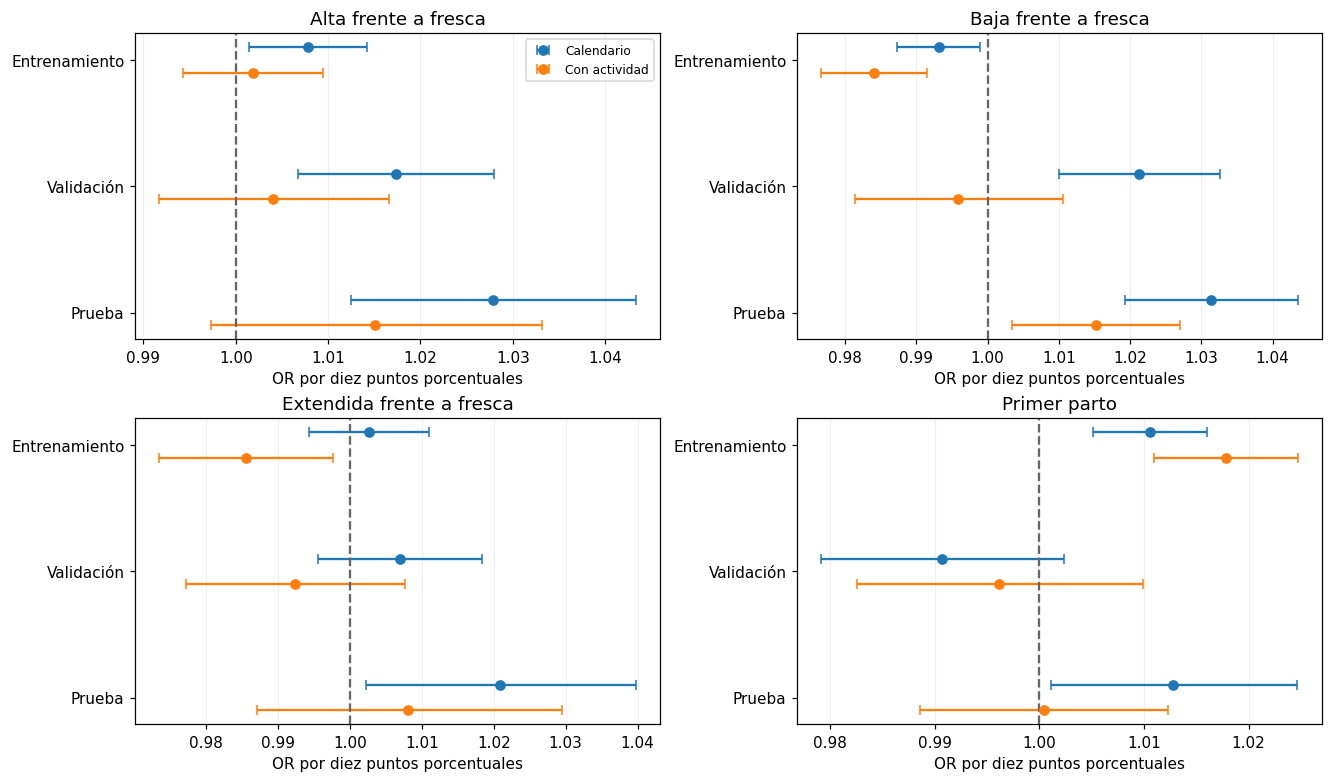

In [ ]:
def lactancia_graficar_estabilidad_periodos(estado):
    PERIODOS = estado["PERIODOS"]
    VARIABLES = estado["VARIABLES"]
    estabilidad_periodos = estado["estabilidad_periodos"]
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
    for ax, variable in zip(axes.flat, VARIABLES):
        for actividad, desplazamiento in [(False, -0.1), (True, 0.1)]:
            grupo = estabilidad_periodos.loc[
                estabilidad_periodos["Variable"].eq(variable)
                & estabilidad_periodos["Ajuste_actividad"].eq(actividad)
            ]
            grupo = grupo.set_index("Periodo").loc[PERIODOS]
            centro = grupo["OR_10pp"].to_numpy()
            limites = np.vstack([centro - grupo["OR_IC_inf"], grupo["OR_IC_sup"] - centro])
            ax.errorbar(
                centro,
                np.arange(3) + desplazamiento,
                xerr=limites,
                fmt="o",
                capsize=3,
                label="Con actividad" if actividad else "Calendario",
            )
        ax.axvline(1, color="0.4", linestyle="--")
        ax.set_yticks(range(3), PERIODOS)
        ax.invert_yaxis()
        ax.set(title=VARIABLES[variable], xlabel="OR por diez puntos porcentuales")
        ax.grid(axis="x", alpha=0.2)
    axes[0, 0].legend(fontsize=8)
    return fig


fig = lactancia_graficar_estabilidad_periodos(lactancia)
plt.show()
plt.close(fig)

Varios intervalos cruzan OR = 1 y algunas direcciones cambian al incluir actividad. Se evita concluir estabilidad solo porque un ajuste aislado sea significativo.

Muestra cuántos periodos respaldan cada variable y si su dirección permanece estable.

In [ ]:
display(lactancia["consistencia"])

,Comparacion,Variable,Ajuste_actividad,Periodos_OR_mayor_1,Periodos_OR_menor_1,Misma_direccion_tres_periodos,Periodos_respaldo_Holm
0,Alta frente a fresca,alta_10pp,False,3,0,True,3
1,Alta frente a fresca,alta_10pp,True,3,0,True,0
2,Baja frente a fresca,baja_10pp,False,2,1,False,3
3,Baja frente a fresca,baja_10pp,True,1,2,False,1
4,Extendida frente a fresca,extendida_10pp,False,3,0,True,0
5,Extendida frente a fresca,extendida_10pp,True,1,2,False,1
6,Primer parto,primer_parto_10pp,False,2,1,False,1
7,Primer parto,primer_parto_10pp,True,2,1,False,1


Alta mantiene signo positivo con actividad, pero no tiene respaldo de Holm en ninguno de los tres periodos. La dirección repetida, por sí sola, no demuestra una asociación estable.

### 4.6 Asociaciones por robot

Ajusta las regresiones por robot para identificar relaciones que el resumen conjunto puede ocultar.

In [ ]:
def lactancia_ajustar_por_robot(estado):
    muestra = estado["muestra"]
    robots = estado["robots"]
    coef_robot = []
    for robot in robots:
        tabla = muestra.loc[muestra["ms"].eq(robot)].copy()
        for actividad in [False, True]:
            nombre = robot + (" · calendario y actividad" if actividad else " · calendario")
            resultado, coef = lactancia_ajustar(estado, tabla, nombre, actividad=actividad)
            coef["Robot"] = robot
            coef["Ajuste_actividad"] = actividad
            coef_robot.append(coef)
            del resultado
            gc.collect()
    asociaciones_robot = pd.concat(coef_robot, ignore_index=True)
    return {"asociaciones_robot": asociaciones_robot}


lactancia.update(lactancia_ajustar_por_robot(lactancia))

Muestra los OR y valores p corregidos de las asociaciones específicas de cada robot.

In [ ]:
display(
    lactancia["asociaciones_robot"][
        ["Robot", "Ajuste_actividad", "Comparacion", "OR_10pp", "OR_IC_inf", "OR_IC_sup", "p_Holm"]
    ]
)

,Robot,Ajuste_actividad,Comparacion,OR_10pp,OR_IC_inf,OR_IC_sup,p_Holm
0,VMS 1,False,Alta frente a fresca,1.008,0.9995,1.016,0.2013
1,VMS 1,False,Baja frente a fresca,1.008,0.9973,1.018,0.294
2,VMS 1,False,Extendida frente a fresca,1.009,0.9966,1.021,0.294
3,VMS 1,False,Primer parto,1.01,1.003,1.016,0.02132
4,VMS 1,True,Alta frente a fresca,0.9971,0.9874,1.007,0.9982
5,VMS 1,True,Baja frente a fresca,0.9936,0.9808,1.007,0.9982
6,VMS 1,True,Extendida frente a fresca,0.9939,0.9786,1.009,0.9982
7,VMS 1,True,Primer parto,1.013,1.004,1.022,0.01886
8,VMS 2,False,Alta frente a fresca,0.9979,0.99,1.006,1
9,VMS 2,False,Baja frente a fresca,1,0.9915,1.009,1


Alta se asocia positivamente en VMS 3, mientras en VMS 2 la asociación ajustada es negativa. Se priorizan conclusiones por robot y se evita una regla única para el rancho.

Grafica las asociaciones por robot y el cambio que produce añadir actividad a los controles.

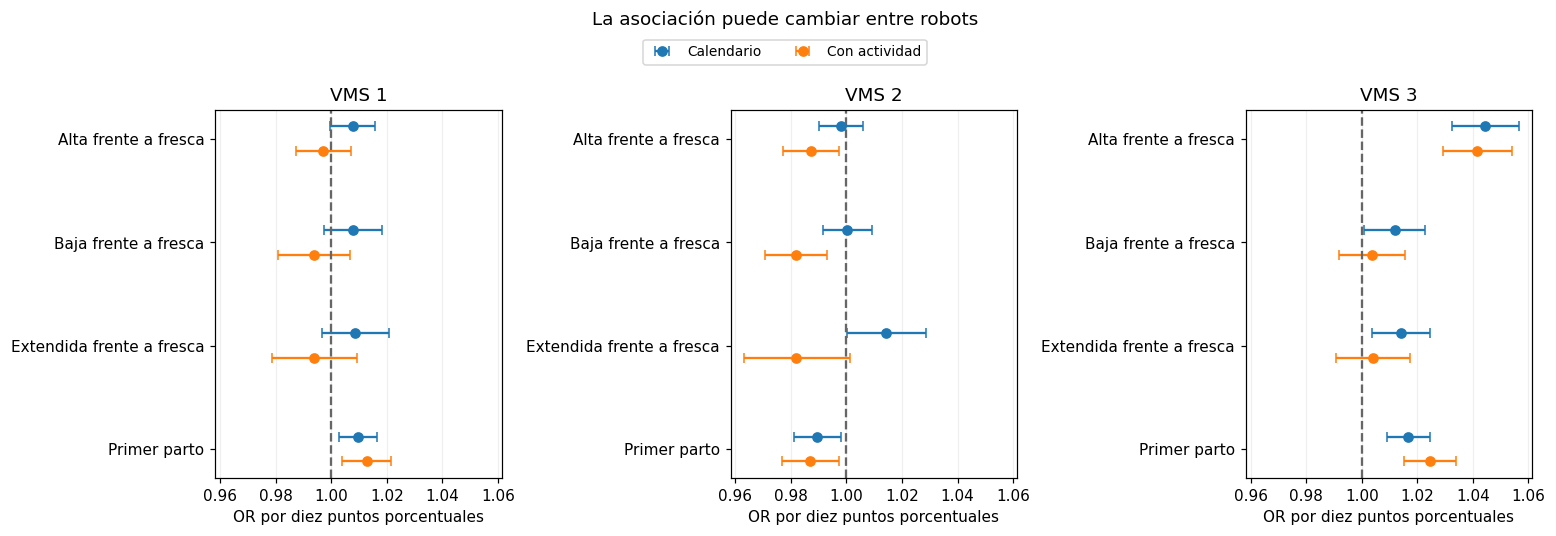

In [ ]:
def lactancia_graficar_asociaciones_por_robot(estado):
    VARIABLES = estado["VARIABLES"]
    asociaciones_robot = estado["asociaciones_robot"]
    robots = estado["robots"]
    fig, axes = plt.subplots(1, len(robots), figsize=(14, 5), sharex=True)
    for ax, robot in zip(np.atleast_1d(axes), robots):
        for actividad, desplazamiento in [(False, -0.12), (True, 0.12)]:
            grupo = asociaciones_robot.loc[
                asociaciones_robot["Robot"].eq(robot)
                & asociaciones_robot["Ajuste_actividad"].eq(actividad)
            ]
            grupo = grupo.set_index("Variable").loc[list(VARIABLES)]
            centro = grupo["OR_10pp"].to_numpy()
            limites = np.vstack([centro - grupo["OR_IC_inf"], grupo["OR_IC_sup"] - centro])
            ax.errorbar(
                centro,
                np.arange(len(VARIABLES)) + desplazamiento,
                xerr=limites,
                fmt="o",
                capsize=3,
                label="Con actividad" if actividad else "Calendario",
            )
        ax.axvline(1, color="0.4", linestyle="--")
        ax.set_yticks(range(len(VARIABLES)), list(VARIABLES.values()))
        ax.invert_yaxis()
        ax.set(title=robot, xlabel="OR por diez puntos porcentuales")
        ax.grid(axis="x", alpha=0.2)
    handles, etiquetas = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, etiquetas, loc="upper center", bbox_to_anchor=(0.5, 0.94), ncol=2, fontsize=9
    )
    fig.suptitle("La asociación puede cambiar entre robots")
    fig.subplots_adjust(left=0.13, right=0.985, bottom=0.13, top=0.8, wspace=0.8)
    return fig


fig = lactancia_graficar_asociaciones_por_robot(lactancia)
plt.show()
plt.close(fig)

Las asociaciones difieren entre máquinas y varias se debilitan al incluir actividad. VMS 3 conserva el vínculo positivo con alta; el agregado oculta esta heterogeneidad.

### 4.7 Relación con el indicador continuo

La regresión lineal complementaria usa pct_posible_cola como respuesta.
Los coeficientes expresan cambios del indicador agregado, no probabilidades de una vaca individual.

Ajusta regresiones al indicador continuo como complemento de la respuesta binaria.

In [ ]:
def lactancia_ajustar_indicador_continuo(estado):
    muestra = estado["muestra"]
    coef_lineales = []
    for actividad in [False, True]:
        nombre = "Indicador · calendario" + (" y actividad" if actividad else "")
        resultado, coef = lactancia_ajustar(
            estado, muestra, nombre, respuesta="pct_posible_cola", actividad=actividad
        )
        coef_lineales.append(coef)
        del resultado
        gc.collect()
    asociaciones_indicador = pd.concat(coef_lineales, ignore_index=True)
    return {"asociaciones_indicador": asociaciones_indicador}


lactancia.update(lactancia_ajustar_indicador_continuo(lactancia))

Muestra los cambios del indicador continuo, sus intervalos y valores p corregidos.

In [ ]:
display(
    lactancia["asociaciones_indicador"][
        [
            "Modelo",
            "Comparacion",
            "Cambio_indicador_pp",
            "Cambio_IC_inf_pp",
            "Cambio_IC_sup_pp",
            "p_Holm",
        ]
    ]
)

,Modelo,Comparacion,Cambio_indicador_pp,Cambio_IC_inf_pp,Cambio_IC_sup_pp,p_Holm
0,Indicador · calendario,Alta frente a fresca,0.2001,0.1138,0.2863,3.539e-05
1,Indicador · calendario,Baja frente a fresca,0.05329,-0.0367,0.1433,0.4882
2,Indicador · calendario,Extendida frente a fresca,0.03909,-0.07012,0.1483,0.4882
3,Indicador · calendario,Primer parto,0.1353,0.05891,0.2117,0.001796
4,Indicador · calendario y actividad,Alta frente a fresca,0.05432,-0.01893,0.1276,0.1451
5,Indicador · calendario y actividad,Baja frente a fresca,-0.09986,-0.169,-0.03068,0.01473
6,Indicador · calendario y actividad,Extendida frente a fresca,-0.1038,-0.1992,-0.008388,0.06631
7,Indicador · calendario y actividad,Primer parto,0.1224,0.06137,0.1833,0.0004358


Con actividad, alta no tiene respaldo corregido en el indicador continuo y baja se asocia con una reducción pequeña. La lectura tampoco respalda una etapa universalmente dominante.

### 4.8 Resumen de ajustes

Convierte el registro de regresiones en una tabla para comprobar sus ajustes.

In [ ]:
lactancia["log_ajustes"] = pd.DataFrame(lactancia["registro"])

Muestra muestra, semanas, parámetros y convergencia de las dieciséis regresiones.

In [ ]:
display(
    lactancia["log_ajustes"][
        ["Modelo", "Bloques", "Semanas", "Parametros", "Convergio", "Segundos"]
    ]
)

,Modelo,Bloques,Semanas,Parametros,Convergio,Segundos
0,Completo · calendario,123040,177,272,True,20.06
1,Completo · calendario y actividad,123040,177,275,True,21.51
2,Entrenamiento · calendario,76014,123,236,True,10.25
3,Entrenamiento · calendario y actividad,76014,123,239,True,11.01
4,Validación · calendario,23140,28,172,True,1.247
5,Validación · calendario y actividad,23140,28,175,True,1.454
6,Prueba · calendario,23886,28,172,True,1.569
7,Prueba · calendario y actividad,23886,28,175,True,1.885
8,VMS 1 · calendario,41752,173,97,True,1.924
9,VMS 1 · calendario y actividad,41752,173,100,True,1.881


Convergen los dieciséis ajustes, incluidos los análisis por periodo y robot. Esto permite interpretarlos numéricamente, pero no demuestra causalidad ni capacidad predictiva fuera de muestra.

Se analizaron 123,040 bloques con ordeños y etapa conocida.
La asociación con lactancia cambia entre robots y al considerar la actividad; no aparece una etapa universal.

## 5. Minutos desde alimento y posible cola

Revisamos cinco franjas en cada combinación de robot y horario de alimentación: 30 combinaciones en total.
Los horarios considerados son 07:30 y 14:30; la madrugada pertenece al ciclo de la tarde anterior.

### 5.1 Configuración y comprobación de los horarios

Configura horarios programados, franjas, ventanas de comparación y nivel de significancia para alimentación.

In [ ]:
alimento = iniciar_analisis(base, calendario)
alimento.update(
    {
        "ALFA": 0.05,
        "CICLOS": ["Mañana · 07:30", "Tarde · 14:30"],
        "FRANJAS": ["0–<30 min", "30–<60 min", "60–<120 min", "120–<240 min", "240 min o más"],
        "PERIODOS": ["Entrenamiento", "Validación", "Prueba"],
        "MUESTRAS": ["Todos los bloques", "Solo con ordeños"],
        "CONTRASTES": {
            "Primeras 4 h vs. resto del ciclo": {"corte": 240, "limite": None},
            "Primera hora vs. siguientes 3 h": {"corte": 60, "limite": 240},
        },
        "COLORES": {"Mañana · 07:30": "#087f8c", "Tarde · 14:30": "#e38b2c"},
    }
)

Revisa continuidad y disponibilidad de la variable de alimento sin retirar los bloques sin ordeños.

In [ ]:
def alimento_validar_datos(estado):
    UMBRAL_REAL = estado["UMBRAL_REAL"]
    datos = estado["datos"]
    necesarias = ["ms", "bloque_tiempo", "min_desde_alimento", "pct_posible_cola", "hubo_ordenios"]
    if not set(necesarias).issubset(datos.columns):
        raise ValueError("Faltan columnas necesarias para el análisis.")
    datos = datos[necesarias].copy()
    datos["bloque_tiempo"] = pd.to_datetime(datos["bloque_tiempo"])
    datos = datos.sort_values(["bloque_tiempo", "ms"]).reset_index(drop=True)
    if datos[necesarias].isna().any().any():
        raise ValueError("Hay valores faltantes en las columnas necesarias.")
    if datos.duplicated(["ms", "bloque_tiempo"]).any():
        raise ValueError("Hay bloques duplicados por robot.")
    if not datos["pct_posible_cola"].between(0, 1).all():
        raise ValueError("El indicador debe estar entre 0 y 1.")
    if not datos["hubo_ordenios"].isin([0, 1]).all():
        raise ValueError("Revisa la variable hubo_ordenios.")
    pasos = datos.groupby("ms")["bloque_tiempo"].diff().dropna()
    if not pasos.eq(pd.Timedelta(minutes=30)).all():
        raise ValueError("Existen huecos internos o una frecuencia distinta de 30 minutos.")
    datos["cola"] = datos["pct_posible_cola"].gt(UMBRAL_REAL).astype(int)
    ROBOTS = sorted(datos["ms"].unique())
    auditoria = datos.groupby("ms").agg(
        Bloques=("cola", "size"),
        Inicio=("bloque_tiempo", "min"),
        Fin=("bloque_tiempo", "max"),
        Positivos=("cola", "sum"),
        Bloques_con_ordenios=("hubo_ordenios", "sum"),
    )
    auditoria["Posible_cola_pct"] = 100 * auditoria["Positivos"] / auditoria["Bloques"]
    return {"datos": datos, "ROBOTS": ROBOTS, "auditoria": auditoria}


alimento.update(alimento_validar_datos(alimento))

Muestra cobertura, actividad y frecuencia histórica de posible cola por robot.

In [ ]:
display(alimento["auditoria"].reset_index())

,ms,Bloques,Inicio,Fin,Positivos,Bloques_con_ordenios,Posible_cola_pct
0,VMS 1,59950,2022-08-01 01:00:00,2025-12-31 23:30:00,16888,44975,28.17
1,VMS 2,59948,2022-08-01 02:00:00,2025-12-31 23:30:00,14897,43171,24.85
2,VMS 3,59952,2022-08-01 00:00:00,2025-12-31 23:30:00,13669,43912,22.8


VMS 1 tiene mayor frecuencia histórica que VMS 3 y también difiere su actividad. Se conservan comparaciones por robot para no confundir estos niveles con el tiempo desde alimento.

Comprueba los minutos contra los horarios 07:30/14:30 y asigna ciclo y fecha de alimentación programada.

In [ ]:
def alimento_verificar_horarios(estado):
    CICLOS = estado["CICLOS"]
    FRANJAS = estado["FRANJAS"]
    datos = estado["datos"]
    datos["minuto_dia"] = datos["bloque_tiempo"].dt.hour * 60 + datos["bloque_tiempo"].dt.minute
    minuto = datos["minuto_dia"]
    esperados = np.where(
        minuto >= 870, minuto - 870, np.where(minuto >= 450, minuto - 450, minuto + 570)
    )
    desacuerdos = int((datos["min_desde_alimento"] != esperados).sum())
    if desacuerdos:
        raise ValueError(
            "La variable no coincide con el horario fijo. Revisa los horarios antes de continuar."
        )
    datos["ciclo"] = np.where(minuto.between(450, 869), CICLOS[0], CICLOS[1])
    datos["fecha_alimento"] = datos["bloque_tiempo"] - pd.to_timedelta(
        datos["min_desde_alimento"], unit="m"
    )
    datos["dia_evento"] = datos["fecha_alimento"].dt.normalize()
    datos["mes_evento"] = datos["fecha_alimento"].dt.to_period("M").astype(str)
    datos["franja"] = pd.cut(
        datos["min_desde_alimento"], [0, 30, 60, 120, 240, np.inf], labels=FRANJAS, right=False
    )
    datos["hora_reloj"] = datos["bloque_tiempo"].dt.strftime("%H:%M")
    mapa = (
        datos[["hora_reloj", "min_desde_alimento", "ciclo", "franja"]]
        .drop_duplicates()
        .sort_values("hora_reloj")
    )
    if len(mapa) != 48 or mapa.groupby("hora_reloj")["min_desde_alimento"].nunique().max() != 1:
        raise ValueError("La relación con la hora no es la esperada.")
    return {"datos": datos, "mapa": mapa}


alimento.update(alimento_verificar_horarios(alimento))

Muestra la correspondencia entre hora del reloj, minutos transcurridos y ciclo programado.

In [ ]:
display(alimento["mapa"].reset_index(drop=True))

,hora_reloj,min_desde_alimento,ciclo,franja
0,00:00,570,Tarde · 14:30,240 min o más
1,00:30,600,Tarde · 14:30,240 min o más
2,01:00,630,Tarde · 14:30,240 min o más
3,01:30,660,Tarde · 14:30,240 min o más
4,02:00,690,Tarde · 14:30,240 min o más
5,02:30,720,Tarde · 14:30,240 min o más
6,03:00,750,Tarde · 14:30,240 min o más
7,03:30,780,Tarde · 14:30,240 min o más
8,04:00,810,Tarde · 14:30,240 min o más
9,04:30,840,Tarde · 14:30,240 min o más


Cada hora del reloj tiene un único valor de minutos desde alimento. Esta variable representa el mismo calendario y no permite aislar un efecto propio de la entrega real.

Los minutos coinciden exactamente con el horario del reloj: aquí no permiten aislar un efecto propio del alimento.
El ciclo matutino dura siete horas y el vespertino diecisiete; no se dispone de una hora real de entrega independiente.

Aplica los cortes cronológicos compartidos al análisis de alimento y resume sus periodos.

In [ ]:
def alimento_asignar_periodos(estado):
    INICIO_TEST = estado["INICIO_TEST"]
    INICIO_VAL = estado["INICIO_VAL"]
    PERIODOS = estado["PERIODOS"]
    datos = estado["datos"]
    corte_validacion = INICIO_VAL
    corte_prueba = INICIO_TEST
    datos["periodo"] = np.select(
        [datos["bloque_tiempo"] < corte_validacion, datos["bloque_tiempo"] < corte_prueba],
        PERIODOS[:2],
        default=PERIODOS[2],
    )
    particiones = (
        datos.groupby("periodo")
        .agg(
            Bloques=("cola", "size"),
            Inicio=("bloque_tiempo", "min"),
            Fin=("bloque_tiempo", "max"),
            Posible_cola_pct=("cola", lambda x: 100 * x.mean()),
        )
        .reindex(PERIODOS)
    )
    return {"datos": datos, "particiones": particiones}


alimento.update(alimento_asignar_periodos(alimento))

Muestra la cobertura y frecuencia por periodo del análisis con todos los bloques.

In [ ]:
display(alimento["particiones"].reset_index())

,periodo,Bloques,Inicio,Fin,Posible_cola_pct
0,Entrenamiento,125892,2022-08-01 00:00:00,2024-12-22 06:30:00,14.66
1,Validación,26979,2024-12-22 07:00:00,2025-06-27 15:00:00,42.54
2,Prueba,26979,2025-06-27 15:30:00,2025-12-31 23:30:00,57.53


Los cortes y tamaños coinciden con los de los modelos temporales. Se mantiene una referencia común, aunque el estudio de alimento es explicativo y retrospectivo.

### 5.2 Frecuencias por franja y curvas completas

Usamos porcentajes y conteos porque las franjas tienen duraciones diferentes.
La franja de 240 minutos o más cubre tres horas por la mañana y trece por la tarde.

Define tasas y soporte por grupo para comparar franjas de duración diferente.

In [ ]:
def alimento_resumir(estado, base, claves):
    tabla = (
        base.groupby(claves, observed=True)
        .agg(
            bloques=("cola", "size"),
            positivos=("cola", "sum"),
            ciclos_diarios=("fecha_alimento", "nunique"),
            actividad_pct=("hubo_ordenios", lambda x: 100 * x.mean()),
        )
        .reset_index()
    )
    tabla["posible_cola_pct"] = 100 * tabla["positivos"] / tabla["bloques"]
    return tabla

Calcula tasas por franja, robot, ciclo y periodo, tanto con todos los bloques como con solo actividad.

In [ ]:
def alimento_calcular_tasas(estado):
    MUESTRAS = estado["MUESTRAS"]
    PERIODOS = estado["PERIODOS"]
    datos = estado["datos"]
    tablas_franjas = []
    for muestra in MUESTRAS:
        base = datos if muestra == MUESTRAS[0] else datos.loc[datos["hubo_ordenios"].eq(1)]
        for periodo in ["Histórico completo", *PERIODOS]:
            sub = base if periodo == "Histórico completo" else base.loc[base["periodo"].eq(periodo)]
            tabla = alimento_resumir(estado, sub, ["ms", "ciclo", "franja"])
            tabla["muestra"], tabla["periodo"] = (muestra, periodo)
            tablas_franjas.append(tabla)
    tasas_franjas = pd.concat(tablas_franjas, ignore_index=True)
    historico = tasas_franjas.loc[
        tasas_franjas["muestra"].eq(MUESTRAS[0]) & tasas_franjas["periodo"].eq("Histórico completo")
    ]
    return {"tasas_franjas": tasas_franjas, "historico": historico}


alimento.update(alimento_calcular_tasas(alimento))

Muestra las frecuencias históricas de las cinco franjas en cada robot y ciclo.

In [ ]:
display(
    alimento["historico"]
    .pivot(index=["ms", "ciclo"], columns="franja", values="posible_cola_pct")
    .reindex(columns=alimento["FRANJAS"])
)

franja                0–<30 min  30–<60 min  60–<120 min  120–<240 min  \
ms    ciclo                                                              
VMS 1 Mañana · 07:30      33.31       35.63        35.79         31.95   
      Tarde · 14:30       29.22       32.75        33.27         34.11   
VMS 2 Mañana · 07:30      31.63       30.82        31.22            29   
      Tarde · 14:30       26.58       29.06        30.78         30.02   
VMS 3 Mañana · 07:30      26.66       27.94        28.38          26.2   
      Tarde · 14:30        24.5       28.58        25.78         28.12   

franja                240 min o más  
ms    ciclo                          
VMS 1 Mañana · 07:30          22.68  
      Tarde · 14:30           26.26  
VMS 2 Mañana · 07:30          20.07  
      Tarde · 14:30           22.85  
VMS 3 Mañana · 07:30          18.49  
      Tarde · 14:30           21.16

Las franjas de las primeras cuatro horas suelen superar la franja posterior en ambos ciclos. El máximo no aparece siempre inmediatamente al comenzar el horario de alimento.

Muestra cuántos bloques, ciclos diarios y actividad aportan las franjas comparadas.

In [ ]:
display(
    alimento["historico"][["ms", "ciclo", "franja", "bloques", "ciclos_diarios", "actividad_pct"]]
)

,ms,ciclo,franja,bloques,ciclos_diarios,actividad_pct
0,VMS 1,Mañana · 07:30,0–<30 min,1249,1249,83.19
1,VMS 1,Mañana · 07:30,30–<60 min,1249,1249,84.63
2,VMS 1,Mañana · 07:30,60–<120 min,2498,1249,85.11
3,VMS 1,Mañana · 07:30,120–<240 min,4996,1249,81.89
4,VMS 1,Mañana · 07:30,240 min o más,7494,1249,65.81
5,VMS 1,Tarde · 14:30,0–<30 min,1249,1249,72.86
6,VMS 1,Tarde · 14:30,30–<60 min,1249,1249,83.83
7,VMS 1,Tarde · 14:30,60–<120 min,2498,1249,82.79
8,VMS 1,Tarde · 14:30,120–<240 min,4996,1249,85.45
9,VMS 1,Tarde · 14:30,240 min o más,32472,1250,72.17


Las franjas aportan cantidades distintas de bloques, sobre todo la nocturna del ciclo de tarde. Se comparan tasas y soporte, no conteos acumulados como si duraran lo mismo.

Calcula las tasas cada treinta minutos y las vincula con su hora del reloj.

In [ ]:
def alimento_preparar_curvas_cada_30_minutos(estado):
    CICLOS = estado["CICLOS"]
    datos = estado["datos"]
    curvas = alimento_resumir(estado, datos, ["ms", "ciclo", "min_desde_alimento"])
    minuto_curva = np.where(curvas["ciclo"].eq(CICLOS[0]), 450, 870) + curvas[
        "min_desde_alimento"
    ].astype(int)
    curvas["hora_reloj"] = [f"{m // 60 % 24:02d}:{m % 60:02d}" for m in minuto_curva]
    return {"curvas": curvas}


alimento.update(alimento_preparar_curvas_cada_30_minutos(alimento))

Grafica las curvas completas desde ambos horarios programados para detectar concentraciones y repuntes.

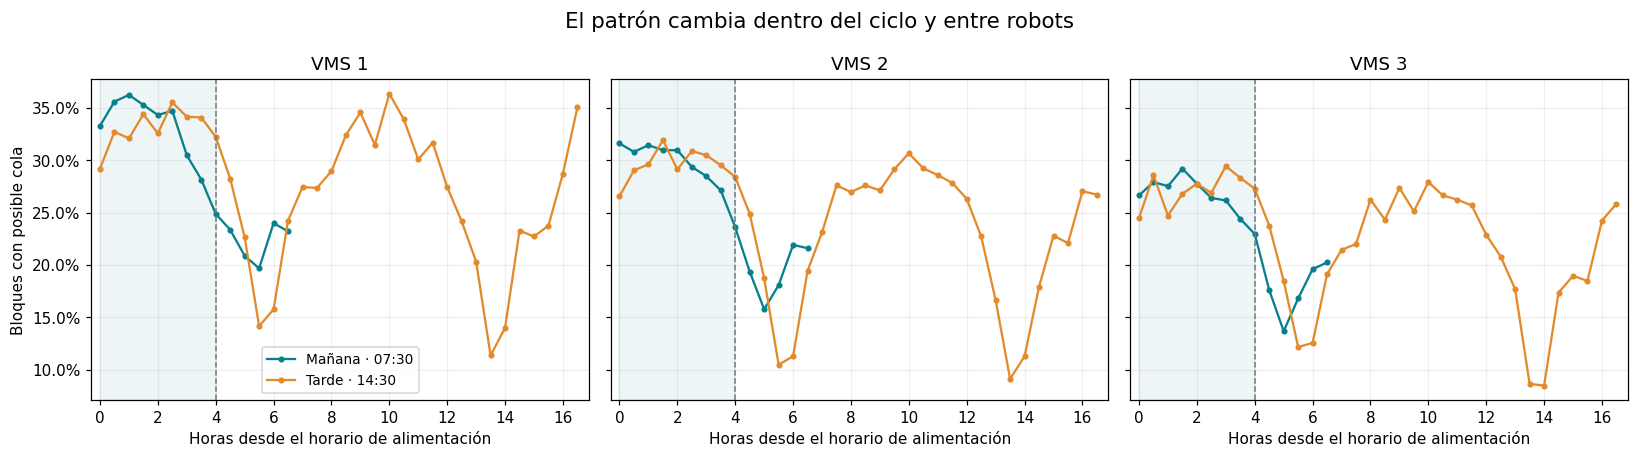

In [ ]:
def alimento_graficar_curvas_cada_30_minutos(estado):
    CICLOS = estado["CICLOS"]
    COLORES = estado["COLORES"]
    ROBOTS = estado["ROBOTS"]
    curvas = estado["curvas"]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
    for ax, robot in zip(axes, ROBOTS):
        for ciclo in CICLOS:
            curva = curvas.loc[curvas["ms"].eq(robot) & curvas["ciclo"].eq(ciclo)]
            ax.plot(
                curva["min_desde_alimento"] / 60,
                curva["posible_cola_pct"],
                marker="o",
                markersize=3,
                color=COLORES[ciclo],
                label=ciclo,
            )
        ax.axvspan(0, 4, alpha=0.07, color="#087f8c")
        ax.axvline(4, color="#777777", ls="--", lw=1)
        ax.set(title=robot, xlabel="Horas desde el horario de alimentación", xlim=(-0.3, 16.9))
        ax.set_xticks(range(0, 17, 2))
        ax.yaxis.set_major_formatter(PercentFormatter(100))
        ax.grid(alpha=0.2)
    axes[0].set_ylabel("Bloques con posible cola")
    axes[0].legend(fontsize=9)
    fig.suptitle("El patrón cambia dentro del ciclo y entre robots", fontsize=14)
    fig.tight_layout()
    return fig


fig = alimento_graficar_curvas_cada_30_minutos(alimento)
plt.show()
plt.close(fig)

Las curvas presentan elevación inicial y repuntes nocturnos. Se estudia una concentración de varias horas y se evita reducir el patrón a un efecto inmediato del alimento.

### 5.3 Recurrencia mensual de todas las franjas

La base corresponde al mismo robot, ciclo y mes. Exigimos al menos 20 ciclos diarios por mes.
La recurrencia usa las mismas reglas de mayoría en entrenamiento y dos tercios en validación.

Evalúa recurrencia mensual de las treinta combinaciones frente a la base de cada robot y ciclo.

In [ ]:
def alimento_evaluar_recurrencia(estado):
    CICLOS = estado["CICLOS"]
    FRANJAS = estado["FRANJAS"]
    PERIODOS = estado["PERIODOS"]
    ROBOTS = estado["ROBOTS"]
    datos = estado["datos"]
    mensuales = alimento_resumir(estado, datos, ["periodo", "mes_evento", "ms", "ciclo", "franja"])
    bases_mes = alimento_resumir(estado, datos, ["periodo", "mes_evento", "ms", "ciclo"])
    bases_mes = bases_mes[["periodo", "mes_evento", "ms", "ciclo", "posible_cola_pct"]].rename(
        columns={"posible_cola_pct": "base_ciclo_pct"}
    )
    mensuales = mensuales.merge(
        bases_mes, on=["periodo", "mes_evento", "ms", "ciclo"], validate="many_to_one"
    )
    mensuales["diferencia_pp"] = mensuales["posible_cola_pct"] - mensuales["base_ciclo_pct"]
    mensuales["razon_tasas"] = mensuales["posible_cola_pct"] / mensuales["base_ciclo_pct"].replace(
        0, np.nan
    )
    mensuales["evaluable"] = mensuales["ciclos_diarios"].ge(20) & mensuales["base_ciclo_pct"].gt(0)
    filas = []
    for (robot, ciclo, franja), grupo in mensuales.groupby(
        ["ms", "ciclo", "franja"], observed=True
    ):
        fila = {"ms": robot, "ciclo": ciclo, "franja": franja}
        for periodo, prefijo in zip(PERIODOS, ["train", "val", "test"]):
            sub = grupo.loc[grupo["periodo"].eq(periodo) & grupo["evaluable"]]
            fila[f"{prefijo}_meses"] = len(sub)
            fila[f"{prefijo}_meses_sobre_base"] = int(sub["diferencia_pp"].gt(0).sum())
            fila[f"{prefijo}_proporcion_sobre_base"] = (
                sub["diferencia_pp"].gt(0).mean() if len(sub) else np.nan
            )
            fila[f"{prefijo}_razon_mediana"] = sub["razon_tasas"].median()
            fila[f"{prefijo}_diferencia_mediana_pp"] = sub["diferencia_pp"].median()
        fila["candidata_train"] = (
            fila["train_meses"] >= 6
            and fila["train_proporcion_sobre_base"] > 0.5
            and (fila["train_razon_mediana"] > 1)
        )
        fila["recurrente_validacion"] = (
            fila["candidata_train"]
            and fila["val_meses"] >= 3
            and (fila["val_proporcion_sobre_base"] >= 2 / 3)
            and (fila["val_razon_mediana"] > 1)
        )
        filas.append(fila)
    recurrencia = pd.DataFrame(filas)
    rangos_horarios = {
        CICLOS[0]: ["07:30–08:00", "08:00–08:30", "08:30–09:30", "09:30–11:30", "11:30–14:30"],
        CICLOS[1]: [
            "14:30–15:00",
            "15:00–15:30",
            "15:30–16:30",
            "16:30–18:30",
            "18:30–07:30 del día siguiente",
        ],
    }
    recurrencia["horario_reloj"] = [
        rangos_horarios[c][FRANJAS.index(f)]
        for c, f in zip(recurrencia["ciclo"], recurrencia["franja"])
    ]
    assert len(recurrencia) == len(ROBOTS) * len(CICLOS) * len(FRANJAS)
    interesantes = recurrencia.loc[recurrencia["recurrente_validacion"]].copy()
    return {"filas": filas, "recurrencia": recurrencia, "interesantes": interesantes}


alimento.update(alimento_evaluar_recurrencia(alimento))

Muestra las treinta combinaciones, incluidas las que no cumplieron la regla de recurrencia.

In [ ]:
display(
    alimento["recurrencia"][
        ["ms", "ciclo", "franja", "horario_reloj", "candidata_train", "recurrente_validacion"]
    ]
)

,ms,ciclo,franja,horario_reloj,candidata_train,recurrente_validacion
0,VMS 1,Mañana · 07:30,0–<30 min,07:30–08:00,True,True
1,VMS 1,Mañana · 07:30,30–<60 min,08:00–08:30,True,True
2,VMS 1,Mañana · 07:30,60–<120 min,08:30–09:30,True,True
3,VMS 1,Mañana · 07:30,120–<240 min,09:30–11:30,True,True
4,VMS 1,Mañana · 07:30,240 min o más,11:30–14:30,False,False
5,VMS 1,Tarde · 14:30,0–<30 min,14:30–15:00,True,True
6,VMS 1,Tarde · 14:30,30–<60 min,15:00–15:30,True,True
7,VMS 1,Tarde · 14:30,60–<120 min,15:30–16:30,True,True
8,VMS 1,Tarde · 14:30,120–<240 min,16:30–18:30,True,True
9,VMS 1,Tarde · 14:30,240 min o más,18:30–07:30 del día siguiente,False,False


La tabla conserva las treinta combinaciones y las que no cumplen recurrencia. Esto evita presentar solo los horarios favorables y permite revisar excepciones.

Muestra todas las combinaciones recurrentes con sus horas y repetición entre periodos.

In [ ]:
display(
    alimento["interesantes"][
        [
            "ms",
            "ciclo",
            "franja",
            "horario_reloj",
            "train_meses_sobre_base",
            "train_meses",
            "val_meses_sobre_base",
            "val_meses",
            "val_diferencia_mediana_pp",
            "test_meses_sobre_base",
            "test_meses",
        ]
    ]
)

,ms,ciclo,franja,horario_reloj,train_meses_sobre_base,train_meses,val_meses_sobre_base,val_meses,val_diferencia_mediana_pp,test_meses_sobre_base,test_meses
0,VMS 1,Mañana · 07:30,0–<30 min,07:30–08:00,19,29,6,6,13.02,3,6
1,VMS 1,Mañana · 07:30,30–<60 min,08:00–08:30,19,29,6,6,12.39,6,6
2,VMS 1,Mañana · 07:30,60–<120 min,08:30–09:30,24,29,6,6,12.73,6,6
3,VMS 1,Mañana · 07:30,120–<240 min,09:30–11:30,18,29,6,6,6.145,6,6
5,VMS 1,Tarde · 14:30,0–<30 min,14:30–15:00,15,29,4,6,3.178,4,6
6,VMS 1,Tarde · 14:30,30–<60 min,15:00–15:30,18,29,5,6,4.244,6,6
7,VMS 1,Tarde · 14:30,60–<120 min,15:30–16:30,24,29,6,6,8.966,5,6
8,VMS 1,Tarde · 14:30,120–<240 min,16:30–18:30,27,29,5,6,5.279,6,6
11,VMS 2,Mañana · 07:30,30–<60 min,08:00–08:30,16,29,5,6,9.017,6,6
12,VMS 2,Mañana · 07:30,60–<120 min,08:30–09:30,22,29,6,6,9.562,6,6


Veintitrés combinaciones cumplen la regla de recurrencia en validación. Su repetición se distingue de la significancia de los contrastes amplios calculados a continuación.

### 5.4 Comparaciones pareadas por ciclo diario

El contraste principal compara 0–<240 minutos con el resto del ciclo. El complementario compara 0–<60 con 60–<240.
Emparejamos ventanas completas del mismo día, robot y ciclo; las diferencias se expresan en puntos porcentuales.

Define pares de ventanas del mismo robot y ciclo diario, exigiendo cobertura temporal completa.

In [ ]:
def alimento_pares_del_periodo(estado, base, periodo, contraste):
    CICLOS = estado["CICLOS"]
    CONTRASTES = estado["CONTRASTES"]
    sub = (
        base.copy()
        if periodo == "Histórico completo"
        else base.loc[base["periodo"].eq(periodo)].copy()
    )
    regla = CONTRASTES[contraste]
    if regla["limite"] is not None:
        sub = sub.loc[sub["min_desde_alimento"].lt(regla["limite"])].copy()
    sub["ventana"] = np.where(sub["min_desde_alimento"].lt(regla["corte"]), "A", "B")
    sub["positivo_activo"] = sub["cola"] * sub["hubo_ordenios"]
    claves = ["ms", "ciclo", "fecha_alimento"]
    resumen = (
        sub.groupby([*claves, "ventana"], observed=True)
        .agg(
            n=("cola", "size"),
            positivos=("cola", "sum"),
            activos=("hubo_ordenios", "sum"),
            positivos_activos=("positivo_activo", "sum"),
        )
        .unstack("ventana")
    )
    if not {"A", "B"}.issubset(resumen.columns.get_level_values(1)):
        raise ValueError("No hay observaciones de ambas ventanas.")
    resumen = resumen.reset_index()
    resultado = pd.DataFrame({c: resumen[c, ""] for c in claves})
    for ventana in ["A", "B"]:
        for campo in ["n", "positivos", "activos", "positivos_activos"]:
            resultado[f"{campo}_{ventana}"] = resumen[campo, ventana]
    esperado_a = regla["corte"] // 30
    esperado_b = (
        (regla["limite"] - regla["corte"]) // 30
        if regla["limite"]
        else np.where(resultado["ciclo"].eq(CICLOS[0]), 6, 26)
    )
    resultado["completo"] = resultado["n_A"].eq(esperado_a) & resultado["n_B"].eq(esperado_b)
    resultado["periodo"] = periodo
    resultado["contraste"] = contraste
    return resultado

Construye los pares por periodo y muestra, y registra cuáles se conservan en cada comparación.

In [ ]:
def alimento_construir_pares(estado):
    CONTRASTES = estado["CONTRASTES"]
    MUESTRAS = estado["MUESTRAS"]
    PERIODOS = estado["PERIODOS"]
    datos = estado["datos"]
    pares_lista, coberturas = ([], [])
    for periodo in ["Histórico completo", *PERIODOS]:
        for contraste in CONTRASTES:
            candidatos = alimento_pares_del_periodo(estado, datos, periodo, contraste)
            for muestra in MUESTRAS:
                par = candidatos.loc[candidatos["completo"]].copy()
                if muestra == MUESTRAS[1]:
                    par = par.loc[par["activos_A"].gt(0) & par["activos_B"].gt(0)].copy()
                    par["tasa_A"] = par["positivos_activos_A"] / par["activos_A"]
                    par["tasa_B"] = par["positivos_activos_B"] / par["activos_B"]
                else:
                    par["tasa_A"] = par["positivos_A"] / par["n_A"]
                    par["tasa_B"] = par["positivos_B"] / par["n_B"]
                par["diferencia"] = par["tasa_A"] - par["tasa_B"]
                par["muestra"] = muestra
                pares_lista.append(par)
                for (robot, ciclo), candidatos_grupo in candidatos.groupby(["ms", "ciclo"]):
                    usados = par.loc[par["ms"].eq(robot) & par["ciclo"].eq(ciclo)]
                    coberturas.append(
                        {
                            "periodo": periodo,
                            "contraste": contraste,
                            "muestra": muestra,
                            "ms": robot,
                            "ciclo": ciclo,
                            "ciclos_con_alguna_observacion": len(candidatos_grupo),
                            "ciclos_completos": int(candidatos_grupo["completo"].sum()),
                            "ciclos_utilizados": len(usados),
                        }
                    )
    pares = pd.concat(pares_lista, ignore_index=True)
    cobertura = pd.DataFrame(coberturas)
    return {"pares": pares, "cobertura": cobertura}


alimento.update(alimento_construir_pares(alimento))

Muestra la cobertura de ciclos completos y los cambios al exigir ordeños en ambas ventanas.

In [ ]:
display(
    alimento["cobertura"].loc[
        alimento["cobertura"]["periodo"].eq("Histórico completo")
        & alimento["cobertura"]["contraste"].eq("Primeras 4 h vs. resto del ciclo")
    ]
)

,periodo,contraste,muestra,ms,ciclo,ciclos_con_alguna_observacion,ciclos_completos,ciclos_utilizados
0,Histórico completo,Primeras 4 h vs. resto del ciclo,Todos los bloques,VMS 1,Mañana · 07:30,1249,1249,1249
1,Histórico completo,Primeras 4 h vs. resto del ciclo,Todos los bloques,VMS 1,Tarde · 14:30,1250,1248,1248
2,Histórico completo,Primeras 4 h vs. resto del ciclo,Todos los bloques,VMS 2,Mañana · 07:30,1249,1249,1249
3,Histórico completo,Primeras 4 h vs. resto del ciclo,Todos los bloques,VMS 2,Tarde · 14:30,1250,1248,1248
4,Histórico completo,Primeras 4 h vs. resto del ciclo,Todos los bloques,VMS 3,Mañana · 07:30,1249,1249,1249
5,Histórico completo,Primeras 4 h vs. resto del ciclo,Todos los bloques,VMS 3,Tarde · 14:30,1250,1248,1248
6,Histórico completo,Primeras 4 h vs. resto del ciclo,Solo con ordeños,VMS 1,Mañana · 07:30,1249,1249,1225
7,Histórico completo,Primeras 4 h vs. resto del ciclo,Solo con ordeños,VMS 1,Tarde · 14:30,1250,1248,1246
8,Histórico completo,Primeras 4 h vs. resto del ciclo,Solo con ordeños,VMS 2,Mañana · 07:30,1249,1249,1231
9,Histórico completo,Primeras 4 h vs. resto del ciclo,Solo con ordeños,VMS 2,Tarde · 14:30,1250,1248,1245


Exigir actividad en ambas ventanas reduce los ciclos incluidos. Las comparaciones siguen pareadas, pero la sensibilidad utiliza una muestra distinta del análisis con todos los bloques.

### 5.5 Incertidumbre y comparaciones múltiples

Agrupamos los errores por semanas y repetimos con grupos de catorce días. Holm corrige doce contrastes por periodo y muestra.
Los intervalos del 95% son individuales; la decisión corregida usa p_holm < 0.05.

Define la diferencia media entre ventanas con errores agrupados por siete o catorce días.

In [ ]:
def alimento_estimar_diferencia(estado, grupo, dias_cluster):
    ALFA = estado["ALFA"]
    fecha = grupo["fecha_alimento"]
    if dias_cluster == 7:
        etiquetas = fecha.dt.to_period("W-SUN").astype(str)
    else:
        etiquetas = (fecha.dt.normalize() - pd.Timestamp("2022-08-01")).dt.days // dias_cluster
    grupos = pd.factorize(etiquetas)[0]
    n_grupos = len(np.unique(grupos))
    if n_grupos < 8:
        raise ValueError("Hay muy pocos grupos temporales para calcular la incertidumbre.")
    ajuste = sm.OLS(grupo["diferencia"].to_numpy(), np.ones((len(grupo), 1))).fit(
        cov_type="cluster", cov_kwds={"groups": grupos, "use_correction": True}, use_t=True
    )
    inferior, superior = ajuste.conf_int(alpha=ALFA)[0]
    return {
        "ciclos_diarios": len(grupo),
        "grupos_temporales": n_grupos,
        "tasa_A_pct": 100 * grupo["tasa_A"].mean(),
        "tasa_B_pct": 100 * grupo["tasa_B"].mean(),
        "diferencia_pp": 100 * ajuste.params[0],
        "ic95_inferior_pp": 100 * inferior,
        "ic95_superior_pp": 100 * superior,
        "p_sin_corregir": float(ajuste.pvalues[0]),
    }

Calcula contrastes por robot y ciclo y corrige con Holm las doce comparaciones de cada familia de pruebas.

In [ ]:
def alimento_comparar_ventanas(estado):
    ALFA = estado["ALFA"]
    CICLOS = estado["CICLOS"]
    CONTRASTES = estado["CONTRASTES"]
    MUESTRAS = estado["MUESTRAS"]
    ROBOTS = estado["ROBOTS"]
    filas = estado["filas"]
    pares = estado["pares"]
    filas = []
    claves = ["periodo", "muestra", "contraste", "ms", "ciclo"]
    for valores, grupo in pares.groupby(claves, observed=True):
        for dias_cluster in [7, 14]:
            fila = dict(zip(claves, valores))
            fila["dias_cluster"] = dias_cluster
            fila.update(alimento_estimar_diferencia(estado, grupo, dias_cluster))
            filas.append(fila)
    comparaciones = pd.DataFrame(filas)
    comparaciones["p_holm"] = np.nan
    for _, grupo in comparaciones.groupby(["periodo", "muestra", "dias_cluster"], observed=True):
        assert len(grupo) == len(ROBOTS) * len(CICLOS) * len(CONTRASTES)
        comparaciones.loc[grupo.index, "p_holm"] = multipletests(
            grupo["p_sin_corregir"], alpha=ALFA, method="holm"
        )[1]
    comparaciones["evidencia_corregida"] = comparaciones["p_holm"].lt(ALFA)
    principal = comparaciones.loc[
        comparaciones["muestra"].eq(MUESTRAS[0]) & comparaciones["dias_cluster"].eq(7)
    ].copy()
    columnas_resultado = [
        "ms",
        "ciclo",
        "tasa_A_pct",
        "tasa_B_pct",
        "diferencia_pp",
        "ic95_inferior_pp",
        "ic95_superior_pp",
        "p_holm",
        "evidencia_corregida",
    ]
    return {
        "filas": filas,
        "comparaciones": comparaciones,
        "principal": principal,
        "columnas_resultado": columnas_resultado,
    }


alimento.update(alimento_comparar_ventanas(alimento))

Muestra la comparación histórica de las primeras cuatro horas frente al resto del ciclo.

In [ ]:
display(
    alimento["principal"].loc[
        alimento["principal"]["periodo"].eq("Histórico completo")
        & alimento["principal"]["contraste"].eq("Primeras 4 h vs. resto del ciclo"),
        alimento["columnas_resultado"],
    ]
)

,ms,ciclo,tasa_A_pct,tasa_B_pct,diferencia_pp,ic95_inferior_pp,ic95_superior_pp,p_holm,evidencia_corregida
84,VMS 1,Mañana · 07:30,33.54,22.68,10.85,9.227,12.48,4.737e-27,True
86,VMS 1,Tarde · 14:30,33.08,26.25,6.832,5.751,7.913,5.034e-25,True
88,VMS 2,Mañana · 07:30,30.11,20.07,10.04,8.179,11.91,1.002e-19,True
90,VMS 2,Tarde · 14:30,29.65,22.84,6.808,5.385,8.23,1.434e-16,True
92,VMS 3,Mañana · 07:30,27.02,18.49,8.527,6.885,10.17,1.045e-18,True
94,VMS 3,Tarde · 14:30,27.12,21.15,5.973,4.748,7.197,5.211e-17,True


Las primeras cuatro horas superan el resto del ciclo en los seis grupos, con respaldo de Holm. Las diferencias históricas son de 8.5–10.9 puntos por la mañana y 6.0–6.8 por la tarde.

Muestra si la primera hora difiere de las siguientes tres horas dentro del mismo ciclo.

In [ ]:
display(
    alimento["principal"].loc[
        alimento["principal"]["periodo"].eq("Histórico completo")
        & alimento["principal"]["contraste"].eq("Primera hora vs. siguientes 3 h"),
        alimento["columnas_resultado"],
    ]
)

,ms,ciclo,tasa_A_pct,tasa_B_pct,diferencia_pp,ic95_inferior_pp,ic95_superior_pp,p_holm,evidencia_corregida
72,VMS 1,Mañana · 07:30,34.47,33.23,1.241,-0.7947,3.277,0.6917,False
74,VMS 1,Tarde · 14:30,30.98,33.83,-2.842,-4.75,-0.9345,0.02231,True
76,VMS 2,Mañana · 07:30,31.22,29.74,1.481,-0.4808,3.443,0.5522,False
78,VMS 2,Tarde · 14:30,27.82,30.28,-2.455,-4.678,-0.2323,0.153,False
80,VMS 3,Mañana · 07:30,27.3,26.93,0.3736,-1.477,2.224,0.866,False
82,VMS 3,Tarde · 14:30,26.54,27.34,-0.8006,-2.811,1.21,0.866,False


La primera hora no es mayor de forma general; en VMS 1 por la tarde es menor, con p corregido = 0.0223. Se mantiene el contraste de cuatro horas como hallazgo amplio.

### 5.6 Estabilidad mensual y entre periodos

La diferencia mensual compara ventanas del mismo ciclo diario. Mostramos meses con al menos veinte ciclos completos.
El color representa puntos porcentuales de diferencia, no el número absoluto de colas.

Calcula diferencias mensuales de ventanas completas y conserva meses con soporte suficiente.

In [ ]:
def alimento_preparar_estabilidad_mensual(estado):
    CICLOS = estado["CICLOS"]
    CONTRASTES = estado["CONTRASTES"]
    MUESTRAS = estado["MUESTRAS"]
    ROBOTS = estado["ROBOTS"]
    pares = estado["pares"]
    pares["mes_evento"] = pares["fecha_alimento"].dt.to_period("M").astype(str)
    contrastes_mes = (
        pares.groupby(
            ["periodo", "muestra", "contraste", "ms", "ciclo", "mes_evento"], observed=True
        )
        .agg(
            ciclos_diarios=("diferencia", "size"),
            diferencia_pp=("diferencia", lambda x: 100 * x.mean()),
            tasa_A_pct=("tasa_A", lambda x: 100 * x.mean()),
            tasa_B_pct=("tasa_B", lambda x: 100 * x.mean()),
        )
        .reset_index()
    )
    contrastes_mes["evaluable"] = contrastes_mes["ciclos_diarios"].ge(20)
    matriz_base = contrastes_mes.loc[
        contrastes_mes["periodo"].eq("Histórico completo")
        & contrastes_mes["muestra"].eq(MUESTRAS[0])
        & contrastes_mes["contraste"].eq(next(iter(CONTRASTES)))
        & contrastes_mes["evaluable"]
    ]
    matriz = matriz_base.pivot(index=["ms", "ciclo"], columns="mes_evento", values="diferencia_pp")
    matriz = matriz.reindex(pd.MultiIndex.from_product([ROBOTS, CICLOS], names=["ms", "ciclo"]))
    limite_color = max(5, float(np.nanmax(np.abs(matriz.to_numpy()))))
    return {"pares": pares, "matriz": matriz, "limite_color": limite_color}


alimento.update(alimento_preparar_estabilidad_mensual(alimento))

Grafica la estabilidad mensual de las primeras cuatro horas frente al resto, por robot y ciclo.

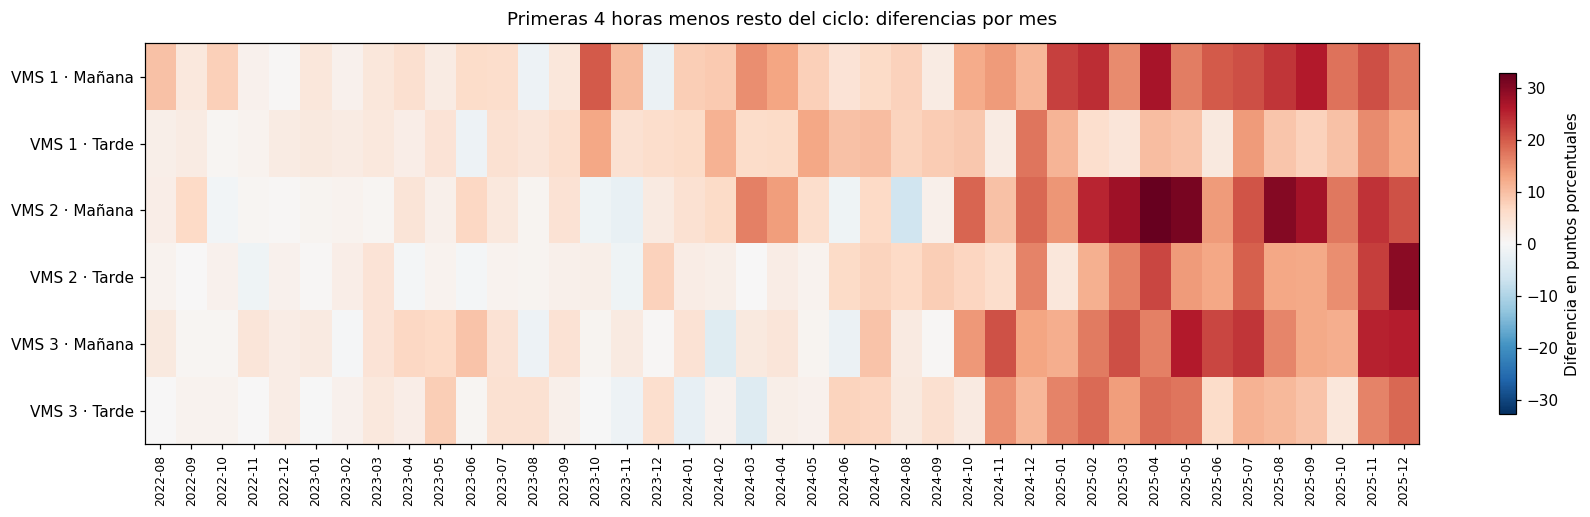

In [ ]:
def alimento_graficar_estabilidad_mensual(estado):
    limite_color = estado["limite_color"]
    matriz = estado["matriz"]
    fig, ax = plt.subplots(figsize=(16, 4.8))
    im = ax.imshow(matriz, aspect="auto", cmap="RdBu_r", vmin=-limite_color, vmax=limite_color)
    ax.set_xticks(range(len(matriz.columns)), matriz.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(len(matriz.index)), [f"{r} · {c.split(' · ')[0]}" for r, c in matriz.index])
    ax.set_title("Primeras 4 horas menos resto del ciclo: diferencias por mes", pad=12)
    fig.colorbar(im, ax=ax, label="Diferencia en puntos porcentuales", shrink=0.85)
    fig.tight_layout()
    return fig


fig = alimento_graficar_estabilidad_mensual(alimento)
plt.show()
plt.close(fig)

La diferencia es positiva en la mayoría de los meses y se intensifica hacia 2025. El patrón se repite, pero su magnitud no es constante entre periodos.

Organiza los contrastes principales por periodo para comparar su magnitud e incertidumbre.

In [ ]:
def alimento_preparar_comparacion_periodos(estado):
    CICLOS = estado["CICLOS"]
    CONTRASTES = estado["CONTRASTES"]
    ROBOTS = estado["ROBOTS"]
    principal = estado["principal"]
    contraste_principal = next(iter(CONTRASTES))
    sub = principal.loc[principal["contraste"].eq(contraste_principal)]
    etiquetas = [(r, c) for r in ROBOTS for c in CICLOS]
    colores_periodo = {
        "Histórico completo": "#3d405b",
        "Entrenamiento": "#087f8c",
        "Validación": "#e38b2c",
        "Prueba": "#a34e9c",
    }
    return {
        "contraste_principal": contraste_principal,
        "sub": sub,
        "etiquetas": etiquetas,
        "colores_periodo": colores_periodo,
    }


alimento.update(alimento_preparar_comparacion_periodos(alimento))

Grafica las diferencias por periodo; el cero representa ausencia de diferencia entre ventanas.

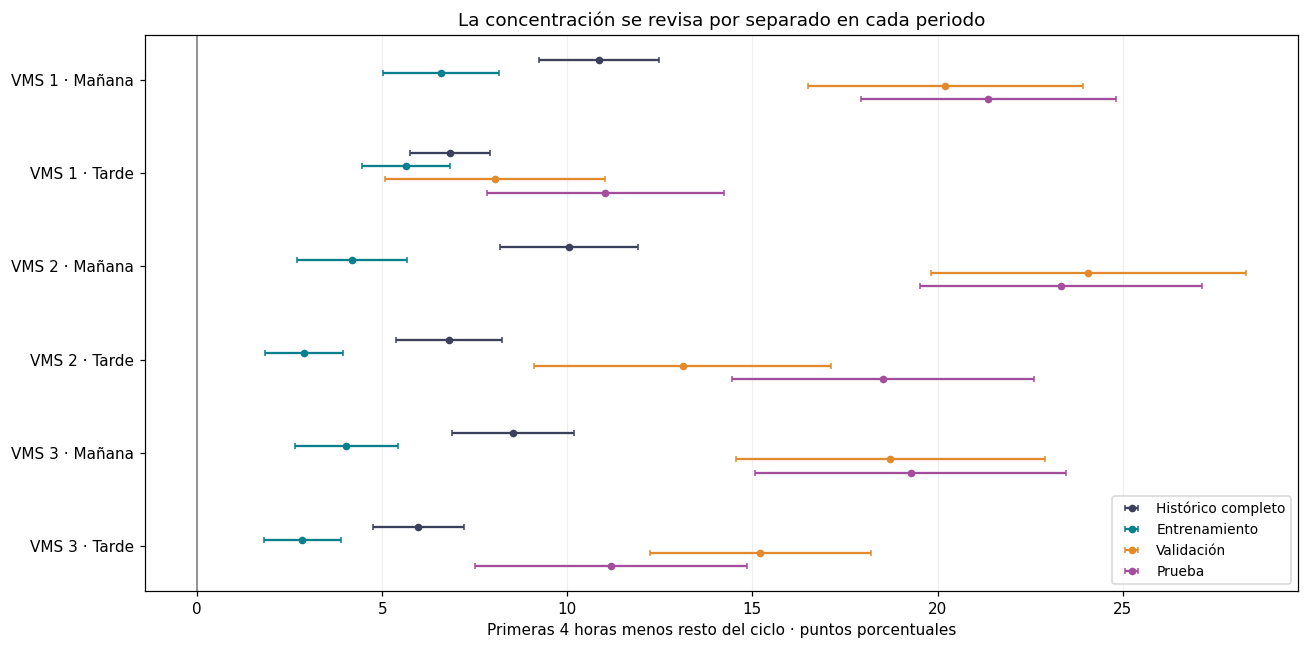

In [ ]:
def alimento_graficar_comparacion_periodos(estado):
    PERIODOS = estado["PERIODOS"]
    colores_periodo = estado["colores_periodo"]
    etiquetas = estado["etiquetas"]
    sub = estado["sub"]
    fig, ax = plt.subplots(figsize=(12, 6))
    for indice, periodo in enumerate(["Histórico completo", *PERIODOS]):
        tabla = sub.loc[sub["periodo"].eq(periodo)].set_index(["ms", "ciclo"]).reindex(etiquetas)
        y = np.arange(len(etiquetas)) + (indice - 1.5) * 0.14
        x = tabla["diferencia_pp"].to_numpy()
        error = np.vstack(
            [x - tabla["ic95_inferior_pp"].to_numpy(), tabla["ic95_superior_pp"].to_numpy() - x]
        )
        ax.errorbar(
            x,
            y,
            xerr=error,
            fmt="o",
            markersize=4,
            capsize=2,
            color=colores_periodo[periodo],
            label=periodo,
        )
    ax.axvline(0, color="#777777", lw=1)
    ax.set_yticks(range(len(etiquetas)), [f"{r} · {c.split(' · ')[0]}" for r, c in etiquetas])
    ax.invert_yaxis()
    ax.set(
        xlabel="Primeras 4 horas menos resto del ciclo · puntos porcentuales",
        title="La concentración se revisa por separado en cada periodo",
    )
    ax.grid(axis="x", alpha=0.2)
    ax.legend(fontsize=9, loc="best")
    fig.tight_layout()
    return fig


fig = alimento_graficar_comparacion_periodos(alimento)
plt.show()
plt.close(fig)

Las diferencias de las primeras cuatro horas son positivas en los tres periodos y mayores en validación y prueba. Se reporta estabilidad de dirección sin asumir una intensidad fija.

Muestra las diferencias y valores p corregidos del contraste principal en entrenamiento, validación y prueba.

In [ ]:
display(
    alimento["principal"].loc[
        alimento["principal"]["periodo"].isin(alimento["PERIODOS"])
        & alimento["principal"]["contraste"].eq("Primeras 4 h vs. resto del ciclo"),
        ["periodo", *alimento["columnas_resultado"]],
    ]
)

,periodo,ms,ciclo,tasa_A_pct,tasa_B_pct,diferencia_pp,ic95_inferior_pp,ic95_superior_pp,p_holm,evidencia_corregida
36,Entrenamiento,VMS 1,Mañana · 07:30,21.6,15.01,6.588,5.016,8.161,1.709e-12,True
38,Entrenamiento,VMS 1,Tarde · 14:30,22.06,16.43,5.636,4.453,6.819,3.696e-15,True
40,Entrenamiento,VMS 2,Mañana · 07:30,16.22,12.03,4.186,2.701,5.671,1.303e-06,True
42,Entrenamiento,VMS 2,Tarde · 14:30,15.38,12.49,2.892,1.836,3.948,2.384e-06,True
44,Entrenamiento,VMS 3,Mañana · 07:30,14.79,10.76,4.033,2.642,5.425,6.983e-07,True
46,Entrenamiento,VMS 3,Tarde · 14:30,14.23,11.39,2.844,1.803,3.885,2.384e-06,True
132,Prueba,VMS 1,Mañana · 07:30,74.13,52.76,21.37,17.92,24.81,7.734e-12,True
134,Prueba,VMS 1,Tarde · 14:30,70.77,59.74,11.03,7.821,14.23,1.103e-06,True
136,Prueba,VMS 2,Mañana · 07:30,69.05,45.72,23.33,19.52,27.13,9.187e-12,True
138,Prueba,VMS 2,Tarde · 14:30,70.03,51.51,18.52,14.44,22.6,5.824e-09,True


Las dieciocho comparaciones de robot, ciclo y periodo tienen diferencia positiva y p corregido < 0.05 con todos los bloques. Esto respalda el contraste horario, no una causa alimentaria.

### 5.7 Sensibilidad a los bloques con ordeños

Exigimos al menos un bloque activo en ambas ventanas. La comparación sigue emparejada dentro del mismo ciclo diario.
Cambian la muestra y los denominadores; esta revisión no cuantifica un efecto causal de la actividad.

Separa la sensibilidad a bloques activos y comprueba el indicador en los bloques sin ordeños.

In [ ]:
def alimento_preparar_sensibilidad_actividad(estado):
    comparaciones = estado["comparaciones"]
    datos = estado["datos"]
    sin_actividad = datos.loc[datos["hubo_ordenios"].eq(0)]
    if sin_actividad["cola"].sum() != 0:
        raise ValueError(
            "Aparecieron positivos en bloques sin ordeños; revisa la definición del indicador."
        )
    sensibilidad = comparaciones.loc[comparaciones["periodo"].eq("Histórico completo")].copy()
    return {"sensibilidad": sensibilidad}


alimento.update(alimento_preparar_sensibilidad_actividad(alimento))

Grafica cómo cambian ambos contrastes al conservar únicamente bloques con ordeños.

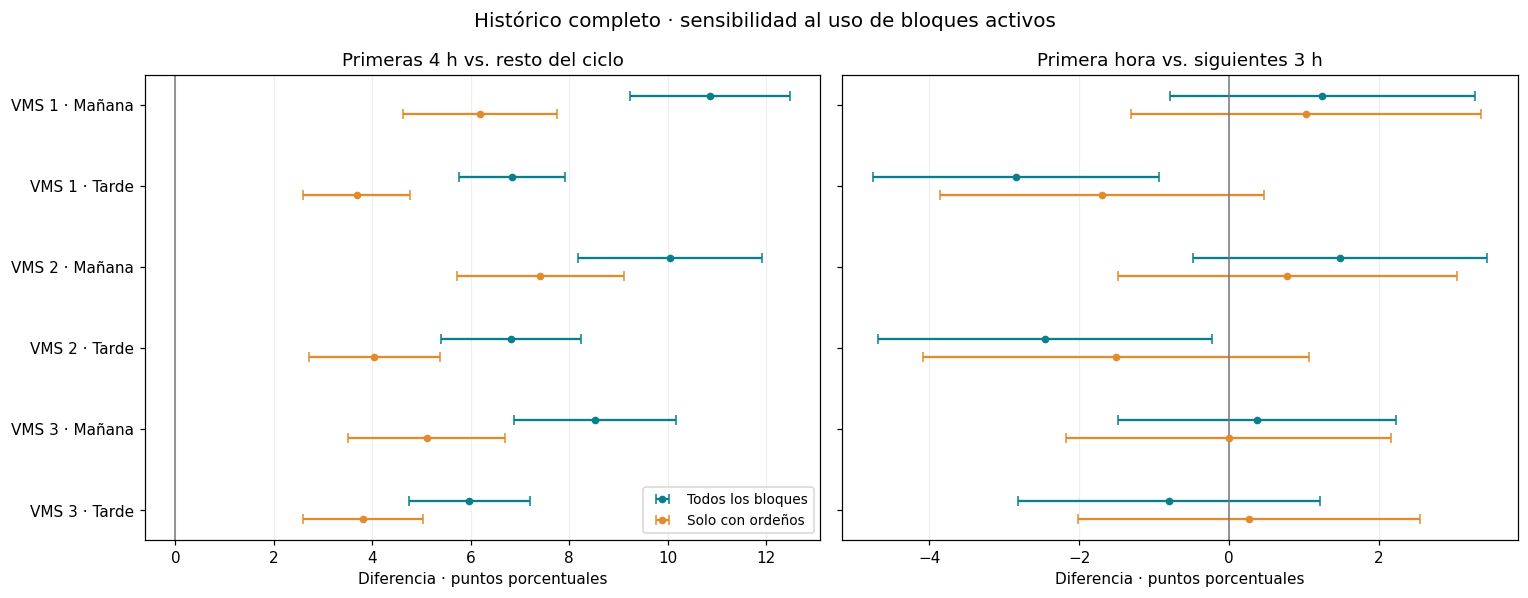

In [ ]:
def alimento_graficar_sensibilidad_actividad(estado):
    CONTRASTES = estado["CONTRASTES"]
    MUESTRAS = estado["MUESTRAS"]
    etiquetas = estado["etiquetas"]
    sensibilidad = estado["sensibilidad"]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
    for ax, contraste in zip(axes, CONTRASTES):
        for indice, muestra in enumerate(MUESTRAS):
            tabla = sensibilidad.loc[
                sensibilidad["contraste"].eq(contraste)
                & sensibilidad["muestra"].eq(muestra)
                & sensibilidad["dias_cluster"].eq(7)
            ]
            tabla = tabla.set_index(["ms", "ciclo"]).reindex(etiquetas)
            x = tabla["diferencia_pp"].to_numpy()
            error = np.vstack(
                [x - tabla["ic95_inferior_pp"].to_numpy(), tabla["ic95_superior_pp"].to_numpy() - x]
            )
            ax.errorbar(
                x,
                np.arange(len(etiquetas)) + (indice - 0.5) * 0.22,
                xerr=error,
                fmt="o",
                capsize=3,
                markersize=4,
                label=muestra,
                color=["#087f8c", "#e38b2c"][indice],
            )
        ax.axvline(0, color="#777777", lw=1)
        ax.set(title=contraste, xlabel="Diferencia · puntos porcentuales")
        ax.grid(axis="x", alpha=0.2)
    axes[0].set_yticks(range(len(etiquetas)), [f"{r} · {c.split(' · ')[0]}" for r, c in etiquetas])
    axes[0].invert_yaxis()
    axes[0].legend(fontsize=9)
    fig.suptitle("Histórico completo · sensibilidad al uso de bloques activos", fontsize=13)
    fig.tight_layout()
    return fig


fig = alimento_graficar_sensibilidad_actividad(alimento)
plt.show()
plt.close(fig)

Con solo bloques activos se reduce el contraste, mientras la primera hora sigue sin ser un pico universal. El resultado debe describirse considerando la selección y los denominadores.

Muestra resultados con agrupación semanal y de catorce días para revisar sensibilidad de la evidencia.

In [ ]:
display(
    alimento["sensibilidad"].loc[
        alimento["sensibilidad"]["contraste"].eq("Primeras 4 h vs. resto del ciclo"),
        ["muestra", "dias_cluster", "ms", "ciclo", "ciclos_diarios", "diferencia_pp", "p_holm"],
    ]
)

,muestra,dias_cluster,ms,ciclo,ciclos_diarios,diferencia_pp,p_holm
60,Solo con ordeños,7,VMS 1,Mañana · 07:30,1225,6.187,6.614e-12
61,Solo con ordeños,14,VMS 1,Mañana · 07:30,1225,6.187,4.811e-10
62,Solo con ordeños,7,VMS 1,Tarde · 14:30,1246,3.678,2.686e-09
63,Solo con ordeños,14,VMS 1,Tarde · 14:30,1246,3.678,6.472e-09
64,Solo con ordeños,7,VMS 2,Mañana · 07:30,1231,7.409,4.442e-14
65,Solo con ordeños,14,VMS 2,Mañana · 07:30,1231,7.409,4.811e-10
66,Solo con ordeños,7,VMS 2,Tarde · 14:30,1245,4.037,7.833e-08
67,Solo con ordeños,14,VMS 2,Tarde · 14:30,1245,4.037,1.408e-06
68,Solo con ordeños,7,VMS 3,Mañana · 07:30,1226,5.104,1.708e-08
69,Solo con ordeños,14,VMS 3,Mañana · 07:30,1226,5.104,7.91e-07


El contraste histórico sigue positivo con agrupaciones de siete y catorce días. La sensibilidad respalda la asociación temporal dentro de estos supuestos de dependencia.

### 5.8 Resumen

Selecciona el contraste principal del histórico para resumir los hallazgos sin convertirlos en tiempos de espera.

In [ ]:
def alimento_resumir_hallazgos(estado):
    columnas_resultado = estado["columnas_resultado"]
    contraste_principal = estado["contraste_principal"]
    principal = estado["principal"]
    resumen_cliente = principal.loc[
        principal["periodo"].eq("Histórico completo")
        & principal["contraste"].eq(contraste_principal),
        columnas_resultado,
    ].copy()
    return {"resumen_cliente": resumen_cliente}


alimento.update(alimento_resumir_hallazgos(alimento))

Muestra el resumen por robot y ciclo de tasas, diferencias e incertidumbre.

In [ ]:
display(alimento["resumen_cliente"])

,ms,ciclo,tasa_A_pct,tasa_B_pct,diferencia_pp,ic95_inferior_pp,ic95_superior_pp,p_holm,evidencia_corregida
84,VMS 1,Mañana · 07:30,33.54,22.68,10.85,9.227,12.48,4.737e-27,True
86,VMS 1,Tarde · 14:30,33.08,26.25,6.832,5.751,7.913,5.034e-25,True
88,VMS 2,Mañana · 07:30,30.11,20.07,10.04,8.179,11.91,1.002e-19,True
90,VMS 2,Tarde · 14:30,29.65,22.84,6.808,5.385,8.23,1.434e-16,True
92,VMS 3,Mañana · 07:30,27.02,18.49,8.527,6.885,10.17,1.045e-18,True
94,VMS 3,Tarde · 14:30,27.12,21.15,5.973,4.748,7.197,5.211e-17,True


El resumen ubica ventanas históricas de mayor frecuencia por robot. No representa una cola continua de cuatro horas ni demuestra que cambiar la alimentación elimine el patrón.

Veintitrés de las 30 combinaciones cumplen la regla de recurrencia.
Destacan 07:30–11:30 y 14:30–18:30, sin un pico universal en la primera hora.
La variable depende de la hora y no permite aislar un efecto causal del alimento.

## 6. Síntesis

Los pronósticos y los análisis de asociaciones aportan evidencia complementaria sobre la posible cola.

### 6.1 Resumen del alcance

Resume qué aporta cada análisis y el alcance de sus resultados.

In [ ]:
resumen = pd.DataFrame(
    {
        "Análisis": ["ARIMA/SARIMA", "Patrones temporales", "Lactancia", "Alimentación"],
        "Resultado": [
            f"F1 SARIMA: {arima['resultados_globales'].set_index('Modelo').loc['SARIMA', 'F1']:.4f}",
            f"{len(temporal['franjas_interesantes'])} franjas recurrentes",
            f"{len(lactancia['muestra']):,} bloques con etapa conocida",
            f"{len(alimento['interesantes'])} combinaciones recurrentes",
        ],
        "Alcance": [
            "Pronóstico temporal y comparación con referencias",
            "Recurrencia por robot y mes",
            "Asociaciones agregadas por etapa",
            "Asociación con el horario diario",
        ],
    }
)
display(resumen)

,Análisis,Resultado,Alcance
0,ARIMA/SARIMA,F1 SARIMA: 0.7412,Pronóstico temporal y comparación con referencias
1,Patrones temporales,56 franjas recurrentes,Recurrencia por robot y mes
2,Lactancia,"123,040 bloques con etapa conocida",Asociaciones agregadas por etapa
3,Alimentación,23 combinaciones recurrentes,Asociación con el horario diario


El proyecto aporta pronóstico, recurrencia temporal y asociaciones de lactancia y horario. Cada resultado responde a una parte del objetivo; no sustituye la clasificación conjunta fuera de muestra.

### 6.2 Comprobaciones

Comprueba coherencia de umbral, fechas, cobertura y resultados entre los cuatro análisis.

In [ ]:
for estado in [arima, temporal, lactancia, alimento]:
    assert estado["UMBRAL_REAL"] == 0.5
    assert estado["INICIO_VAL"] == calendario["INICIO_VAL"]
    assert estado["INICIO_TEST"] == calendario["INICIO_TEST"]
assert len(temporal["contraste"]) == 144
assert len(alimento["recurrencia"]) == 30
assert lactancia["log_ajustes"]["Convergio"].all()
assert alimento["comparaciones"]["p_holm"].between(0, 1).all()
assert len(alimento["comparaciones"]) == 192
assert alimento["tasas_franjas"].loc[
    alimento["tasas_franjas"]["periodo"].eq("Histórico completo")
    & alimento["tasas_franjas"]["muestra"].eq("Todos los bloques"),
    "bloques",
].sum() == len(base)

### 6.3 Límites y siguientes pasos

Para medir duración física de cola hacen falta tiempos reales de llegada y acceso. Para separar alimento de hora se requieren horarios reales de entrega variables.
Para completar la clasificación conjunta, se debe evaluar un modelo temporal y de lactancia fuera de muestra; aquí las regresiones de lactancia son explicativas.